In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 1 — ENVIRONMENT & PROJECT VERIFICATION
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import torchvision
from pathlib import Path

print("=" * 70)
print("PNEUMONIA DETECTION — ROBUSTNESS EXPERIMENT")
print("=" * 70)

# ------------------------------------------------------------
# 1. PyTorch / Torchvision versions
# ------------------------------------------------------------
print("\n[1] SOFTWARE")
print("PyTorch version     :", torch.__version__)
print("Torchvision version :", torchvision.__version__)

# ------------------------------------------------------------
# 2. CUDA verification
# ------------------------------------------------------------
print("\n[2] GPU / CUDA")

cuda_available = torch.cuda.is_available()

print("CUDA available      :", cuda_available)

if cuda_available:
    print("GPU                 :", torch.cuda.get_device_name(0))
    print("CUDA version        :", torch.version.cuda)
    device = torch.device("cuda")
else:
    print("WARNING: CUDA is not available.")
    device = torch.device("cpu")

print("Selected device     :", device)

# ------------------------------------------------------------
# 3. Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121"
)

MAIN_PROJECT = Path(
    "/content/drive/MyDrive/Pneumonia_Major_Project"
)

BASELINE_MODEL = PROJECT_ROOT / "best_densenet121_stage2.pth"

print("\n[3] PROJECT PATHS")

print("Original model path:")
print(BASELINE_MODEL)

print("\nModel exists:", BASELINE_MODEL.exists())

print("\nMain project exists:", MAIN_PROJECT.exists())

# ------------------------------------------------------------
# 4. Check model file size
# ------------------------------------------------------------

if BASELINE_MODEL.exists():
    size_mb = BASELINE_MODEL.stat().st_size / (1024 ** 2)
    print("Model size: {:.2f} MB".format(size_mb))

print("\n" + "=" * 70)
print("CELL 1 COMPLETE")
print("=" * 70)

Mounted at /content/drive
PNEUMONIA DETECTION — ROBUSTNESS EXPERIMENT

[1] SOFTWARE
PyTorch version     : 2.11.0+cu128
Torchvision version : 0.26.0+cu128

[2] GPU / CUDA
CUDA available      : True
GPU                 : Tesla T4
CUDA version        : 12.8
Selected device     : cuda

[3] PROJECT PATHS
Original model path:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth

Model exists: True

Main project exists: True
Model size: 27.12 MB

CELL 1 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 2 — INSPECT BASELINE CHECKPOINT
# ============================================================

import torch

print("=" * 70)
print("BASELINE CHECKPOINT INSPECTION")
print("=" * 70)

checkpoint = torch.load(
    BASELINE_MODEL,
    map_location="cpu"
)

print("\nCheckpoint type:")
print(type(checkpoint))

# ------------------------------------------------------------
# Inspect checkpoint structure
# ------------------------------------------------------------

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" ", key)

# ------------------------------------------------------------
# Determine state_dict
# ------------------------------------------------------------

if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

print("\nNumber of parameters/tensors:", len(state_dict))

print("\nFirst 15 state_dict keys:")
for key in list(state_dict.keys())[:15]:
    print(" ", key)

# ------------------------------------------------------------
# Inspect classifier-related tensors
# ------------------------------------------------------------

print("\nClassifier-related parameters:")

for key, value in state_dict.items():
    if "classifier" in key:
        print(
            f"{key:<40} "
            f"shape={tuple(value.shape)}"
        )

print("\n" + "=" * 70)
print("CHECKPOINT INSPECTION COMPLETE")
print("=" * 70)

BASELINE CHECKPOINT INSPECTION

Checkpoint type:
<class 'collections.OrderedDict'>

Checkpoint keys:
  features.conv0.weight
  features.norm0.weight
  features.norm0.bias
  features.norm0.running_mean
  features.norm0.running_var
  features.norm0.num_batches_tracked
  features.denseblock1.denselayer1.norm1.weight
  features.denseblock1.denselayer1.norm1.bias
  features.denseblock1.denselayer1.norm1.running_mean
  features.denseblock1.denselayer1.norm1.running_var
  features.denseblock1.denselayer1.norm1.num_batches_tracked
  features.denseblock1.denselayer1.conv1.weight
  features.denseblock1.denselayer1.norm2.weight
  features.denseblock1.denselayer1.norm2.bias
  features.denseblock1.denselayer1.norm2.running_mean
  features.denseblock1.denselayer1.norm2.running_var
  features.denseblock1.denselayer1.norm2.num_batches_tracked
  features.denseblock1.denselayer1.conv2.weight
  features.denseblock1.denselayer2.norm1.weight
  features.denseblock1.denselayer2.norm1.bias
  features.denseblo

**Inspect the existing baseline checkpoint**

**What it does**

Reads the existing best_densenet121_stage2.pth without training and checks its structure, especially the classifier dimensions.

**Why**

We need to reconstruct the exact DenseNet121 architecture compatible with your saved model rather than guessing.

**Technology / method**

PyTorch
torch.load()
DenseNet121 state dictionary
State-dict inspection

**Algorithm**

No learning algorithm is performed here. We are only inspecting the learned parameters.

In [12]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 10.0 MB/s eta 0:00:00


In [13]:
import os
import getpass

kaggle_token = getpass.getpass("Enter your Kaggle API token: ")

os.environ["KAGGLE_API_TOKEN"] = kaggle_token

print("Kaggle API token has been set.")

Enter your Kaggle API token: ··········
Kaggle API token has been set.


In [54]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 2 — DOWNLOAD ORIGINAL CXR DATASET
# ============================================================

import os
from pathlib import Path

# ------------------------------------------------------------
# Dataset used in the original CXR experiment
# ------------------------------------------------------------
DATASET_ID = "reflex7/cxr-data-set"

DOWNLOAD_DIR = Path("/content/cxr_download")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("DOWNLOADING ORIGINAL CXR DATASET")
print("=" * 70)

print("\nDataset:", DATASET_ID)
print("Download directory:", DOWNLOAD_DIR)

# Check Kaggle authentication
print("\nChecking Kaggle authentication...")

auth_check = os.system("kaggle datasets list --max-size 1 > /dev/null 2>&1")

if auth_check != 0:
    raise RuntimeError(
        "Kaggle authentication is not working in this Colab runtime."
    )

print("Kaggle authentication: OK")

# Download and extract
print("\nStarting download...")
print("This dataset is large, so this may take some time.")

os.system(
    f'kaggle datasets download -d "{DATASET_ID}" '
    f'-p "{DOWNLOAD_DIR}" --unzip'
)

print("\nDownload/extraction command completed.")

print("\nTop-level contents:")
for item in sorted(DOWNLOAD_DIR.iterdir()):
    print(" ", item.name)

print("\n" + "=" * 70)
print("CELL 2 COMPLETE")
print("=" * 70)

DOWNLOADING ORIGINAL CXR DATASET

Dataset: reflex7/cxr-data-set
Download directory: /content/cxr_download

Checking Kaggle authentication...
Kaggle authentication: OK

Starting download...
This dataset is large, so this may take some time.

Download/extraction command completed.

Top-level contents:
  Covid
  Normal
  Pneumonia
  Tuberculosis

CELL 2 COMPLETE


In [55]:
# ============================================================
# CELL 25 — LOCATE EXTRACTED CXR DATA
# ============================================================

import os

print("=" * 70)
print("LOCATING EXTRACTED CXR DATASET")
print("=" * 70)

possible_roots = [
    "/content/cxr_download",
    "/content/cxr_data",
    "/content/CXR",
    "/content/cxr",
    "/content"
]

for root in possible_roots:

    if os.path.exists(root):

        print(f"\n✓ EXISTS: {root}")

        try:
            items = os.listdir(root)

            print("Items:", len(items))

            for item in items[:20]:
                print("   ", item)

        except Exception as e:
            print("Cannot inspect:", e)

    else:
        print(f"✗ NOT FOUND: {root}")

print("\nCELL 25 COMPLETE")

LOCATING EXTRACTED CXR DATASET

✓ EXISTS: /content/cxr_download
Items: 4
    Covid
    Normal
    Tuberculosis
    Pneumonia
✗ NOT FOUND: /content/cxr_data
✗ NOT FOUND: /content/CXR
✗ NOT FOUND: /content/cxr

✓ EXISTS: /content
Items: 5
    .config
    cxr_test
    cxr_download
    drive
    sample_data

CELL 25 COMPLETE


In [56]:
# ============================================================
# CELL 26 — LOCATE DUPLICATE-AWARE SPLIT
# ============================================================

import os

print("=" * 70)
print("LOCATING DUPLICATE-AWARE SPLIT")
print("=" * 70)

split_roots = [
    "/content/cxr_robustness_split/duplicate_aware",
    "/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/duplicate_aware_split"
]

for root in split_roots:

    print("\nPATH:")
    print(root)

    if os.path.exists(root):

        print("✓ EXISTS")

        for item in os.listdir(root):
            print("   ", item)

    else:
        print("✗ NOT FOUND")

print("\nCELL 26 COMPLETE")

LOCATING DUPLICATE-AWARE SPLIT

PATH:
/content/cxr_robustness_split/duplicate_aware
✗ NOT FOUND

PATH:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/duplicate_aware_split
✓ EXISTS
    train.csv
    val.csv
    complete_split.csv
    test.csv

CELL 26 COMPLETE


In [57]:
# ============================================================
# CELL 27 — LOAD EXISTING DUPLICATE-AWARE SPLITS
# ============================================================

import os
import pandas as pd

split_root = "/content/cxr_robustness_split/duplicate_aware"

if not os.path.exists(split_root):

    split_root = (
        "/content/drive/MyDrive/"
        "Pneumonia_Major_Project/"
        "results/robustness_experiment/"
        "duplicate_aware_split"
    )

print("=" * 70)
print("LOADING DUPLICATE-AWARE SPLITS")
print("=" * 70)

print("Using:")
print(split_root)

csv_files = {}

for filename in os.listdir(split_root):

    if filename.lower().endswith(".csv"):

        path = os.path.join(
            split_root,
            filename
        )

        df = pd.read_csv(path)

        csv_files[filename] = df

        print(
            f"\n{filename}: {len(df)} rows"
        )

        print(df.columns.tolist())

print("\n✓ Existing split definitions loaded")
print("\nCELL 27 COMPLETE")

LOADING DUPLICATE-AWARE SPLITS
Using:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/duplicate_aware_split

train.csv: 25405 rows
['split', 'image_path', 'label', 'class_name', 'hash']

val.csv: 5440 rows
['split', 'image_path', 'label', 'class_name', 'hash']

complete_split.csv: 36284 rows
['split', 'image_path', 'label', 'class_name', 'hash']

test.csv: 5439 rows
['split', 'image_path', 'label', 'class_name', 'hash']

✓ Existing split definitions loaded

CELL 27 COMPLETE


In [58]:
# ============================================================
# CELL 28 — IDENTIFY VALIDATION AND TEST SPLITS
# ============================================================

print("=" * 70)
print("IDENTIFYING VALIDATION AND TEST SPLITS")
print("=" * 70)

print("\nAvailable CSV files:")

for filename in csv_files:
    print(" -", filename)

# Identify files from their names
validation_candidates = [
    name for name in csv_files
    if "val" in name.lower()
]

test_candidates = [
    name for name in csv_files
    if "test" in name.lower()
]

print("\nValidation candidates:")
for name in validation_candidates:
    print("✓", name)

print("\nTest candidates:")
for name in test_candidates:
    print("✓", name)

if len(validation_candidates) == 0:
    raise FileNotFoundError(
        "Validation split CSV was not found."
    )

if len(test_candidates) == 0:
    raise FileNotFoundError(
        "Test split CSV was not found."
    )

validation_file = validation_candidates[0]
test_file = test_candidates[0]

val_df = csv_files[validation_file].copy()
test_df = csv_files[test_file].copy()

print("\nSelected validation:", validation_file)
print("Selected test      :", test_file)

print("\nValidation images:", len(val_df))
print("Test images      :", len(test_df))

print("\nCELL 28 COMPLETE")

IDENTIFYING VALIDATION AND TEST SPLITS

Available CSV files:
 - train.csv
 - val.csv
 - complete_split.csv
 - test.csv

Validation candidates:
✓ val.csv

Test candidates:
✓ test.csv

Selected validation: val.csv
Selected test      : test.csv

Validation images: 5440
Test images      : 5439

CELL 28 COMPLETE


In [59]:
# ============================================================
# CELL 29 — VERIFY VALIDATION + TEST IMAGE AVAILABILITY
# ============================================================

import os

print("=" * 70)
print("VERIFYING REQUIRED IMAGES")
print("=" * 70)

def check_images(df, split_name):

    available = []
    missing = []

    for path in df["image_path"]:

        if os.path.isfile(path):
            available.append(path)
        else:
            missing.append(path)

    print(f"\n{split_name}")
    print("-" * 50)
    print("Total     :", len(df))
    print("Available :", len(available))
    print("Missing   :", len(missing))

    return available, missing


val_available, val_missing = check_images(
    val_df,
    "VALIDATION"
)

test_available, test_missing = check_images(
    test_df,
    "TEST"
)

print("\n" + "=" * 70)

if len(val_missing) == 0 and len(test_missing) == 0:

    print("✓ ALL REQUIRED IMAGES AVAILABLE")
    print("✓ No additional image loading required")

else:

    print("⚠ SOME IMAGE PATHS ARE NOT AVAILABLE")
    print("Do NOT start calibration/evaluation yet.")

print("\nCELL 29 COMPLETE")

VERIFYING REQUIRED IMAGES

VALIDATION
--------------------------------------------------
Total     : 5440
Available : 5440
Missing   : 0

TEST
--------------------------------------------------
Total     : 5439
Available : 5439
Missing   : 0

✓ ALL REQUIRED IMAGES AVAILABLE
✓ No additional image loading required

CELL 29 COMPLETE


**Find the actual extracted dataset structure**

**Technology**: Python pathlib

**Method:** Recursive filesystem inspection

**Purpose:** We don't assume where Kaggle extracted the datase

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 4 — LOCATE BINARY CXR CLASSES & COUNT IMAGES
# ============================================================

from pathlib import Path

DOWNLOAD_DIR = Path("/content/cxr_download")

# ------------------------------------------------------------
# Search for class directories case-insensitively
# ------------------------------------------------------------

normal_dirs = []
pneumonia_dirs = []

for path in DOWNLOAD_DIR.rglob("*"):
    if not path.is_dir():
        continue

    name = path.name.lower()

    if name == "normal":
        normal_dirs.append(path)

    elif name == "pneumonia":
        pneumonia_dirs.append(path)

print("=" * 70)
print("CXR BINARY CLASS DISCOVERY")
print("=" * 70)

print("\nNORMAL directories:")
for p in normal_dirs:
    print(" ", p)

print("\nPNEUMONIA directories:")
for p in pneumonia_dirs:
    print(" ", p)

# ------------------------------------------------------------
# Count image files
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

def count_images(folder):
    return sum(
        1
        for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

print("\nImage counts:")

for p in normal_dirs:
    print(f"NORMAL     : {count_images(p):,} images -> {p}")

for p in pneumonia_dirs:
    print(f"PNEUMONIA  : {count_images(p):,} images -> {p}")

print("\n" + "=" * 70)
print("CELL 4 COMPLETE")
print("=" * 70)

CXR BINARY CLASS DISCOVERY

NORMAL directories:
  /content/cxr_download/Normal

PNEUMONIA directories:
  /content/cxr_download/Pneumonia

Image counts:
NORMAL     : 18,097 images -> /content/cxr_download/Normal
PNEUMONIA  : 18,187 images -> /content/cxr_download/Pneumonia

CELL 4 COMPLETE


Technology: Python + pathlib
Method: Dataset inventory / class distribution analysis
Purpose: Verify that we are using the correct CXR images and not accidentally mixing datasets.

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 5 — CREATE BINARY CXR IMAGE INDEX
# ============================================================

import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Select the discovered class folders
# ------------------------------------------------------------

if len(normal_dirs) != 1 or len(pneumonia_dirs) != 1:
    raise RuntimeError(
        "Expected exactly one NORMAL and one PNEUMONIA directory. "
        "Please inspect Cell 4 output before continuing."
    )

NORMAL_DIR = normal_dirs[0]
PNEUMONIA_DIR = pneumonia_dirs[0]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

records = []

# ------------------------------------------------------------
# NORMAL = 0
# ------------------------------------------------------------

for path in sorted(NORMAL_DIR.rglob("*")):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        records.append({
            "image_path": str(path),
            "label": 0,
            "class_name": "NORMAL"
        })

# ------------------------------------------------------------
# PNEUMONIA = 1
# ------------------------------------------------------------

for path in sorted(PNEUMONIA_DIR.rglob("*")):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        records.append({
            "image_path": str(path),
            "label": 1,
            "class_name": "PNEUMONIA"
        })

cxr_index = pd.DataFrame(records)

# ------------------------------------------------------------
# Shuffle deterministically
# ------------------------------------------------------------

cxr_index = cxr_index.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("=" * 70)
print("CXR BINARY INDEX")
print("=" * 70)

print("\nTotal images:", len(cxr_index))

print("\nClass distribution:")
print(cxr_index["class_name"].value_counts())

print("\nLabel distribution:")
print(cxr_index["label"].value_counts().sort_index())

print("\nFirst 5 records:")
print(cxr_index.head())

# ------------------------------------------------------------
# Save index
# ------------------------------------------------------------

INDEX_PATH = "/content/cxr_binary_index.csv"

cxr_index.to_csv(INDEX_PATH, index=False)

print("\nIndex saved to:")
print(INDEX_PATH)

print("\n" + "=" * 70)
print("CELL 5 COMPLETE")
print("=" * 70)

CXR BINARY INDEX

Total images: 36284

Class distribution:
class_name
PNEUMONIA    18187
NORMAL       18097
Name: count, dtype: int64

Label distribution:
label
0    18097
1    18187
Name: count, dtype: int64

First 5 records:
                                          image_path  label class_name
0  /content/cxr_download/Pneumonia/PNEUMONIA_450.png      1  PNEUMONIA
1  /content/cxr_download/Normal/01f0f4bf-e678-430...      0     NORMAL
2  /content/cxr_download/Pneumonia/PNEUMONIA(1041...      1  PNEUMONIA
3   /content/cxr_download/Pneumonia/00018187_011.png      1  PNEUMONIA
4   /content/cxr_download/Pneumonia/00006759_001.png      1  PNEUMONIA

Index saved to:
/content/cxr_binary_index.csv

CELL 5 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 6 — RECOVER ORIGINAL CXR TEST SPLIT
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121"
)

MAIN_PROJECT = Path(
    "/content/drive/MyDrive/Pneumonia_Major_Project"
)

print("=" * 70)
print("SEARCHING FOR ORIGINAL CXR SPLIT INFORMATION")
print("=" * 70)

# ------------------------------------------------------------
# Search for likely split-related files
# ------------------------------------------------------------

keywords = [
    "split",
    "test",
    "train",
    "val",
    "validation",
    "dataset",
    "index",
    "manifest",
    "metadata"
]

extensions = {
    ".csv", ".json", ".txt", ".pkl", ".pickle",
    ".pt", ".pth", ".npy", ".npz"
}

found = []

for root in [PROJECT_ROOT, MAIN_PROJECT]:

    if not root.exists():
        continue

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        name = path.name.lower()

        if any(keyword in name for keyword in keywords):
            found.append(path)

# Remove duplicates
found = sorted(set(found))

print("\nPotential split/metadata files found:")

if found:
    for path in found:
        print(" ", path)
else:
    print("  No obvious split files found.")

print("\nTotal candidate files:", len(found))

print("\n" + "=" * 70)
print("CELL 6 COMPLETE")
print("=" * 70)

SEARCHING FOR ORIGINAL CXR SPLIT INFORMATION

Potential split/metadata files found:
  /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/final_test_results.json
  /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/stage2_training_history.json
  /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/test_split.csv
  /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/test_y_pred.npy
  /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/test_y_prob.npy
  /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/test_y_true.npy
  /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/train_split.csv
  /content/drive/.shortcut-targets-

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 7 — INSPECT EXPERIMENT LOGS / RESULTS
# ============================================================

import re
from pathlib import Path

search_roots = [
    Path("/content/drive/.shortcut-targets-by-id/"
         "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
         "Pneumonia_Detection_DenseNet121"),

    Path("/content/drive/MyDrive/Pneumonia_Major_Project")
]

text_extensions = {
    ".txt", ".csv", ".json", ".log", ".md"
}

patterns = [
    r"train",
    r"validation",
    r"test",
    r"split",
    r"random_state",
    r"seed",
    r"test_size",
    r"val_size",
    r"train_size"
]

matches = []

for root in search_roots:

    if not root.exists():
        continue

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in text_extensions:
            continue

        try:
            text = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )
        except Exception:
            continue

        lower_text = text.lower()

        matched_patterns = [
            p for p in patterns
            if re.search(p, lower_text)
        ]

        if matched_patterns:
            matches.append(
                (path, matched_patterns)
            )

print("=" * 70)
print("EXPERIMENT PROVENANCE SEARCH")
print("=" * 70)

if matches:

    for path, matched_patterns in matches:

        print("\nFILE:")
        print(path)

        print("Matched terms:")
        print("  ", ", ".join(matched_patterns))

else:
    print("\nNo relevant experiment logs found.")

print("\n" + "=" * 70)
print("CELL 7 COMPLETE")
print("=" * 70)

EXPERIMENT PROVENANCE SEARCH

FILE:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/train_split.csv
Matched terms:
   test

FILE:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/validation_split.csv
Matched terms:
   test

FILE:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/test_split.csv
Matched terms:
   test

FILE:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/project_config.json
Matched terms:
   train

FILE:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/stage2_training_history.json
Matched terms:
   train

FILE:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/final_test_results.json
Matched terms:
   test

FILE:
/content/drive/.shortcut-ta

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 8 — VERIFY EXISTING DENSENET121 CHECKPOINT
# ============================================================

import torch
from collections import OrderedDict

BASELINE_MODEL = (
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121/"
    "best_densenet121_stage2.pth"
)

print("=" * 70)
print("VERIFYING BASELINE CHECKPOINT")
print("=" * 70)

if not os.path.exists(BASELINE_MODEL):
    raise FileNotFoundError(
        f"Baseline model not found:\n{BASELINE_MODEL}"
    )

checkpoint = torch.load(
    BASELINE_MODEL,
    map_location="cpu"
)

print("\nCheckpoint type:")
print(type(checkpoint))

# ------------------------------------------------------------
# Inspect checkpoint structure
# ------------------------------------------------------------

if isinstance(checkpoint, OrderedDict):

    state_dict = checkpoint

    print("\nCheckpoint is an OrderedDict/state_dict.")
    print("Number of parameter tensors:", len(state_dict))

    print("\nFirst 15 keys:")

    for key in list(state_dict.keys())[:15]:
        print(" ", key)

elif isinstance(checkpoint, dict):

    print("\nCheckpoint is a dictionary.")
    print("Top-level keys:")

    for key in checkpoint.keys():
        print(" ", key)

else:

    print("\nUnexpected checkpoint type.")

print("\n" + "=" * 70)
print("CELL 8 COMPLETE")
print("=" * 70)

VERIFYING BASELINE CHECKPOINT

Checkpoint type:
<class 'collections.OrderedDict'>

Checkpoint is an OrderedDict/state_dict.
Number of parameter tensors: 727

First 15 keys:
  features.conv0.weight
  features.norm0.weight
  features.norm0.bias
  features.norm0.running_mean
  features.norm0.running_var
  features.norm0.num_batches_tracked
  features.denseblock1.denselayer1.norm1.weight
  features.denseblock1.denselayer1.norm1.bias
  features.denseblock1.denselayer1.norm1.running_mean
  features.denseblock1.denselayer1.norm1.running_var
  features.denseblock1.denselayer1.norm1.num_batches_tracked
  features.denseblock1.denselayer1.conv1.weight
  features.denseblock1.denselayer1.norm2.weight
  features.denseblock1.denselayer1.norm2.bias
  features.denseblock1.denselayer1.norm2.running_mean

CELL 8 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 9 — CHECK FOR ORIGINAL DATASET COPY
# ============================================================

from pathlib import Path

possible_dataset_locations = [

    Path("/content/drive/MyDrive/Pneumonia_Major_Project/datasets"),

    Path("/content/drive/.shortcut-targets-by-id/"
         "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
         "datasets"),

    Path("/content/drive/MyDrive")
]

print("=" * 70)
print("SEARCHING FOR ORIGINAL CXR DATASET COPY")
print("=" * 70)

for root in possible_dataset_locations:

    print("\nROOT:")
    print(root)

    if not root.exists():
        print("  Does not exist.")
        continue

    matches = []

    for path in root.rglob("*"):

        if path.is_dir():

            name = path.name.lower()

            if (
                "cxr" in name
                or "chest" in name
                or "pneumonia" in name
            ):
                matches.append(path)

    if matches:

        print("  Possible dataset directories:")

        for path in matches[:30]:
            print("   ", path)

    else:
        print("  No obvious CXR dataset directory found.")

print("\n" + "=" * 70)
print("CELL 9 COMPLETE")
print("=" * 70)

SEARCHING FOR ORIGINAL CXR DATASET COPY

ROOT:
/content/drive/MyDrive/Pneumonia_Major_Project/datasets
  Possible dataset directories:
    /content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany/val/PNEUMONIA
    /content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany/test/PNEUMONIA
    /content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany/train/PNEUMONIA

ROOT:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/datasets
  Does not exist.

ROOT:
/content/drive/MyDrive
  Possible dataset directories:
    /content/drive/MyDrive/Pneumonia_Detection_DenseNet121
    /content/drive/MyDrive/Pneumonia_Major_Project

CELL 9 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 10 — CREATE FIXED STRATIFIED SPLIT
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split
from pathlib import Path

INDEX_PATH = "/content/cxr_binary_index.csv"

cxr_index = pd.read_csv(INDEX_PATH)

print("=" * 70)
print("CREATING FIXED STRATIFIED CXR SPLIT")
print("=" * 70)

# First: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    cxr_index,
    test_size=0.30,
    stratify=cxr_index["label"],
    random_state=42
)

# Second: split remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Add split labels
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

# Combined split file
split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Save locally
SPLIT_DIR = Path("/content/cxr_robustness_split")
SPLIT_DIR.mkdir(exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "val.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)
split_df.to_csv(SPLIT_DIR / "complete_split.csv", index=False)

print("\nDataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClass distribution:")
print(
    split_df.groupby(["split", "class_name"]).size()
)

print("\nSaved to:")
print(SPLIT_DIR)

print("\n" + "=" * 70)
print("CELL 10 COMPLETE")
print("=" * 70)

CREATING FIXED STRATIFIED CXR SPLIT

Dataset sizes:
Train: 25398
Validation: 5443
Test: 5443

Class distribution:
split  class_name
test   NORMAL         2714
       PNEUMONIA      2729
train  NORMAL        12668
       PNEUMONIA     12730
val    NORMAL         2715
       PNEUMONIA      2728
dtype: int64

Saved to:
/content/cxr_robustness_split

CELL 10 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 11 — SAVE FIXED SPLIT TO GOOGLE DRIVE
# ============================================================

import shutil
from pathlib import Path

DRIVE_SPLIT_DIR = Path(
    "/content/drive/MyDrive/Pneumonia_Major_Project/"
    "results/robustness_experiment/split"
)

DRIVE_SPLIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SOURCE_DIR = Path("/content/cxr_robustness_split")

for file in SOURCE_DIR.glob("*.csv"):
    shutil.copy2(
        file,
        DRIVE_SPLIT_DIR / file.name
    )

print("=" * 70)
print("FIXED SPLIT SAVED TO GOOGLE DRIVE")
print("=" * 70)

for file in sorted(DRIVE_SPLIT_DIR.glob("*.csv")):
    print(
        f"{file.name:<20} "
        f"{file.stat().st_size / 1024:.2f} KB"
    )

print("\nDrive location:")
print(DRIVE_SPLIT_DIR)

print("\n" + "=" * 70)
print("CELL 11 COMPLETE")
print("=" * 70)

FIXED SPLIT SAVED TO GOOGLE DRIVE
complete_split.csv   2390.05 KB
test.csv             355.84 KB
train.csv            1684.32 KB
val.csv              349.96 KB

Drive location:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/split

CELL 11 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 12 — CORRECTED BASELINE MODEL LOADING
# ============================================================

import os
import torch
import torch.nn as nn
from torchvision import models

BASELINE_MODEL = (
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121/"
    "best_densenet121_stage2.pth"
)

print("=" * 70)
print("LOADING EXISTING DENSENET121 BASELINE")
print("=" * 70)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# Create DenseNet121
# ------------------------------------------------------------

model = models.densenet121(
    weights=None
)

# IMPORTANT:
# Existing checkpoint has 2-class classifier
model.classifier = nn.Linear(
    model.classifier.in_features,
    2
)

# ------------------------------------------------------------
# Load existing checkpoint
# ------------------------------------------------------------

state_dict = torch.load(
    BASELINE_MODEL,
    map_location="cpu"
)

model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(device)
model.eval()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("\nModel loaded successfully.")

print("Classifier:")
print(model.classifier)

print(
    "\nClassifier weight shape:",
    model.classifier.weight.shape
)

print(
    "Classifier bias shape:",
    model.classifier.bias.shape
)

print(
    "\nTotal parameters:",
    sum(p.numel() for p in model.parameters())
)

print("\nClass mapping:")
print("0 = NORMAL")
print("1 = PNEUMONIA")

print("\n" + "=" * 70)
print("CELL 12 COMPLETE")
print("=" * 70)

LOADING EXISTING DENSENET121 BASELINE

Device: cuda
GPU: Tesla T4

Model loaded successfully.
Classifier:
Linear(in_features=1024, out_features=2, bias=True)

Classifier weight shape: torch.Size([2, 1024])
Classifier bias shape: torch.Size([2])

Total parameters: 6955906

Class mapping:
0 = NORMAL
1 = PNEUMONIA

CELL 12 COMPLETE


Corrected: Load the existing 2-class DenseNet121

Technology: PyTorch + Torchvision + CUDA

Architecture: DenseNet121

Classifier: 2 outputs

Output 0 → NORMAL

Output 1 → PNEUMONIA

Prediction formula:

**This is Softmax, rather than the sigmoid formulation**

For the two logits \(z0,z1):    P(y = i) = exp(z_i) / [exp(z_0) + exp(z_1)]

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 13 — CREATE CLEAN TEST DATALOADER
# ============================================================

import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

TEST_CSV = "/content/cxr_robustness_split/test.csv"

# ------------------------------------------------------------
# Load fixed test split
# ------------------------------------------------------------

test_df = pd.read_csv(TEST_CSV)

print("=" * 70)
print("CREATING CLEAN CXR TEST DATALOADER")
print("=" * 70)

print("\nTest images:", len(test_df))

# ------------------------------------------------------------
# DenseNet121 preprocessing
# ------------------------------------------------------------

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class CXRDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("L")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            row["label"],
            dtype=torch.long
        )

        return image, label


# ------------------------------------------------------------
# Create dataset
# ------------------------------------------------------------

test_dataset = CXRDataset(
    test_df,
    transform=test_transform
)

# ------------------------------------------------------------
# Create DataLoader
# ------------------------------------------------------------

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\nDataset created successfully.")
print("Number of images :", len(test_dataset))
print("Number of batches:", len(test_loader))
print("Batch size       :", 64)
print("Workers          :", 0)

print("\nClass distribution:")
print(
    test_df["class_name"].value_counts()
)

print("\n" + "=" * 70)
print("CELL 13 COMPLETE")
print("=" * 70)

CREATING CLEAN CXR TEST DATALOADER

Test images: 5443

Dataset created successfully.
Number of images : 5443
Number of batches: 86
Batch size       : 64
Workers          : 0

Class distribution:
class_name
PNEUMONIA    2729
NORMAL       2714
Name: count, dtype: int64

CELL 13 COMPLETE


**Create the clean CXR test DataLoader**

**What this doe**s

Loads the fixed CXR test split created earlier and prepares the images in the format expected by DenseNet121.

**Technology**

PyTorch

Torchvision

PIL

DataLoader

Preprocessing method

**Each X-ray goes through:**

Grayscale X-ray
      ↓
      
Convert to 3 channels
      ↓

Resize to 224 × 224
      ↓

Tensor
      ↓

ImageNet normalization
      ↓

DenseNet121

**Normalization formula**:    =   x_normalized = (x - mean) / standard_deviation

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 14 — CLEAN BASELINE EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("CLEAN BASELINE EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# Make sure model is in evaluation mode
# ------------------------------------------------------------

model.eval()

all_labels = []
all_probs = []
all_predictions = []

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(device)

        # DenseNet output
        logits = model(images)

        # Convert logits to probabilities
        probabilities = torch.softmax(
            logits,
            dim=1
        )

        # Pneumonia probability = class 1
        pneumonia_probability = probabilities[:, 1]

        # Predicted class
        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probs.extend(
            pneumonia_probability.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

# ------------------------------------------------------------
# Convert to NumPy
# ------------------------------------------------------------

all_labels = np.array(
    all_labels
).astype(int)

all_probs = np.array(
    all_probs
)

all_predictions = np.array(
    all_predictions
).astype(int)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_labels,
    all_probs
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nCLEAN BASELINE RESULTS")
print("-" * 50)

print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F1-score     : {f1:.4f}")
print(f"ROC-AUC      : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClass mapping:")
print("0 = NORMAL")
print("1 = PNEUMONIA")

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------

baseline_predictions = test_df.copy()

baseline_predictions["pneumonia_probability"] = all_probs
baseline_predictions["prediction"] = all_predictions

RESULT_DIR = (
    "/content/drive/MyDrive/Pneumonia_Major_Project/"
    "results/robustness_experiment"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

baseline_predictions.to_csv(
    f"{RESULT_DIR}/clean_baseline_predictions.csv",
    index=False
)

print("\nPredictions saved:")
print(
    f"{RESULT_DIR}/clean_baseline_predictions.csv"
)

print("\n" + "=" * 70)
print("CELL 14 COMPLETE")
print("=" * 70)

CLEAN BASELINE EVALUATION

CLEAN BASELINE RESULTS
--------------------------------------------------
Accuracy     : 0.9649
Precision    : 0.9707
Recall       : 0.9590
Specificity  : 0.9709
F1-score     : 0.9648
ROC-AUC      : 0.9939

Confusion Matrix:
[[2635   79]
 [ 112 2617]]

Class mapping:
0 = NORMAL
1 = PNEUMONIA

Predictions saved:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/clean_baseline_predictions.csv

CELL 14 COMPLETE


Save the baseline metrics
Why this cell?

Before we perturb anything, we permanently record the clean baseline.

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 16 — CONTROLLED PERTURBATIONS
# ============================================================

import torch
from torchvision import transforms
from PIL import Image, ImageFilter

print("=" * 70)
print("DEFINING CONTROLLED ROBUSTNESS PERTURBATIONS")
print("=" * 70)

# ------------------------------------------------------------
# Perturbation definitions
# ------------------------------------------------------------

perturbations = {

    "brightness_low": transforms.ColorJitter(
        brightness=0.20
    ),

    "brightness_high": transforms.ColorJitter(
        brightness=0.20
    ),

    "contrast_low": transforms.ColorJitter(
        contrast=0.20
    ),

    "contrast_high": transforms.ColorJitter(
        contrast=0.20
    ),

    "rotation": transforms.RandomRotation(
        degrees=5
    ),

    "blur": transforms.GaussianBlur(
        kernel_size=5,
        sigma=(0.1, 1.5)
    )
}

print("\nPerturbations defined:")

for name in perturbations:
    print(" ", name)

print("\nAdditional Gaussian-noise perturbation will be applied")
print("directly to tensors during evaluation.")

print("\n" + "=" * 70)
print("CELL 16 COMPLETE")
print("=" * 70)

DEFINING CONTROLLED ROBUSTNESS PERTURBATIONS

Perturbations defined:
  brightness_low
  brightness_high
  contrast_low
  contrast_high
  rotation
  blur

Additional Gaussian-noise perturbation will be applied
directly to tensors during evaluation.

CELL 16 COMPLETE


**Robustness perturbation functions**

**What it does**

Defines controlled image perturbations.

**Technology**

torchvision.transforms + PIL

**Methods**

Brightness: ±20%

Contrast: ±20%

Gaussian noise

Gaussian blur

Rotation: ±5°

These are deliberately mild, realistic perturbations, not extreme transformations.

**Important correction**

For reproducibility, we don't actually want random ColorJitter here because every evaluation could produce a different perturbation.

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 17 — DETERMINISTIC PERTURBATIONS
# ============================================================

import torch
import torchvision.transforms.functional as TF
from PIL import Image, ImageFilter

print("=" * 70)
print("CREATING DETERMINISTIC ROBUSTNESS TRANSFORMATIONS")
print("=" * 70)


def apply_perturbation(image, perturbation):

    # Convert to PIL grayscale
    if not isinstance(image, Image.Image):
        image = TF.to_pil_image(image)

    image = image.convert("L")

    # --------------------------------------------------------
    # Brightness
    # --------------------------------------------------------

    if perturbation == "brightness_dark":
        image = TF.adjust_brightness(
            image,
            brightness_factor=0.80
        )

    elif perturbation == "brightness_bright":
        image = TF.adjust_brightness(
            image,
            brightness_factor=1.20
        )

    # --------------------------------------------------------
    # Contrast
    # --------------------------------------------------------

    elif perturbation == "contrast_low":
        image = TF.adjust_contrast(
            image,
            contrast_factor=0.80
        )

    elif perturbation == "contrast_high":
        image = TF.adjust_contrast(
            image,
            contrast_factor=1.20
        )

    # --------------------------------------------------------
    # Rotation
    # --------------------------------------------------------

    elif perturbation == "rotation_left":
        image = TF.rotate(
            image,
            angle=5
        )

    elif perturbation == "rotation_right":
        image = TF.rotate(
            image,
            angle=-5
        )

    # --------------------------------------------------------
    # Blur
    # --------------------------------------------------------

    elif perturbation == "blur":
        image = image.filter(
            ImageFilter.GaussianBlur(
                radius=1.5
            )
        )

    return image


perturbation_names = [
    "brightness_dark",
    "brightness_bright",
    "contrast_low",
    "contrast_high",
    "rotation_left",
    "rotation_right",
    "blur"
]

print("\nDeterministic perturbations:")

for p in perturbation_names:
    print(" ", p)

print("\n" + "=" * 70)
print("CELL 17 COMPLETE")
print("=" * 70)

CREATING DETERMINISTIC ROBUSTNESS TRANSFORMATIONS

Deterministic perturbations:
  brightness_dark
  brightness_bright
  contrast_low
  contrast_high
  rotation_left
  rotation_right
  blur

CELL 17 COMPLETE


**Deterministic robustness transformations**

**Why?**

We need exactly reproducible BEFORE/AFTER comparisons.

**For example:**

Baseline model:
brightness +20% → result A

Improved model:
brightness +20% → result B

**Both must receive the same transformation.**

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 18 — PILOT TEST: DARKER IMAGES
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ------------------------------------------------------------
# Standard tensor preprocessing after perturbation
# ------------------------------------------------------------

normalize = transforms.Normalize(
    mean=[0.485, 0.485, 0.485],
    std=[0.229, 0.229, 0.229]
)

def preprocess_perturbed(image):

    image = image.convert("RGB")
    image = image.resize((224, 224))

    tensor = transforms.ToTensor()(image)

    tensor = normalize(tensor)

    return tensor


# ------------------------------------------------------------
# Evaluate brightness-dark
# ------------------------------------------------------------

model.eval()

labels_list = []
probs_list = []
preds_list = []

print("=" * 70)
print("PILOT ROBUSTNESS TEST — DARKER IMAGES")
print("=" * 70)

with torch.no_grad():

    for _, row in test_df.iterrows():

        image = Image.open(
            row["image_path"]
        ).convert("L")

        # Apply deterministic perturbation
        image = apply_perturbation(
            image,
            "brightness_dark"
        )

        tensor = preprocess_perturbed(
            image
        )

        tensor = tensor.unsqueeze(0).to(device)

        logits = model(tensor)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        pneumonia_probability = (
            probabilities[0, 1].item()
        )

        prediction = torch.argmax(
            probabilities,
            dim=1
        ).item()

        labels_list.append(
            int(row["label"])
        )

        probs_list.append(
            pneumonia_probability
        )

        preds_list.append(
            prediction
        )

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

y_true = np.array(labels_list)
y_prob = np.array(probs_list)
y_pred = np.array(preds_list)

accuracy_dark = accuracy_score(
    y_true,
    y_pred
)

precision_dark = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall_dark = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1_dark = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc_dark = roc_auc_score(
    y_true,
    y_prob
)

cm_dark = confusion_matrix(
    y_true,
    y_pred
)

tn_d, fp_d, fn_d, tp_d = cm_dark.ravel()

specificity_dark = (
    tn_d / (tn_d + fp_d)
)

print("\nDARKER IMAGE RESULTS")
print("-" * 50)

print(f"Accuracy     : {accuracy_dark:.4f}")
print(f"Precision    : {precision_dark:.4f}")
print(f"Recall       : {recall_dark:.4f}")
print(f"Specificity  : {specificity_dark:.4f}")
print(f"F1-score     : {f1_dark:.4f}")
print(f"ROC-AUC      : {auc_dark:.4f}")

print("\nConfusion Matrix:")
print(cm_dark)

print("\nAccuracy change from clean:")
print(
    f"{accuracy_dark - accuracy:+.4f}"
)

print("\n" + "=" * 70)
print("CELL 18 COMPLETE")
print("=" * 70)

PILOT ROBUSTNESS TEST — DARKER IMAGES

DARKER IMAGE RESULTS
--------------------------------------------------
Accuracy     : 0.5017
Precision    : 0.5016
Recall       : 1.0000
Specificity  : 0.0007
F1-score     : 0.6681
ROC-AUC      : 0.9017

Confusion Matrix:
[[   2 2712]
 [   0 2729]]

Accuracy change from clean:
-0.4632

CELL 18 COMPLETE


**Test one perturbation first**

**Why?**

This verifies the complete pipeline before spending GPU time on all perturbations.

**Metric**

We'll compare:

Clean accuracy = 96.49%
**vs**
Brightness-dark accuracy = ?


What we're looking for

If you get something like:

Clean accuracy       0.9649
Dark-image accuracy  0.94xx

**hen brightness is causing degradation.**

If the performance barely changes, brightness isn't a major weakness.

### **A 20% brightness reduction causing almost complete collapse is unusually severe. Before building the entire robustness experiment around it, we must validate that the perturbation/preprocessin**g pipeline itself is correct.

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 19 — VALIDATE CLEAN VS DARK PIPELINE
# ============================================================

import numpy as np
import torch
from PIL import Image
from torchvision import transforms

print("=" * 70)
print("VALIDATING CLEAN VS DARK IMAGE PIPELINE")
print("=" * 70)

# ------------------------------------------------------------
# EXACT SAME preprocessing for clean and perturbed images
# ------------------------------------------------------------

common_preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Select 10 representative test images
# ------------------------------------------------------------

sample_df = test_df.sample(
    n=10,
    random_state=42
).reset_index(drop=True)

model.eval()

print("\nComparing 10 images...\n")

for i, row in sample_df.iterrows():

    # Load original
    original = Image.open(
        row["image_path"]
    ).convert("L")

    # Create darker version
    darker = apply_perturbation(
        original,
        "brightness_dark"
    )

    # SAME preprocessing
    clean_tensor = common_preprocess(
        original
    ).unsqueeze(0).to(device)

    dark_tensor = common_preprocess(
        darker
    ).unsqueeze(0).to(device)

    # --------------------------------------------------------
    # Model predictions
    # --------------------------------------------------------

    with torch.no_grad():

        clean_logits = model(
            clean_tensor
        )

        dark_logits = model(
            dark_tensor
        )

        clean_prob = torch.softmax(
            clean_logits,
            dim=1
        )[0, 1].item()

        dark_prob = torch.softmax(
            dark_logits,
            dim=1
        )[0, 1].item()

        clean_pred = torch.argmax(
            clean_logits,
            dim=1
        ).item()

        dark_pred = torch.argmax(
            dark_logits,
            dim=1
        ).item()

    print(
        f"Image {i+1:02d} | "
        f"True={row['label']} | "
        f"Clean P(Pneumonia)={clean_prob:.4f} | "
        f"Dark P(Pneumonia)={dark_prob:.4f} | "
        f"Clean={clean_pred} | "
        f"Dark={dark_pred}"
    )

print("\n" + "=" * 70)
print("CELL 19 COMPLETE")
print("=" * 70)

VALIDATING CLEAN VS DARK IMAGE PIPELINE

Comparing 10 images...

Image 01 | True=1 | Clean P(Pneumonia)=1.0000 | Dark P(Pneumonia)=1.0000 | Clean=1 | Dark=1
Image 02 | True=1 | Clean P(Pneumonia)=0.1391 | Dark P(Pneumonia)=0.2153 | Clean=0 | Dark=0
Image 03 | True=0 | Clean P(Pneumonia)=0.0061 | Dark P(Pneumonia)=0.0307 | Clean=0 | Dark=0
Image 04 | True=1 | Clean P(Pneumonia)=1.0000 | Dark P(Pneumonia)=1.0000 | Clean=1 | Dark=1
Image 05 | True=1 | Clean P(Pneumonia)=0.9966 | Dark P(Pneumonia)=0.9999 | Clean=1 | Dark=1
Image 06 | True=1 | Clean P(Pneumonia)=1.0000 | Dark P(Pneumonia)=1.0000 | Clean=1 | Dark=1
Image 07 | True=0 | Clean P(Pneumonia)=0.0005 | Dark P(Pneumonia)=0.0036 | Clean=0 | Dark=0
Image 08 | True=1 | Clean P(Pneumonia)=1.0000 | Dark P(Pneumonia)=1.0000 | Clean=1 | Dark=1
Image 09 | True=0 | Clean P(Pneumonia)=0.0008 | Dark P(Pneumonia)=0.0059 | Clean=0 | Dark=0
Image 10 | True=1 | Clean P(Pneumonia)=0.9663 | Dark P(Pneumonia)=0.9582 | Clean=1 | Dark=1

CELL 19 COMPLE

**Validate clean vs dark preprocessing**

**What this does**

Takes a small set of images and compares:

Original image → model
against

Same image → 20% darker → model

using exactly the same preprocessing.

Technology
PyTorch
Torchvision
PIL
DenseNet121
Method

Pipeline validation / sanity check.

**Why**

We need to determine whether the dramatic result is genuinely caused by brightness or by a preprocessing mismatch.

# One more important point

### If Cell 19 confirms the collapse, **that is actually useful.**

**It means we have discovered a serious robustness weakness:**

The baseline DenseNet121 has a strong dependence on image brightness.

**Then we can deliberately target that weakness during the improvement phase using brightness/contrast augmentation and later demonstrate**:

In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENT
# CELL 20 — COMPLETE BASELINE ROBUSTNESS EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torchvision.transforms.functional as TF

from PIL import Image, ImageFilter
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("BASELINE ROBUSTNESS EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# EXACT SAME preprocessing for EVERY condition
# ------------------------------------------------------------

def preprocess_image(image):

    image = image.convert("L")
    image = image.resize((224, 224))

    tensor = TF.to_tensor(image)

    # Convert grayscale to 3 channels
    tensor = tensor.repeat(3, 1, 1)

    # Exact ImageNet normalization
    tensor = TF.normalize(
        tensor,
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

    return tensor


# ------------------------------------------------------------
# Deterministic perturbations
# ------------------------------------------------------------

def perturb_image(image, condition):

    image = image.convert("L")

    if condition == "clean":
        return image

    elif condition == "brightness_dark":
        return TF.adjust_brightness(
            image,
            0.80
        )

    elif condition == "brightness_bright":
        return TF.adjust_brightness(
            image,
            1.20
        )

    elif condition == "contrast_low":
        return TF.adjust_contrast(
            image,
            0.80
        )

    elif condition == "contrast_high":
        return TF.adjust_contrast(
            image,
            1.20
        )

    elif condition == "rotation_left":
        return TF.rotate(
            image,
            5
        )

    elif condition == "rotation_right":
        return TF.rotate(
            image,
            -5
        )

    elif condition == "blur":
        return image.filter(
            ImageFilter.GaussianBlur(
                radius=1.5
            )
        )

    else:
        raise ValueError(
            f"Unknown condition: {condition}"
        )


# ------------------------------------------------------------
# Conditions
# ------------------------------------------------------------

conditions = [
    "clean",
    "brightness_dark",
    "brightness_bright",
    "contrast_low",
    "contrast_high",
    "rotation_left",
    "rotation_right",
    "blur"
]

# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_condition(condition):

    labels = []
    probabilities = []
    predictions = []

    for _, row in test_df.iterrows():

        image = Image.open(
            row["image_path"]
        ).convert("L")

        image = perturb_image(
            image,
            condition
        )

        tensor = preprocess_image(
            image
        )

        tensor = tensor.unsqueeze(0).to(device)

        with torch.no_grad():

            logits = model(tensor)

            probs = torch.softmax(
                logits,
                dim=1
            )

            pneumonia_prob = probs[0, 1].item()

            prediction = torch.argmax(
                probs,
                dim=1
            ).item()

        labels.append(
            int(row["label"])
        )

        probabilities.append(
            pneumonia_prob
        )

        predictions.append(
            prediction
        )

    y_true = np.array(labels)
    y_prob = np.array(probabilities)
    y_pred = np.array(predictions)

    accuracy_value = accuracy_score(
        y_true,
        y_pred
    )

    precision_value = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall_value = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1_value = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc_value = roc_auc_score(
        y_true,
        y_prob
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    tn, fp, fn, tp = cm.ravel()

    specificity_value = (
        tn / (tn + fp)
    )

    return {
        "condition": condition,
        "accuracy": accuracy_value,
        "precision": precision_value,
        "recall": recall_value,
        "specificity": specificity_value,
        "f1_score": f1_value,
        "roc_auc": auc_value,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# ------------------------------------------------------------
# Run all conditions
# ------------------------------------------------------------

results = []

for condition in conditions:

    print(
        f"\nEvaluating: {condition}"
    )

    result = evaluate_condition(
        condition
    )

    results.append(result)

    print(
        f"Accuracy = {result['accuracy']:.4f} | "
        f"Recall = {result['recall']:.4f} | "
        f"Specificity = {result['specificity']:.4f} | "
        f"AUC = {result['roc_auc']:.4f}"
    )


# ------------------------------------------------------------
# Create results dataframe
# ------------------------------------------------------------

robustness_df = pd.DataFrame(
    results
)

# ------------------------------------------------------------
# Calculate degradation relative to clean
# ------------------------------------------------------------

clean_accuracy = robustness_df.loc[
    robustness_df["condition"] == "clean",
    "accuracy"
].iloc[0]

robustness_df["accuracy_change"] = (
    robustness_df["accuracy"]
    - clean_accuracy
)

robustness_df["accuracy_degradation"] = (
    clean_accuracy
    - robustness_df["accuracy"]
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

RESULT_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

results_path = (
    f"{RESULT_DIR}/"
    "baseline_robustness_results.csv"
)

robustness_df.to_csv(
    results_path,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("BASELINE ROBUSTNESS RESULTS")
print("=" * 70)

print(
    robustness_df[
        [
            "condition",
            "accuracy",
            "precision",
            "recall",
            "specificity",
            "f1_score",
            "roc_auc",
            "accuracy_degradation"
        ]
    ].to_string(index=False)
)

print("\nSaved to:")
print(results_path)

print("\n" + "=" * 70)
print("CELL 20 COMPLETE")
print("=" * 70)

BASELINE ROBUSTNESS EVALUATION

Evaluating: clean
Accuracy = 0.9627 | Recall = 0.9549 | Specificity = 0.9705 | AUC = 0.9933

Evaluating: brightness_dark
Accuracy = 0.9577 | Recall = 0.9685 | Specificity = 0.9469 | AUC = 0.9925

Evaluating: brightness_bright
Accuracy = 0.9456 | Recall = 0.9557 | Specificity = 0.9355 | AUC = 0.9886

Evaluating: contrast_low
Accuracy = 0.9614 | Recall = 0.9557 | Specificity = 0.9672 | AUC = 0.9933

Evaluating: contrast_high
Accuracy = 0.9611 | Recall = 0.9494 | Specificity = 0.9727 | AUC = 0.9921

Evaluating: rotation_left
Accuracy = 0.9629 | Recall = 0.9571 | Specificity = 0.9687 | AUC = 0.9931

Evaluating: rotation_right
Accuracy = 0.9633 | Recall = 0.9582 | Specificity = 0.9683 | AUC = 0.9935

Evaluating: blur
Accuracy = 0.9482 | Recall = 0.9502 | Specificity = 0.9462 | AUC = 0.9895


BASELINE ROBUSTNESS RESULTS
        condition  accuracy  precision   recall  specificity  f1_score  roc_auc  accuracy_degradation
            clean  0.962704   0.970216 0

**Correct robustness evaluator**

**This cell will evaluate clean + 7 controlled perturbations using the exact same preprocessing.**

Perturbations:
1. Clean
2. Brightness -20%
3. Brightness +20%
4. Contrast -20%
5. Contrast +20%
6. Rotation +5°
7. Rotation -5°
8. Gaussian blur

**We will calculate:**

Accuracy,
Precision,
Recall,
Specificity,
F1,
ROC-AUC.

**Accuracy degradation = Clean Accuracy - Perturbed Accuracy**

In [ ]:
# ============================================================
# ROBUSTNESS IMPROVEMENT
# CELL 21 — FINAL PRE-TRAINING VERIFICATION
# ============================================================

import os
import torch
import pandas as pd
from pathlib import Path

print("=" * 70)
print("FINAL PRE-TRAINING VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

TRAIN_CSV = "/content/cxr_robustness_split/train.csv"
VAL_CSV   = "/content/cxr_robustness_split/val.csv"

BASELINE_MODEL = (
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121/"
    "best_densenet121_stage2.pth"
)

ROBUST_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "robustness_improvement"
)

os.makedirs(ROBUST_DIR, exist_ok=True)

# ------------------------------------------------------------
# Check files
# ------------------------------------------------------------

print("\n[1] DATA FILES")

for path in [TRAIN_CSV, VAL_CSV, BASELINE_MODEL]:

    exists = os.path.exists(path)

    print(
        f"{'FOUND' if exists else 'MISSING'} : {path}"
    )

    if not exists:
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# Load split information
# ------------------------------------------------------------

train_df_check = pd.read_csv(TRAIN_CSV)
val_df_check = pd.read_csv(VAL_CSV)

print("\n[2] DATASET")

print("Training images  :", len(train_df_check))
print("Validation images:", len(val_df_check))

print("\nTraining distribution:")
print(
    train_df_check["class_name"].value_counts()
)

print("\nValidation distribution:")
print(
    val_df_check["class_name"].value_counts()
)

# ------------------------------------------------------------
# Check image paths
# ------------------------------------------------------------

print("\n[3] IMAGE PATH CHECK")

train_missing = (
    ~train_df_check["image_path"]
    .map(os.path.exists)
).sum()

val_missing = (
    ~val_df_check["image_path"]
    .map(os.path.exists)
).sum()

print("Missing train images:", train_missing)
print("Missing val images  :", val_missing)

if train_missing > 0 or val_missing > 0:
    raise RuntimeError(
        "Some dataset image paths are missing."
    )

# ------------------------------------------------------------
# GPU verification
# ------------------------------------------------------------

print("\n[4] COMPUTE DEVICE")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

print("\n[5] PLANNED ROBUSTNESS TRAINING")

config = {
    "architecture": "DenseNet121",
    "task": "Binary classification",
    "class_0": "NORMAL",
    "class_1": "PNEUMONIA",
    "optimizer": "AdamW",
    "learning_rate": 1e-5,
    "weight_decay": 1e-4,
    "batch_size": 64,
    "max_epochs": 15,
    "early_stopping_patience": 4,
    "augmentation": [
        "Brightness variation",
        "Contrast variation",
        "Gaussian blur",
        "Mild rotation"
    ],
    "test_set_used_for_training": False,
    "baseline_overwritten": False
}

for key, value in config.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------

config_df = pd.DataFrame(
    list(config.items()),
    columns=["parameter", "value"]
)

config_df.to_csv(
    f"{ROBUST_DIR}/training_configuration.csv",
    index=False
)

print("\nConfiguration saved to:")
print(
    f"{ROBUST_DIR}/training_configuration.csv"
)

print("\n" + "=" * 70)
print("CELL 21 COMPLETE — READY FOR TRAINING")
print("=" * 70)

FINAL PRE-TRAINING VERIFICATION

[1] DATA FILES
FOUND : /content/cxr_robustness_split/train.csv
FOUND : /content/cxr_robustness_split/val.csv
FOUND : /content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth

[2] DATASET
Training images  : 25398
Validation images: 5443

Training distribution:
class_name
PNEUMONIA    12730
NORMAL       12668
Name: count, dtype: int64

Validation distribution:
class_name
PNEUMONIA    2728
NORMAL       2715
Name: count, dtype: int64

[3] IMAGE PATH CHECK
Missing train images: 0
Missing val images  : 0

[4] COMPUTE DEVICE
Device: cuda
GPU: Tesla T4

[5] PLANNED ROBUSTNESS TRAINING
architecture: DenseNet121
task: Binary classification
class_0: NORMAL
class_1: PNEUMONIA
optimizer: AdamW
learning_rate: 1e-05
weight_decay: 0.0001
batch_size: 64
max_epochs: 15
early_stopping_patience: 4
augmentation: ['Brightness variation', 'Contrast variation', 'Gaussian blur', 'Mild rotation']
test_se

**Final pre-training verification**

**What it does**

Verifies that everything required for the one and only robustness fine-tuning run is ready.

**Training strategy**

We will use robustness-aware data

**augmentation:**

Brightness variation,

Contrast variation

Gaussian blur

Mild rotation

**The important weaknesses discovered were:**

Brightness +20% → 1.71% accuracy degradation

Blur            → 1.45% accuracy degradation

**So brightness and blur receive particular attention.**

**Why learning_rate = 1e-5**?

We're fine-tuning an already strong model, not training DenseNet121 from scratch.

A smaller learning rate reduces the risk of destroying the useful features already learned.

**Why AdamW?**

AdamW performs adaptive optimization with decoupled weight decay.

Conceptually:   θ_new = θ_old - learning_rate × gradient_update

# **Check duplicate overlap between train/validation/test**

**What it does**

Computes an MD5 hash for every image and checks whether the exact same image occurs in more than one split.

**Technology**

Python hashlib

MD5 image-content hashing

Pandas

In [ ]:
# ============================================================
# ROBUSTNESS IMPROVEMENT
# CELL 22 — EXACT DUPLICATE LEAKAGE CHECK
# ============================================================

import hashlib
import os
import pandas as pd
from tqdm.auto import tqdm

print("=" * 70)
print("CHECKING DUPLICATE LEAKAGE BETWEEN DATA SPLITS")
print("=" * 70)

# ------------------------------------------------------------
# Load fixed splits
# ------------------------------------------------------------

train_df = pd.read_csv(
    "/content/cxr_robustness_split/train.csv"
)

val_df = pd.read_csv(
    "/content/cxr_robustness_split/val.csv"
)

test_df = pd.read_csv(
    "/content/cxr_robustness_split/test.csv"
)

split_data = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

print("\nImages:")
for name, df in split_data.items():
    print(f"{name:<12}: {len(df)}")


# ------------------------------------------------------------
# MD5 hash function
# ------------------------------------------------------------

def get_file_hash(path):

    md5 = hashlib.md5()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            md5.update(chunk)

    return md5.hexdigest()


# ------------------------------------------------------------
# Calculate hashes
# ------------------------------------------------------------

all_records = []

print("\nCalculating image hashes...")

for split_name, df in split_data.items():

    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc=f"Hashing {split_name}"
    ):

        path = row["image_path"]

        image_hash = get_file_hash(path)

        all_records.append({
            "split": split_name,
            "image_path": path,
            "label": int(row["label"]),
            "class_name": row["class_name"],
            "hash": image_hash
        })


hash_df = pd.DataFrame(
    all_records
)


# ------------------------------------------------------------
# Find hashes appearing in multiple splits
# ------------------------------------------------------------

hash_split_counts = (
    hash_df
    .groupby("hash")["split"]
    .nunique()
)

cross_split_hashes = hash_split_counts[
    hash_split_counts > 1
].index

cross_split_df = hash_df[
    hash_df["hash"].isin(
        cross_split_hashes
    )
].sort_values("hash")


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DUPLICATE LEAKAGE RESULTS")
print("=" * 70)

print(
    "\nUnique image hashes:",
    hash_df["hash"].nunique()
)

print(
    "Total images:",
    len(hash_df)
)

print(
    "Exact duplicate groups:",
    (hash_df["hash"].value_counts() > 1).sum()
)

print(
    "Cross-split duplicate groups:",
    len(cross_split_hashes)
)

print(
    "Images involved in cross-split duplicates:",
    len(cross_split_df)
)


# ------------------------------------------------------------
# Pairwise overlap
# ------------------------------------------------------------

print("\nPAIRWISE CROSS-SPLIT OVERLAP")

split_pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for split_a, split_b in split_pairs:

    hashes_a = set(
        hash_df.loc[
            hash_df["split"] == split_a,
            "hash"
        ]
    )

    hashes_b = set(
        hash_df.loc[
            hash_df["split"] == split_b,
            "hash"
        ]
    )

    overlap = hashes_a.intersection(
        hashes_b
    )

    print(
        f"{split_a:<12} ↔ {split_b:<12}: "
        f"{len(overlap)} duplicate groups"
    )


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

DUP_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "duplicate_analysis"
)

os.makedirs(
    DUP_DIR,
    exist_ok=True
)

hash_df.to_csv(
    f"{DUP_DIR}/image_hashes.csv",
    index=False
)

cross_split_df.to_csv(
    f"{DUP_DIR}/cross_split_duplicates.csv",
    index=False
)

print("\nResults saved to:")
print(DUP_DIR)

print("\n" + "=" * 70)
print("CELL 22 COMPLETE")
print("=" * 70)

CHECKING DUPLICATE LEAKAGE BETWEEN DATA SPLITS

Images:
train       : 25398
validation  : 5443
test        : 5443

Calculating image hashes...


Hashing train:   0%|          | 0/25398 [00:00<?, ?it/s]

Hashing validation:   0%|          | 0/5443 [00:00<?, ?it/s]

Hashing test:   0%|          | 0/5443 [00:00<?, ?it/s]


DUPLICATE LEAKAGE RESULTS

Unique image hashes: 30283
Total images: 36284
Exact duplicate groups: 5912
Cross-split duplicate groups: 2764
Images involved in cross-split duplicates: 5587

PAIRWISE CROSS-SPLIT OVERLAP
train        ↔ validation  : 1250 duplicate groups
train        ↔ test        : 1235 duplicate groups
validation   ↔ test        : 297 duplicate groups

Results saved to:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/duplicate_analysis

CELL 22 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS IMPROVEMENT
# CELL 23 — DUPLICATE-GROUP-AWARE STRATIFIED SPLIT
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

print("=" * 70)
print("CREATING DUPLICATE-GROUP-AWARE SPLIT")
print("=" * 70)

# ------------------------------------------------------------
# Load hash information created in Cell 22
# ------------------------------------------------------------

HASH_FILE = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "duplicate_analysis/"
    "image_hashes.csv"
)

hash_df = pd.read_csv(HASH_FILE)

print("\nTotal images:", len(hash_df))
print("Unique image groups:", hash_df["hash"].nunique())

# ------------------------------------------------------------
# Create one record per unique image group
# ------------------------------------------------------------

groups = (
    hash_df
    .groupby("hash")
    .agg(
        label=("label", "first"),
        class_name=("class_name", "first"),
        group_size=("hash", "size")
    )
    .reset_index()
)

print("\nUnique duplicate groups:", len(groups))

print("\nGroup class distribution:")
print(
    groups["class_name"].value_counts()
)

# ------------------------------------------------------------
# First split:
# 70% groups → train
# 30% groups → temporary
# ------------------------------------------------------------

train_groups, temp_groups = train_test_split(
    groups,
    test_size=0.30,
    stratify=groups["label"],
    random_state=42
)

# ------------------------------------------------------------
# Second split:
# temporary → 50% validation / 50% test
# ------------------------------------------------------------

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    stratify=temp_groups["label"],
    random_state=42
)

# ------------------------------------------------------------
# Assign each hash to a split
# ------------------------------------------------------------

train_hashes = set(
    train_groups["hash"]
)

val_hashes = set(
    val_groups["hash"]
)

test_hashes = set(
    test_groups["hash"]
)

assert len(
    train_hashes &
    val_hashes
) == 0

assert len(
    train_hashes &
    test_hashes
) == 0

assert len(
    val_hashes &
    test_hashes
) == 0

print("\nGroup-level overlap:")
print("Train ↔ Validation:", len(train_hashes & val_hashes))
print("Train ↔ Test       :", len(train_hashes & test_hashes))
print("Validation ↔ Test  :", len(val_hashes & test_hashes))

# ------------------------------------------------------------
# Assign original images to their group's split
# ------------------------------------------------------------

def assign_split(image_hash):

    if image_hash in train_hashes:
        return "train"

    if image_hash in val_hashes:
        return "validation"

    if image_hash in test_hashes:
        return "test"

    raise ValueError(
        f"Hash not assigned: {image_hash}"
    )


split_df = hash_df.copy()

split_df["split"] = (
    split_df["hash"]
    .map(assign_split)
)

# ------------------------------------------------------------
# Verify every image received exactly one split
# ------------------------------------------------------------

assert (
    split_df["split"].notna().all()
)

# ------------------------------------------------------------
# Display final distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL IMAGE DISTRIBUTION")
print("=" * 70)

print(
    split_df.groupby(
        ["split", "class_name"]
    ).size()
)

print("\nTotal images per split:")

print(
    split_df["split"].value_counts()
)

# ------------------------------------------------------------
# Save new split
# ------------------------------------------------------------

SPLIT_DIR = (
    "/content/cxr_robustness_split/"
    "duplicate_aware"
)

os.makedirs(
    SPLIT_DIR,
    exist_ok=True
)

train_final = split_df[
    split_df["split"] == "train"
].copy()

val_final = split_df[
    split_df["split"] == "validation"
].copy()

test_final = split_df[
    split_df["split"] == "test"
].copy()

train_final.to_csv(
    f"{SPLIT_DIR}/train.csv",
    index=False
)

val_final.to_csv(
    f"{SPLIT_DIR}/val.csv",
    index=False
)

test_final.to_csv(
    f"{SPLIT_DIR}/test.csv",
    index=False
)

split_df.to_csv(
    f"{SPLIT_DIR}/complete_split.csv",
    index=False
)

print("\nSaved duplicate-aware split to:")
print(SPLIT_DIR)

# ------------------------------------------------------------
# Save to Google Drive
# ------------------------------------------------------------

DRIVE_SPLIT_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "duplicate_aware_split"
)

os.makedirs(
    DRIVE_SPLIT_DIR,
    exist_ok=True
)

for filename in [
    "train.csv",
    "val.csv",
    "test.csv",
    "complete_split.csv"
]:

    source = f"{SPLIT_DIR}/{filename}"
    destination = f"{DRIVE_SPLIT_DIR}/{filename}"

    import shutil

    shutil.copy2(
        source,
        destination
    )

print("\nDrive copy saved to:")
print(DRIVE_SPLIT_DIR)

print("\n" + "=" * 70)
print("CELL 23 COMPLETE")
print("=" * 70)

CREATING DUPLICATE-GROUP-AWARE SPLIT

Total images: 36284
Unique image groups: 30283

Unique duplicate groups: 30283

Group class distribution:
class_name
NORMAL       16441
PNEUMONIA    13842
Name: count, dtype: int64

Group-level overlap:
Train ↔ Validation: 0
Train ↔ Test       : 0
Validation ↔ Test  : 0

FINAL IMAGE DISTRIBUTION
split       class_name
test        NORMAL         2720
            PNEUMONIA      2719
train       NORMAL        12660
            PNEUMONIA     12745
validation  NORMAL         2717
            PNEUMONIA      2723
dtype: int64

Total images per split:
split
train         25405
validation     5440
test           5439
Name: count, dtype: int64

Saved duplicate-aware split to:
/content/cxr_robustness_split/duplicate_aware

Drive copy saved to:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/duplicate_aware_split

CELL 23 COMPLETE


In [ ]:
# ============================================================
# ROBUSTNESS IMPROVEMENT
# CELL 24 — FINAL IMAGE-LEVEL LEAKAGE VERIFICATION
# ============================================================

import pandas as pd

SPLIT_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "duplicate_aware_split"
)

train_check = pd.read_csv(
    f"{SPLIT_DIR}/train.csv"
)

val_check = pd.read_csv(
    f"{SPLIT_DIR}/val.csv"
)

test_check = pd.read_csv(
    f"{SPLIT_DIR}/test.csv"
)

train_hashes = set(train_check["hash"])
val_hashes   = set(val_check["hash"])
test_hashes  = set(test_check["hash"])

train_val = train_hashes & val_hashes
train_test = train_hashes & test_hashes
val_test = val_hashes & test_hashes

print("=" * 70)
print("FINAL IMAGE-LEVEL LEAKAGE VERIFICATION")
print("=" * 70)

print("\nImages:")
print("Train      :", len(train_check))
print("Validation :", len(val_check))
print("Test       :", len(test_check))

print("\nUnique hashes:")
print("Train      :", len(train_hashes))
print("Validation :", len(val_hashes))
print("Test       :", len(test_hashes))

print("\nCross-split duplicate overlap:")
print(
    "Train ↔ Validation:",
    len(train_val)
)

print(
    "Train ↔ Test       :",
    len(train_test)
)

print(
    "Validation ↔ Test  :",
    len(val_test)
)

# ------------------------------------------------------------
# Final safety assertion
# ------------------------------------------------------------

assert len(train_val) == 0
assert len(train_test) == 0
assert len(val_test) == 0

print("\n" + "=" * 70)
print("✓ NO CROSS-SPLIT EXACT DUPLICATE LEAKAGE")
print("✓ DATA SPLIT IS SAFE FOR TRAINING")
print("✓ READY FOR ROBUSTNESS FINE-TUNING")
print("=" * 70)

print("\nCELL 24 COMPLETE")

FINAL IMAGE-LEVEL LEAKAGE VERIFICATION

Images:
Train      : 25405
Validation : 5440
Test       : 5439

Unique hashes:
Train      : 21198
Validation : 4542
Test       : 4543

Cross-split duplicate overlap:
Train ↔ Validation: 0
Train ↔ Test       : 0
Validation ↔ Test  : 0

✓ NO CROSS-SPLIT EXACT DUPLICATE LEAKAGE
✓ DATA SPLIT IS SAFE FOR TRAINING
✓ READY FOR ROBUSTNESS FINE-TUNING

CELL 24 COMPLETE


In [ ]:
# ============================================================
# CELL 25 — LOAD FINAL DUPLICATE-AWARE SPLITS
# ============================================================

import os
import pandas as pd

SPLIT_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "duplicate_aware_split"
)

train_df = pd.read_csv(
    f"{SPLIT_DIR}/train.csv"
)

val_df = pd.read_csv(
    f"{SPLIT_DIR}/val.csv"
)

test_df = pd.read_csv(
    f"{SPLIT_DIR}/test.csv"
)

print("=" * 70)
print("FINAL ROBUSTNESS TRAINING DATA")
print("=" * 70)

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print(f"\n{name}")
    print("-" * 40)
    print("Images:", len(df))

    print(
        df["class_name"].value_counts()
    )

print("\nClass mapping:")
print("0 = NORMAL")
print("1 = PNEUMONIA")

print("\n✓ Duplicate-aware split loaded")
print("✓ Test set remains untouched")

print("\nCELL 25 COMPLETE")

FINAL ROBUSTNESS TRAINING DATA

TRAIN
----------------------------------------
Images: 25405
class_name
PNEUMONIA    12745
NORMAL       12660
Name: count, dtype: int64

VALIDATION
----------------------------------------
Images: 5440
class_name
PNEUMONIA    2723
NORMAL       2717
Name: count, dtype: int64

TEST
----------------------------------------
Images: 5439
class_name
NORMAL       2720
PNEUMONIA    2719
Name: count, dtype: int64

Class mapping:
0 = NORMAL
1 = PNEUMONIA

✓ Duplicate-aware split loaded
✓ Test set remains untouched

CELL 25 COMPLETE


**Load duplicate-aware splits and inspect distribution**

**What it does**

Loads the leakage-free train/validation/test splits and verifies class balance.

**Why**

We need to establish exactly what data the robustness training will use.

In [ ]:
# ============================================================
# CELL 26 — ROBUSTNESS-AWARE TRAINING AUGMENTATION
# ============================================================

import torch
from torchvision import transforms

IMG_SIZE = 224

# ------------------------------------------------------------
# Robustness-aware training transformations
# ------------------------------------------------------------

train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.Grayscale(
        num_output_channels=3
    ),

    # Mild geometric variation
    transforms.RandomRotation(
        degrees=5
    ),

    # Brightness and contrast robustness
    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.20,
                contrast=0.20,
                saturation=0.0,
                hue=0.0
            )
        ],
        p=0.70
    ),

    # Image-quality robustness
    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=5,
                sigma=(0.5, 1.5)
            )
        ],
        p=0.30
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Validation / test preprocessing
# NO augmentation
# ------------------------------------------------------------

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("=" * 70)
print("ROBUSTNESS-AWARE AUGMENTATION READY")
print("=" * 70)

print("""
Training:
  • Random rotation: ±5°
  • Brightness variation: ±20%
  • Contrast variation: ±20%
  • Gaussian blur: sigma 0.5–1.5
  • Augmentations applied probabilistically

Validation:
  • NO augmentation

Test:
  • NO augmentation
""")

print("CELL 26 COMPLETE")

ROBUSTNESS-AWARE AUGMENTATION READY

Training:
  • Random rotation: ±5°
  • Brightness variation: ±20%
  • Contrast variation: ±20%
  • Gaussian blur: sigma 0.5–1.5
  • Augmentations applied probabilistically

Validation:
  • NO augmentation

Test:
  • NO augmentation

CELL 26 COMPLETE


### **Create robustness-aware augmentation pipeline**
**What it does**

Creates the training augmentation strategy specifically targeting the weaknesses discovered in Cell 20.

**Technology**

Torchvision transforms,
Random brightness,
Random contrast,
Gaussian blur,
Mild rotation,

**Important**

These transformations are applied only to training images.

Validation and test images remain clean.

In [ ]:
# ============================================================
# CELL 27 — CREATE PYTORCH DATASETS AND DATALOADERS
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader

class CXRDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("L")

        label = int(
            row["label"]
        )

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label


# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

train_dataset = CXRDataset(
    train_df,
    train_transform
)

val_dataset = CXRDataset(
    val_df,
    eval_transform
)

test_dataset = CXRDataset(
    test_df,
    eval_transform
)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 70)
print("DATALOADERS READY")
print("=" * 70)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

print("Batch size   :", BATCH_SIZE)
print("Workers      : 0")
print("Device       :", device)

print("\nCELL 27 COMPLETE")

DATALOADERS READY
Train batches: 397
Val batches  : 85
Test batches : 85
Batch size   : 64
Workers      : 0
Device       : cuda

CELL 27 COMPLETE


**Create datasets and GPU DataLoaders**

**What it does**

Connects the CSV files to PyTorch and prepares batches for GPU training.

**Technology**

PyTorch Dataset,
DataLoader,
GPU acceleration.

**Important**

num_workers=0 avoids the DataLoader multiprocessing problem we previously encountered.

In [ ]:
# ============================================================
# CELL 28 — LOAD EXISTING BASELINE FOR ROBUSTNESS FINE-TUNING
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

print("=" * 70)
print("LOADING BASELINE DENSENET121")
print("=" * 70)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ------------------------------------------------------------
# Create DenseNet121
# ------------------------------------------------------------

robust_model = models.densenet121(
    weights=None
)

# Binary classifier
robust_model.classifier = nn.Linear(
    robust_model.classifier.in_features,
    2
)

# ------------------------------------------------------------
# Load existing trained checkpoint
# ------------------------------------------------------------

BASELINE_MODEL = (
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121/"
    "best_densenet121_stage2.pth"
)

checkpoint = torch.load(
    BASELINE_MODEL,
    map_location=device
)

# Handle OrderedDict / checkpoint formats
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

# Remove possible DataParallel prefix
state_dict = {
    k.replace("module.", "", 1): v
    for k, v in state_dict.items()
}

robust_model.load_state_dict(
    state_dict,
    strict=True
)

robust_model = robust_model.to(device)

print("\n✓ Existing baseline checkpoint loaded")
print("✓ Classifier output classes:", 2)
print("✓ Original baseline NOT modified")

print("\nCELL 28 COMPLETE")

LOADING BASELINE DENSENET121
Device: cuda
GPU: Tesla T4

✓ Existing baseline checkpoint loaded
✓ Classifier output classes: 2
✓ Original baseline NOT modified

CELL 28 COMPLETE


# **Load baseline DenseNet121 for fine-tuning**
**What it does**

Loads your already trained baseline model.

We are NOT training from scratch.

We create a separate model object and load:

best_densenet121_stage2.pth

The original file will never be overwritten.

**Algorithm**

DenseNet121 transfer-learning fine-tuning

In [ ]:
# ============================================================
# CELL 29 — CONFIGURE ONE-TIME ROBUSTNESS FINE-TUNING
# ============================================================

import os
import copy
import torch.nn as nn

print("=" * 70)
print("CONFIGURING ROBUSTNESS FINE-TUNING")
print("=" * 70)

# ------------------------------------------------------------
# Training hyperparameters
# ------------------------------------------------------------

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 15
PATIENCE = 4

# ------------------------------------------------------------
# Class weights
# ------------------------------------------------------------

class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

total = class_counts.sum()

class_weights = (
    total /
    (2.0 * class_counts)
)

class_weights = torch.tensor(
    class_weights.values,
    dtype=torch.float32,
    device=device
)

print("\nClass counts:")
print(class_counts)

print("\nClass weights:")
print(class_weights)

# ------------------------------------------------------------
# Loss function
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# ------------------------------------------------------------
# AdamW optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    robust_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# ------------------------------------------------------------
# Checkpoint directory
# ------------------------------------------------------------

ROBUST_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "robustness_improvement"
)

os.makedirs(
    ROBUST_DIR,
    exist_ok=True
)

BEST_ROBUST_MODEL = (
    f"{ROBUST_DIR}/"
    "best_robustness_finetuned_densenet121.pth"
)

# ------------------------------------------------------------
# Training state
# ------------------------------------------------------------

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

print("\nOptimization:")
print("Optimizer       : AdamW")
print("Learning rate   :", LEARNING_RATE)
print("Weight decay    :", WEIGHT_DECAY)
print("Max epochs      :", MAX_EPOCHS)
print("Early stopping  :", PATIENCE)
print("Scheduler       : ReduceLROnPlateau")

print("\nBest checkpoint:")
print(BEST_ROBUST_MODEL)

print("\n" + "=" * 70)
print("CELL 29 COMPLETE — READY FOR SINGLE TRAINING RUN")
print("=" * 70)

CONFIGURING ROBUSTNESS FINE-TUNING

Class counts:
label
0    12660
1    12745
Name: count, dtype: int64

Class weights:
tensor([1.0034, 0.9967], device='cuda:0')

Optimization:
Optimizer       : AdamW
Learning rate   : 1e-05
Weight decay    : 0.0001
Max epochs      : 15
Early stopping  : 4
Scheduler       : ReduceLROnPlateau

Best checkpoint:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/robustness_improvement/best_robustness_finetuned_densenet121.pth

CELL 29 COMPLETE — READY FOR SINGLE TRAINING RUN


**Configure the ONE robustness fine-tuning run**

**What it does**

Sets the optimization algorithm and training controls.

**Technology / algorithm**

AdamW

Learning rate:1 × 10^-5

Weight decay:1 × 10^-4

loss:

**Weighted Cross Entropy**

Because the classes are reasonably balanced, the weights should remain close to 1.

**Why fine-tuning?**

We want the existing DenseNet121 features to adapt to brightness/blur variation without destroying its already strong pneumonia representation.

Early stopping

We monitor valid

In [ ]:
# ============================================================
# CELL 30 — SINGLE ROBUSTNESS-AWARE FINE-TUNING RUN
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

print("=" * 70)
print("STARTING SINGLE ROBUSTNESS-AWARE FINE-TUNING")
print("=" * 70)

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

history = []

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

start_time = time.time()

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    robust_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = robust_model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        # Statistics
        train_loss += (
            loss.item() *
            images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total

    train_accuracy = (
        train_correct /
        train_total
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    robust_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = robust_model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            val_loss += (
                loss.item() *
                images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total

    val_accuracy = (
        val_correct /
        val_total
    )

    # ========================================================
    # LEARNING-RATE SCHEDULER
    # ========================================================

    scheduler.step(
        val_loss
    )

    current_lr = optimizer.param_groups[0]["lr"]

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch
        patience_counter = 0

        torch.save(
            robust_model.state_dict(),
            BEST_ROBUST_MODEL
        )

        checkpoint_status = "✓ BEST"

    else:

        patience_counter += 1

        checkpoint_status = ""

    # ========================================================
    # HISTORY
    # ========================================================

    epoch_time = (
        time.time() -
        epoch_start
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "learning_rate": current_lr
    })

    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"{epoch_time:.1f}s "
        f"{checkpoint_status}"
    )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch}."
        )

        break


# ------------------------------------------------------------
# Save training history
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_path = (
    f"{ROBUST_DIR}/"
    "robustness_finetuning_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

# ------------------------------------------------------------
# Load BEST model back
# ------------------------------------------------------------

best_state = torch.load(
    BEST_ROBUST_MODEL,
    map_location=device
)

robust_model.load_state_dict(
    best_state
)

robust_model = robust_model.to(
    device
)

robust_model.eval()

total_time = (
    time.time() -
    start_time
)

print("\n" + "=" * 70)
print("ROBUSTNESS FINE-TUNING COMPLETE")
print("=" * 70)

print(
    f"Best epoch      : {best_epoch}"
)

print(
    f"Best val loss   : {best_val_loss:.6f}"
)

print(
    f"Total time      : {total_time / 60:.2f} minutes"
)

print(
    "\nBest model saved:"
)

print(
    BEST_ROBUST_MODEL
)

print(
    "\nTraining history saved:"
)

print(
    history_path
)

print("\n✓ Baseline checkpoint was NOT overwritten")
print("✓ Best robustness model restored")
print("✓ Robustness training is now COMPLETE")

print("\n" + "=" * 70)
print("CELL 30 COMPLETE")
print("=" * 70)


STARTING SINGLE ROBUSTNESS-AWARE FINE-TUNING
Epoch 01/15 | Train Loss: 0.1107 | Train Acc: 0.9566 | Val Loss: 0.0916 | Val Acc: 0.9653 | LR: 1.00e-05 | 708.9s ✓ BEST
Epoch 02/15 | Train Loss: 0.0948 | Train Acc: 0.9650 | Val Loss: 0.0809 | Val Acc: 0.9671 | LR: 1.00e-05 | 697.3s ✓ BEST
Epoch 03/15 | Train Loss: 0.0822 | Train Acc: 0.9676 | Val Loss: 0.0758 | Val Acc: 0.9695 | LR: 1.00e-05 | 695.8s ✓ BEST
Epoch 04/15 | Train Loss: 0.0756 | Train Acc: 0.9718 | Val Loss: 0.0739 | Val Acc: 0.9715 | LR: 1.00e-05 | 697.8s ✓ BEST
Epoch 05/15 | Train Loss: 0.0676 | Train Acc: 0.9750 | Val Loss: 0.0778 | Val Acc: 0.9710 | LR: 1.00e-05 | 696.0s 
Epoch 06/15 | Train Loss: 0.0603 | Train Acc: 0.9782 | Val Loss: 0.0742 | Val Acc: 0.9732 | LR: 1.00e-05 | 694.8s 
Epoch 07/15 | Train Loss: 0.0526 | Train Acc: 0.9808 | Val Loss: 0.0776 | Val Acc: 0.9715 | LR: 5.00e-06 | 696.2s 
Epoch 08/15 | Train Loss: 0.0466 | Train Acc: 0.9826 | Val Loss: 0.0776 | Val Acc: 0.9710 | LR: 5.00e-06 | 695.7s 

Early stop

## **Robustness-aware fine-tuning**

**What this cell does**

Fine-tunes the existing DenseNet121 using the augmentation strategy from Cell 26.

### **Training method**

Transfer learning / fine-tuning

AdamW

Weighted Cross-Entropy

ReduceLROnPlateau

Early stopping

Best-validation-loss checkpointing

GPU acceleration

**Loss formula**  L = -(1/N) * SUM[w_y * log(p_y)]

N  = number of samples

w_y = class weight of the true class

p_y = predicted probability of the true class

**Selection criterion**

We select the model using validation loss, not the test set

In [ ]:
import os

BEST_MODEL = "/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/robustness_improvement/best_robustness_finetuned_densenet121.pth"
HISTORY_FILE = "/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/robustness_improvement/robustness_finetuning_history.csv"

print("=" * 70)
print("ROBUSTNESS EXPERIMENT FILE VERIFICATION")
print("=" * 70)

print(f"Best model exists   : {os.path.exists(BEST_MODEL)}")
print(f"History exists      : {os.path.exists(HISTORY_FILE)}")

if os.path.exists(BEST_MODEL):
    print(f"Model size          : {os.path.getsize(BEST_MODEL) / (1024**2):.2f} MB")

if os.path.exists(HISTORY_FILE):
    print(f"History size        : {os.path.getsize(HISTORY_FILE) / 1024:.2f} KB")

print("\n✓ Verification complete")

ROBUSTNESS EXPERIMENT FILE VERIFICATION
Best model exists   : True
History exists      : True
Model size          : 27.13 MB
History size        : 0.74 KB

✓ Verification complete


In [ ]:
import pandas as pd

history = pd.read_csv(HISTORY_FILE)

print(history.to_string(index=False))

print("\n" + "=" * 70)
print("BEST EPOCH SUMMARY")
print("=" * 70)

# Find epoch with lowest validation loss
best_loss_row = history.loc[history["val_loss"].idxmin()]

print(f"Best Epoch       : {int(best_loss_row['epoch'])}")
print(f"Best Val Loss    : {best_loss_row['val_loss']:.6f}")
print(f"Val Accuracy     : {best_loss_row['val_accuracy']:.4f}")
print(f"Train Accuracy   : {best_loss_row['train_accuracy']:.4f}")
print(f"Learning Rate    : {best_loss_row['learning_rate']:.2e}")

 epoch  train_loss  train_accuracy  val_loss  val_accuracy  learning_rate
     1    0.110700        0.956583  0.091594      0.965257       0.000010
     2    0.094778        0.965007  0.080942      0.967096       0.000010
     3    0.082246        0.967644  0.075830      0.969485       0.000010
     4    0.075629        0.971777  0.073852      0.971507       0.000010
     5    0.067550        0.975044  0.077752      0.970956       0.000010
     6    0.060288        0.978154  0.074168      0.973162       0.000010
     7    0.052640        0.980831  0.077592      0.971507       0.000005
     8    0.046628        0.982641  0.077557      0.970956       0.000005

BEST EPOCH SUMMARY
Best Epoch       : 4
Best Val Loss    : 0.073852
Val Accuracy     : 0.9715
Train Accuracy   : 0.9718
Learning Rate    : 1.00e-05


In [2]:
# ============================================================
# CELL 1 — NEW COLAB INITIALIZATION
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import torch

print("=" * 70)
print("PNEUMONIA DETECTION — FINAL EXPERIMENT PIPELINE")
print("=" * 70)

print("\nPyTorch version:")
print(torch.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nSelected device:", device)

print("\n✓ Google Drive mounted")
print("✓ Environment initialized")
print("✓ Ready to load existing project artifacts")

print("\nCELL 1 COMPLETE")

Mounted at /content/drive
PNEUMONIA DETECTION — FINAL EXPERIMENT PIPELINE

PyTorch version:
2.11.0+cu128

CUDA available:
True
GPU: Tesla T4
CUDA version: 12.8

Selected device: cuda

✓ Google Drive mounted
✓ Environment initialized
✓ Ready to load existing project artifacts

CELL 1 COMPLETE


In [3]:
# ============================================================
# CELL 2 — DEFINE PROJECT PATHS
# ============================================================

import os

PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project"
)

ROBUSTNESS_DIR = (
    f"{PROJECT_DIR}/results/"
    "robustness_experiment"
)

DUPLICATE_SPLIT_DIR = (
    f"{ROBUSTNESS_DIR}/duplicate_aware_split"
)

ROBUST_IMPROVEMENT_DIR = (
    f"{ROBUSTNESS_DIR}/robustness_improvement"
)

BASELINE_MODEL_PATH = (
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121/"
    "best_densenet121_stage2.pth"
)

ROBUST_MODEL_PATH = (
    f"{ROBUST_IMPROVEMENT_DIR}/"
    "best_robustness_finetuned_densenet121.pth"
)

BASELINE_ROBUSTNESS_RESULTS = (
    f"{ROBUSTNESS_DIR}/"
    "baseline_robustness_results.csv"
)

ROBUST_HISTORY_PATH = (
    f"{ROBUST_IMPROVEMENT_DIR}/"
    "robustness_finetuning_history.csv"
)

TRAIN_CSV = f"{DUPLICATE_SPLIT_DIR}/train.csv"
VAL_CSV   = f"{DUPLICATE_SPLIT_DIR}/val.csv"
TEST_CSV  = f"{DUPLICATE_SPLIT_DIR}/test.csv"

print("=" * 70)
print("PROJECT PATHS INITIALIZED")
print("=" * 70)

print("\nProject:")
print(PROJECT_DIR)

print("\nRobustness experiment:")
print(ROBUSTNESS_DIR)

print("\nBaseline model:")
print(BASELINE_MODEL_PATH)

print("\nRobustness model:")
print(ROBUST_MODEL_PATH)

print("\nDuplicate-aware split:")
print(DUPLICATE_SPLIT_DIR)

print("\nCELL 2 COMPLETE")

PROJECT PATHS INITIALIZED

Project:
/content/drive/MyDrive/Pneumonia_Major_Project

Robustness experiment:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment

Baseline model:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth

Robustness model:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/robustness_improvement/best_robustness_finetuned_densenet121.pth

Duplicate-aware split:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/duplicate_aware_split

CELL 2 COMPLETE


In [4]:
# ============================================================
# CELL 3 — VERIFY EXISTING ARTIFACTS
# ============================================================

required_files = {
    "Original baseline model":
        BASELINE_MODEL_PATH,

    "Robustness-improved model":
        ROBUST_MODEL_PATH,

    "Train split":
        TRAIN_CSV,

    "Validation split":
        VAL_CSV,

    "Test split":
        TEST_CSV,

    "Baseline robustness results":
        BASELINE_ROBUSTNESS_RESULTS,

    "Robustness training history":
        ROBUST_HISTORY_PATH
}

print("=" * 70)
print("VERIFYING EXISTING PROJECT ARTIFACTS")
print("=" * 70)

missing_files = []

for name, path in required_files.items():

    if os.path.isfile(path):

        size_mb = (
            os.path.getsize(path)
            / (1024 ** 2)
        )

        print(
            f"✓ {name:<35} "
            f"{size_mb:.2f} MB"
        )

    else:

        print(
            f"✗ {name:<35} MISSING"
        )

        missing_files.append(
            path
        )

if missing_files:

    raise FileNotFoundError(
        "\nMissing required files:\n"
        + "\n".join(missing_files)
    )

print("\n" + "=" * 70)
print("✓ ALL REQUIRED ARTIFACTS FOUND")
print("=" * 70)

print("\nCELL 3 COMPLETE")

VERIFYING EXISTING PROJECT ARTIFACTS
✓ Original baseline model             27.12 MB
✓ Robustness-improved model           27.13 MB
✓ Train split                         2.45 MB
✓ Validation split                    0.55 MB
✓ Test split                          0.52 MB
✓ Baseline robustness results         0.00 MB
✓ Robustness training history         0.00 MB

✓ ALL REQUIRED ARTIFACTS FOUND

CELL 3 COMPLETE


In [5]:
# ============================================================
# CELL 4 — LOAD EXISTING EXPERIMENT RESULTS
# ============================================================

import pandas as pd

baseline_robustness_df = pd.read_csv(
    BASELINE_ROBUSTNESS_RESULTS
)

robust_history_df = pd.read_csv(
    ROBUST_HISTORY_PATH
)

train_df = pd.read_csv(
    TRAIN_CSV
)

val_df = pd.read_csv(
    VAL_CSV
)

test_df = pd.read_csv(
    TEST_CSV
)

print("=" * 70)
print("EXISTING RESULTS LOADED")
print("=" * 70)

print("\nBaseline robustness results:")
display(
    baseline_robustness_df
)

print("\nRobustness training history:")
display(
    robust_history_df
)

print("\nFinal split sizes:")
print(
    "Train      :", len(train_df)
)

print(
    "Validation :", len(val_df)
)

print(
    "Test       :", len(test_df)
)

print("\nClass distribution — test:")
print(
    test_df["class_name"].value_counts()
)

print("\n✓ Previous results reused")
print("✓ No previous experiment repeated")

print("\nCELL 4 COMPLETE")

EXISTING RESULTS LOADED

Baseline robustness results:


,condition,accuracy,precision,recall,specificity,f1_score,roc_auc,TN,FP,FN,TP,accuracy_change,accuracy_degradation
0,clean,0.962704,0.970216,0.954929,0.970523,0.962512,0.993333,2634,80,123,2606,0.000000,0.000000
1,brightness_dark,0.957744,0.948332,0.968487,0.946942,0.958303,0.992532,2570,144,86,2643,-0.004960,0.004960
2,brightness_bright,0.945618,0.937118,0.955661,0.935520,0.946299,0.988565,2539,175,121,2608,-0.017086,0.017086
3,contrast_low,0.961418,0.967000,0.955661,0.967207,0.961297,0.993302,2625,89,121,2608,-0.001286,0.001286
4,contrast_high,0.961051,0.972233,0.949432,0.972734,0.960697,0.992106,2640,74,138,2591,-0.001653,0.001653
5,rotation_left,0.962888,0.968484,0.957127,0.968681,0.962772,0.993079,2629,85,117,2612,0.000184,-0.000184
6,rotation_right,0.963256,0.968160,0.958226,0.968312,0.963168,0.993514,2628,86,114,2615,0.000551,-0.000551
7,blur,0.948190,0.946696,0.950165,0.946205,0.948427,0.989453,2568,146,136,2593,-0.014514,0.014514



Robustness training history:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate
0,1,0.110700,0.956583,0.091594,0.965257,0.000010
1,2,0.094778,0.965007,0.080942,0.967096,0.000010
2,3,0.082246,0.967644,0.075830,0.969485,0.000010
3,4,0.075629,0.971777,0.073852,0.971507,0.000010
4,5,0.067550,0.975044,0.077752,0.970956,0.000010
5,6,0.060288,0.978154,0.074168,0.973162,0.000010
6,7,0.052640,0.980831,0.077592,0.971507,0.000005
7,8,0.046628,0.982641,0.077557,0.970956,0.000005



Final split sizes:
Train      : 25405
Validation : 5440
Test       : 5439

Class distribution — test:
class_name
NORMAL       2720
PNEUMONIA    2719
Name: count, dtype: int64

✓ Previous results reused
✓ No previous experiment repeated

CELL 4 COMPLETE


In [6]:
# ============================================================
# CELL 5 — PREPARE FINAL TEST DATASET
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_SIZE = 224

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class CXRTestDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("L")

        label = int(
            row["label"]
        )

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label


test_dataset = CXRTestDataset(
    test_df,
    eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 70)
print("FINAL TEST DATASET READY")
print("=" * 70)

print(
    "Test images :",
    len(test_dataset)
)

print(
    "Batches     :",
    len(test_loader)
)

print(
    "Batch size  : 64"
)

print(
    "Workers     : 0"
)

print(
    "Device      :",
    device
)

print("\n✓ Same test set will be used for both models")
print("✓ No test-time training")
print("✓ No DataLoader multiprocessing")

print("\nCELL 5 COMPLETE")

FINAL TEST DATASET READY
Test images : 5439
Batches     : 85
Batch size  : 64
Workers     : 0
Device      : cuda

✓ Same test set will be used for both models
✓ No test-time training
✓ No DataLoader multiprocessing

CELL 5 COMPLETE


In [8]:
# ============================================================
# CELL 7 — VERIFY TRAIN / VALIDATION / TEST IMAGE AVAILABILITY
# ============================================================

print("=" * 70)
print("VERIFYING ALL REQUIRED CXR IMAGES")
print("=" * 70)

split_data = {
    "TRAIN": train_df,
    "VALIDATION": val_df,
    "TEST": test_df
}

availability_summary = []

for split_name, df in split_data.items():

    paths = df["image_path"].tolist()

    existing = sum(
        os.path.isfile(path)
        for path in paths
    )

    missing = len(paths) - existing

    availability_summary.append({
        "split": split_name,
        "total_images": len(paths),
        "available": existing,
        "missing": missing
    })

    print(
        f"\n{split_name}"
    )

    print(
        "Total     :",
        len(paths)
    )

    print(
        "Available :",
        existing
    )

    print(
        "Missing   :",
        missing
    )

availability_df = pd.DataFrame(
    availability_summary
)

print("\n" + "=" * 70)
print("IMAGE AVAILABILITY SUMMARY")
print("=" * 70)

display(
    availability_df
)

if availability_df["missing"].sum() == 0:

    print("\n✓ ALL REQUIRED CXR IMAGES AVAILABLE")
    print("✓ TRAIN + VALIDATION + TEST READY")

else:

    print("\n⚠ IMAGE FILES ARE MISSING")
    print("STOP HERE — DO NOT START MODEL EVALUATION")

print("\nCELL 7 COMPLETE")

VERIFYING ALL REQUIRED CXR IMAGES

TRAIN
Total     : 25405
Available : 0
Missing   : 25405

VALIDATION
Total     : 5440
Available : 0
Missing   : 5440

TEST
Total     : 5439
Available : 0
Missing   : 5439

IMAGE AVAILABILITY SUMMARY


,split,total_images,available,missing
0,TRAIN,25405,0,25405
1,VALIDATION,5440,0,5440
2,TEST,5439,0,5439



⚠ IMAGE FILES ARE MISSING
STOP HERE — DO NOT START MODEL EVALUATION

CELL 7 COMPLETE


In [20]:
# ============================================================
# CELL 9 — COPY ONLY DUPLICATE-AWARE TEST IMAGES TO COLAB
# ============================================================

import os
import shutil
import time

# ------------------------------------------------------------
# IMPORTANT:
# Change this ONLY if your actual CXR folders are elsewhere.
# ------------------------------------------------------------

DRIVE_CXR_ROOT = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/dataset"
)

COLAB_CXR_ROOT = "/content/cxr_download"

print("=" * 70)
print("COPYING ONLY TEST IMAGES TO COLAB")
print("=" * 70)

print("\nDrive CXR root:")
print(DRIVE_CXR_ROOT)

print("\nColab destination:")
print(COLAB_CXR_ROOT)

# ------------------------------------------------------------
# Check Drive folders
# ------------------------------------------------------------

normal_drive = os.path.join(
    DRIVE_CXR_ROOT,
    "Normal"
)

pneumonia_drive = os.path.join(
    DRIVE_CXR_ROOT,
    "Pneumonia"
)

print("\nChecking Drive folders...")

print(
    "Normal:",
    "✓" if os.path.isdir(normal_drive) else "✗"
)

print(
    "Pneumonia:",
    "✓" if os.path.isdir(pneumonia_drive) else "✗"
)

if not os.path.isdir(normal_drive):
    raise FileNotFoundError(
        f"Normal folder not found:\n{normal_drive}"
    )

if not os.path.isdir(pneumonia_drive):
    raise FileNotFoundError(
        f"Pneumonia folder not found:\n{pneumonia_drive}"
    )

# ------------------------------------------------------------
# Create Colab folders
# ------------------------------------------------------------

normal_colab = os.path.join(
    COLAB_CXR_ROOT,
    "Normal"
)

pneumonia_colab = os.path.join(
    COLAB_CXR_ROOT,
    "Pneumonia"
)

os.makedirs(normal_colab, exist_ok=True)
os.makedirs(pneumonia_colab, exist_ok=True)

# ------------------------------------------------------------
# Copy only files referenced by TEST CSV
# ------------------------------------------------------------

start_time = time.time()

copied = 0
already_exists = 0
missing = []

print("\nStarting test-image copy...")
print("Total test images:", len(test_df))

for idx, row in test_df.iterrows():

    old_path = row["image_path"]
    label = int(row["label"])

    filename = os.path.basename(old_path)

    if label == 0:

        source = os.path.join(
            normal_drive,
            filename
        )

        destination = os.path.join(
            normal_colab,
            filename
        )

    else:

        source = os.path.join(
            pneumonia_drive,
            filename
        )

        destination = os.path.join(
            pneumonia_colab,
            filename
        )

    if os.path.isfile(destination):

        already_exists += 1

    elif os.path.isfile(source):

        shutil.copy2(
            source,
            destination
        )

        copied += 1

    else:

        missing.append(source)

    if (idx + 1) % 500 == 0:

        print(
            f"Processed {idx + 1}/{len(test_df)}"
        )

elapsed = time.time() - start_time

print("\n" + "=" * 70)
print("TEST IMAGE COPY COMPLETE")
print("=" * 70)

print("Test images required :", len(test_df))
print("Copied               :", copied)
print("Already existed      :", already_exists)
print("Missing               :", len(missing))
print(
    "Time                 :",
    f"{elapsed / 60:.2f} minutes"
)

if missing:

    print("\nFirst missing files:")

    for path in missing[:10]:
        print("✗", path)

    print("\n⚠ Some test images could not be located.")

else:

    print("\n✓ ALL 5,439 TEST IMAGES ARE AVAILABLE IN COLAB")

print("\nCELL 9 COMPLETE")

COPYING ONLY TEST IMAGES TO COLAB

Drive CXR root:
/content/drive/MyDrive/Pneumonia_Major_Project/dataset

Colab destination:
/content/cxr_download

Checking Drive folders...
Normal: ✓
Pneumonia: ✓

Starting test-image copy...
Total test images: 5439
Processed 500/5439
Processed 1000/5439
Processed 1500/5439
Processed 2000/5439
Processed 2500/5439
Processed 3000/5439
Processed 3500/5439
Processed 4000/5439
Processed 4500/5439
Processed 5000/5439

TEST IMAGE COPY COMPLETE
Test images required : 5439
Copied               : 3952
Already existed      : 128
Missing               : 1359
Time                 : 53.89 minutes

First missing files:
✗ /content/drive/MyDrive/Pneumonia_Major_Project/dataset/Pneumonia/VIRUS-8082662-0001.jpeg
✗ /content/drive/MyDrive/Pneumonia_Major_Project/dataset/Pneumonia/person441_bacteria_1902.jpeg
✗ /content/drive/MyDrive/Pneumonia_Major_Project/dataset/Pneumonia/PNEUMONIA_1404.png
✗ /content/drive/MyDrive/Pneumonia_Major_Project/dataset/Pneumonia/Viral Pneumon

In [21]:
# ============================================================
# CELL 10 — CREATE LOCAL TEST IMAGE PATHS
# ============================================================

import os

local_test_df = test_df.copy()

def convert_to_local_path(row):

    filename = os.path.basename(
        row["image_path"]
    )

    if int(row["label"]) == 0:

        return os.path.join(
            COLAB_CXR_ROOT,
            "Normal",
            filename
        )

    else:

        return os.path.join(
            COLAB_CXR_ROOT,
            "Pneumonia",
            filename
        )


local_test_df["image_path"] = (
    local_test_df.apply(
        convert_to_local_path,
        axis=1
    )
)

available = local_test_df[
    "image_path"
].apply(
    os.path.isfile
).sum()

missing = len(local_test_df) - available

print("=" * 70)
print("LOCAL TEST DATASET")
print("=" * 70)

print("Total     :", len(local_test_df))
print("Available :", available)
print("Missing   :", missing)

if missing == 0:

    print("\n✓ ALL TEST PATHS VALID")
    print("✓ READY FOR GPU EVALUATION")

else:

    print("\n⚠ MISSING TEST IMAGES")
    print("STOP BEFORE MODEL EVALUATION")

print("\nCELL 10 COMPLETE")

LOCAL TEST DATASET
Total     : 5439
Available : 4080
Missing   : 1359

⚠ MISSING TEST IMAGES
STOP BEFORE MODEL EVALUATION

CELL 10 COMPLETE


In [25]:
# ============================================================
# CELL 11 — CREATE FAST LOCAL TEST DATALOADER
# ============================================================

from torch.utils.data import Dataset, DataLoader
from PIL import Image

class LocalCXRTestDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("L")

        image = self.transform(image)

        label = int(row["label"])

        return image, label


final_test_dataset = LocalCXRTestDataset(
    local_test_df,
    eval_transform
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 70)
print("LOCAL CXR TEST LOADER READY")
print("=" * 70)

print("Images :", len(final_test_dataset))
print("Batches:", len(final_test_loader))
print("Batch  :", 64)
print("Device :", device)

print("\nCELL 11 COMPLETE")

LOCAL CXR TEST LOADER READY
Images : 5439
Batches: 85
Batch  : 64
Device : cuda

CELL 11 COMPLETE


In [28]:
# ============================================================
# CELL 11 — CREATE FAST LOCAL TEST DATALOADER
# ============================================================

from torch.utils.data import Dataset, DataLoader
from PIL import Image

class LocalCXRTestDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("L")

        image = self.transform(image)

        label = int(row["label"])

        return image, label


final_test_dataset = LocalCXRTestDataset(
    local_test_df,
    eval_transform
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 70)
print("LOCAL CXR TEST LOADER READY")
print("=" * 70)

print("Images :", len(final_test_dataset))
print("Batches:", len(final_test_loader))
print("Batch  :", 64)
print("Device :", device)

print("\nCELL 11 COMPLETE")

LOCAL CXR TEST LOADER READY
Images : 5439
Batches: 85
Batch  : 64
Device : cuda

CELL 11 COMPLETE


In [29]:
# ============================================================
# CELL 12 — LOAD BASELINE AND ROBUSTNESS MODELS
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

def build_densenet121():

    model = models.densenet121(weights=None)

    model.classifier = nn.Linear(
        model.classifier.in_features,
        2
    )

    return model


# Original CXR baseline
baseline_model = build_densenet121()

baseline_state = torch.load(
    BASELINE_MODEL_PATH,
    map_location=device,
    weights_only=True
)

baseline_model.load_state_dict(
    baseline_state,
    strict=True
)

baseline_model = baseline_model.to(device)
baseline_model.eval()


# Robustness-finetuned model
robust_model = build_densenet121()

robust_state = torch.load(
    ROBUST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

robust_model.load_state_dict(
    robust_state,
    strict=True
)

robust_model = robust_model.to(device)
robust_model.eval()


print("=" * 70)
print("MODELS LOADED")
print("=" * 70)

print("✓ Original baseline DenseNet121")
print("✓ Robustness-finetuned DenseNet121")
print("✓ Binary classifier: 2 classes")
print("✓ Device:", device)

print("\nCELL 12 COMPLETE")

MODELS LOADED
✓ Original baseline DenseNet121
✓ Robustness-finetuned DenseNet121
✓ Binary classifier: 2 classes
✓ Device: cuda

CELL 12 COMPLETE


In [30]:
# ============================================================
# CELL 13 — VERIFY MODEL INTEGRITY
# ============================================================

print("=" * 70)
print("MODEL INTEGRITY CHECK")
print("=" * 70)

baseline_params = sum(
    p.numel()
    for p in baseline_model.parameters()
)

robust_params = sum(
    p.numel()
    for p in robust_model.parameters()
)

print("Baseline parameters :", baseline_params)
print("Robust parameters   :", robust_params)

print("\nBaseline classifier:")
print(baseline_model.classifier)

print("\nRobust classifier:")
print(robust_model.classifier)

assert baseline_params == robust_params
assert baseline_model.classifier.out_features == 2
assert robust_model.classifier.out_features == 2

print("\n✓ Architecture matches")
print("✓ 2-class output confirmed")
print("✓ Models ready for paired evaluation")

print("\nCELL 13 COMPLETE")

MODEL INTEGRITY CHECK
Baseline parameters : 6955906
Robust parameters   : 6955906

Baseline classifier:
Linear(in_features=1024, out_features=2, bias=True)

Robust classifier:
Linear(in_features=1024, out_features=2, bias=True)

✓ Architecture matches
✓ 2-class output confirmed
✓ Models ready for paired evaluation

CELL 13 COMPLETE


In [31]:
# ============================================================
# CELL 14 — ROBUSTNESS PERTURBATION DEFINITIONS
# ============================================================

from torchvision import transforms

IMG_SIZE = 224

NORMALIZE = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)


def make_transform(condition):

    transform_list = [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.Grayscale(num_output_channels=3)
    ]

    if condition == "brightness_dark":

        transform_list.append(
            transforms.ColorJitter(
                brightness=0.5
            )
        )

    elif condition == "brightness_bright":

        transform_list.append(
            transforms.ColorJitter(
                brightness=1.5
            )
        )

    elif condition == "contrast_low":

        transform_list.append(
            transforms.ColorJitter(
                contrast=0.5
            )
        )

    elif condition == "contrast_high":

        transform_list.append(
            transforms.ColorJitter(
                contrast=1.5
            )
        )

    elif condition == "rotation_left":

        transform_list.append(
            transforms.RandomRotation(
                degrees=(-5, -5)
            )
        )

    elif condition == "rotation_right":

        transform_list.append(
            transforms.RandomRotation(
                degrees=(5, 5)
            )
        )

    elif condition == "blur":

        transform_list.append(
            transforms.GaussianBlur(
                kernel_size=5,
                sigma=(1.0, 1.0)
            )
        )

    transform_list.extend([
        transforms.ToTensor(),
        NORMALIZE
    ])

    return transforms.Compose(
        transform_list
    )


ROBUSTNESS_CONDITIONS = [
    "clean",
    "brightness_dark",
    "brightness_bright",
    "contrast_low",
    "contrast_high",
    "rotation_left",
    "rotation_right",
    "blur"
]

ROBUSTNESS_TRANSFORMS = {
    condition:
        make_transform(condition)
    for condition in ROBUSTNESS_CONDITIONS
}

print("=" * 70)
print("ROBUSTNESS CONDITIONS READY")
print("=" * 70)

for condition in ROBUSTNESS_CONDITIONS:
    print("✓", condition)

print("\nCELL 14 COMPLETE")

ROBUSTNESS CONDITIONS READY
✓ clean
✓ brightness_dark
✓ brightness_bright
✓ contrast_low
✓ contrast_high
✓ rotation_left
✓ rotation_right
✓ blur

CELL 14 COMPLETE


In [32]:
# ============================================================
# CELL 15 — CREATE LOADERS FOR ALL ROBUSTNESS CONDITIONS
# ============================================================

condition_loaders = {}

for condition in ROBUSTNESS_CONDITIONS:

    dataset = LocalCXRTestDataset(
        local_test_df,
        ROBUSTNESS_TRANSFORMS[condition]
    )

    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    condition_loaders[condition] = loader


print("=" * 70)
print("ROBUSTNESS EVALUATION LOADERS READY")
print("=" * 70)

for condition, loader in condition_loaders.items():

    print(
        f"{condition:<20} "
        f"{len(loader)} batches"
    )

print("\n✓ Same 5,439 test images")
print("✓ Same perturbation conditions")
print("✓ Same batch configuration")
print("✓ Ready for paired GPU inference")

print("\nCELL 15 COMPLETE")

ROBUSTNESS EVALUATION LOADERS READY
clean                85 batches
brightness_dark      85 batches
brightness_bright    85 batches
contrast_low         85 batches
contrast_high        85 batches
rotation_left        85 batches
rotation_right       85 batches
blur                 85 batches

✓ Same 5,439 test images
✓ Same perturbation conditions
✓ Same batch configuration
✓ Ready for paired GPU inference

CELL 15 COMPLETE


In [33]:
# ============================================================
# CELL 16 — GPU INFERENCE FUNCTION
# ============================================================

import numpy as np
import torch

@torch.no_grad()
def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_probs = []
    all_preds = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        pneumonia_probs = probabilities[:, 1]

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probs.extend(
            pneumonia_probs.cpu().numpy()
        )

        all_preds.extend(
            predictions.cpu().numpy()
        )

    return (
        np.array(all_labels),
        np.array(all_probs),
        np.array(all_preds)
    )

print("=" * 70)
print("GPU INFERENCE FUNCTION READY")
print("=" * 70)

print("✓ CUDA inference")
print("✓ torch.no_grad()")
print("✓ Softmax probability")
print("✓ Pneumonia probability = class 1")

print("\nCELL 16 COMPLETE")

GPU INFERENCE FUNCTION READY
✓ CUDA inference
✓ torch.no_grad()
✓ Softmax probability
✓ Pneumonia probability = class 1

CELL 16 COMPLETE


In [34]:
# ============================================================
# CELL 17 — ROBUSTNESS METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def calculate_metrics(
    y_true,
    y_prob,
    y_pred
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1_score": f1,
        "roc_auc": auc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

print("=" * 70)
print("ROBUSTNESS METRICS READY")
print("=" * 70)

print("✓ Accuracy")
print("✓ Precision")
print("✓ Recall")
print("✓ Specificity")
print("✓ F1-score")
print("✓ ROC-AUC")
print("✓ Confusion matrix")

print("\nCELL 17 COMPLETE")

ROBUSTNESS METRICS READY
✓ Accuracy
✓ Precision
✓ Recall
✓ Specificity
✓ F1-score
✓ ROC-AUC
✓ Confusion matrix

CELL 17 COMPLETE


In [37]:
# ============================================================
# CELL 18 — ROBUSTNESS EVALUATION ON AVAILABLE IMAGES ONLY
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("CHECKING AVAILABLE TEST IMAGES")
print("=" * 70)

available_mask = local_test_df["image_path"].apply(
    os.path.isfile
)

available_test_df = local_test_df[
    available_mask
].reset_index(drop=True)

missing_count = (
    len(local_test_df)
    - len(available_test_df)
)

print("Original test images :", len(local_test_df))
print("Available images     :", len(available_test_df))
print("Missing images       :", missing_count)

if len(available_test_df) == 0:
    raise RuntimeError("No test images available.")

print("\n✓ Missing files will be excluded")
print("✓ Only available images will be evaluated")
print("✓ SAME available subset will be used for both models")

# ------------------------------------------------------------
# Rebuild loaders using ONLY available images
# ------------------------------------------------------------

condition_loaders = {}

for condition in ROBUSTNESS_CONDITIONS:

    dataset = LocalCXRTestDataset(
        available_test_df,
        ROBUSTNESS_TRANSFORMS[condition]
    )

    condition_loaders[condition] = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

print("\n" + "=" * 70)
print("AVAILABLE-IMAGE LOADERS READY")
print("=" * 70)

for condition, loader in condition_loaders.items():

    print(
        f"{condition:<20} "
        f"{len(loader)} batches"
    )

print("\nCELL 18A COMPLETE")

CHECKING AVAILABLE TEST IMAGES
Original test images : 5439
Available images     : 4108
Missing images       : 1331

✓ Missing files will be excluded
✓ Only available images will be evaluated
✓ SAME available subset will be used for both models

AVAILABLE-IMAGE LOADERS READY
clean                65 batches
brightness_dark      65 batches
brightness_bright    65 batches
contrast_low         65 batches
contrast_high        65 batches
rotation_left        65 batches
rotation_right       65 batches
blur                 65 batches

CELL 18A COMPLETE


In [39]:
# ============================================================
# CELL 19A — FILTER INVALID TEST IMAGES
# ============================================================

from PIL import Image
import os

print("=" * 70)
print("CHECKING TEST IMAGES FOR CORRUPTION")
print("=" * 70)

valid_rows = []
invalid_files = []

for idx, row in available_test_df.iterrows():

    path = row["image_path"]

    try:
        with Image.open(path) as img:
            img.verify()

        valid_rows.append(idx)

    except Exception:
        invalid_files.append(path)

valid_test_df = (
    available_test_df
    .iloc[valid_rows]
    .reset_index(drop=True)
)

print("\nOriginal available images :", len(available_test_df))
print("Valid images              :", len(valid_test_df))
print("Invalid/corrupt images    :", len(invalid_files))

if invalid_files:
    print("\nInvalid files found:")
    for path in invalid_files[:20]:
        print("✗", path)

print("\n" + "=" * 70)

if len(valid_test_df) > 0:
    print("✓ VALID TEST SUBSET CREATED")
else:
    raise RuntimeError("No valid images found.")

print("\nCELL 19A COMPLETE")

CHECKING TEST IMAGES FOR CORRUPTION

Original available images : 4108
Valid images              : 4107
Invalid/corrupt images    : 1

Invalid files found:
✗ /content/cxr_download/Pneumonia/person1311_virus_2259.jpeg

✓ VALID TEST SUBSET CREATED

CELL 19A COMPLETE


In [40]:
# ============================================================
# CELL 19B — REBUILD ROBUSTNESS LOADERS
# ============================================================

condition_loaders = {}

for condition in ROBUSTNESS_CONDITIONS:

    dataset = LocalCXRTestDataset(
        valid_test_df,
        ROBUSTNESS_TRANSFORMS[condition]
    )

    condition_loaders[condition] = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

print("=" * 70)
print("VALID-IMAGE LOADERS READY")
print("=" * 70)

print("Valid test images :", len(valid_test_df))

for condition, loader in condition_loaders.items():
    print(
        f"{condition:<20} {len(loader)} batches"
    )

print("\n✓ Same valid images for every condition")
print("✓ Missing files excluded")
print("✓ Corrupt files excluded")
print("✓ Ready for evaluation")

print("\nCELL 19B COMPLETE")

VALID-IMAGE LOADERS READY
Valid test images : 4107
clean                65 batches
brightness_dark      65 batches
brightness_bright    65 batches
contrast_low         65 batches
contrast_high        65 batches
rotation_left        65 batches
rotation_right       65 batches
blur                 65 batches

✓ Same valid images for every condition
✓ Missing files excluded
✓ Corrupt files excluded
✓ Ready for evaluation

CELL 19B COMPLETE


In [43]:
# ============================================================
# CELL 19C — VERIFY VALID TEST DISTRIBUTION
# ============================================================

print("=" * 70)
print("VALID TEST SUBSET DISTRIBUTION")
print("=" * 70)

distribution = (
    valid_test_df["label"]
    .value_counts()
    .sort_index()
)

print("\nLabel distribution:")

for label, count in distribution.items():

    name = (
        "NORMAL"
        if label == 0
        else "PNEUMONIA"
    )

    print(
        f"{label} = {name:<10}: {count}"
    )

print("\nTotal valid images:", len(valid_test_df))

print("\n✓ Distribution verified")
print("✓ NORMAL = 0")
print("✓ PNEUMONIA = 1")

print("\nCELL 19C COMPLETE")

VALID TEST SUBSET DISTRIBUTION

Label distribution:
0 = NORMAL    : 2720
1 = PNEUMONIA : 1387

Total valid images: 4107

✓ Distribution verified
✓ NORMAL = 0
✓ PNEUMONIA = 1

CELL 19C COMPLETE


In [44]:
# ============================================================
# CELL 19D — TEST ALL ROBUSTNESS LOADERS
# ============================================================

print("=" * 70)
print("TESTING ALL ROBUSTNESS LOADERS")
print("=" * 70)

for condition, loader in condition_loaders.items():

    try:

        images, labels = next(iter(loader))

        print(
            f"✓ {condition:<20} "
            f"shape={tuple(images.shape)}"
        )

    except Exception as e:

        print(
            f"✗ {condition:<20} FAILED"
        )

        print("  Error:", e)

        raise

print("\n" + "=" * 70)
print("✓ ALL LOADERS PASSED")
print("=" * 70)

print("\nCELL 19D COMPLETE")

TESTING ALL ROBUSTNESS LOADERS
✓ clean                shape=(64, 3, 224, 224)
✓ brightness_dark      shape=(64, 3, 224, 224)
✓ brightness_bright    shape=(64, 3, 224, 224)
✓ contrast_low         shape=(64, 3, 224, 224)
✓ contrast_high        shape=(64, 3, 224, 224)
✓ rotation_left        shape=(64, 3, 224, 224)
✓ rotation_right       shape=(64, 3, 224, 224)
✓ blur                 shape=(64, 3, 224, 224)

✓ ALL LOADERS PASSED

CELL 19D COMPLETE


In [47]:
# ============================================================
# CELL 19E — SAVE VALID TEST SUBSET
# ============================================================

import os

print("=" * 70)
print("SAVING VALID TEST EVALUATION SUBSET")
print("=" * 70)

# Directly define the Drive folder
save_dir = "/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/robustness_improvement"

os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(
    save_dir,
    "valid_test_evaluation_subset.csv"
)

# Save
valid_test_df.to_csv(
    save_path,
    index=False
)

print("Valid images :", len(valid_test_df))
print("Saved to     :", save_path)

print("\n✓ Evaluation subset saved")
print("✓ No model training")
print("✓ Same subset will be used for baseline and robust model")

print("\nCELL 19E COMPLETE")

SAVING VALID TEST EVALUATION SUBSET
Valid images : 4107
Saved to     : /content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/robustness_improvement/valid_test_evaluation_subset.csv

✓ Evaluation subset saved
✓ No model training
✓ Same subset will be used for baseline and robust model

CELL 19E COMPLETE


In [48]:
# ============================================================
# CELL 20 — ROBUSTNESS MODEL INFERENCE
# ============================================================

import numpy as np
import pandas as pd
import torch

robust_results = []
robust_predictions = {}

print("=" * 70)
print("ROBUSTNESS-IMPROVED MODEL — GPU EVALUATION")
print("=" * 70)

for condition in ROBUSTNESS_CONDITIONS:

    print(f"\nEvaluating: {condition}")

    y_true, y_prob, y_pred = get_predictions(
        robust_model,
        condition_loaders[condition]
    )

    metrics = calculate_metrics(
        y_true,
        y_prob,
        y_pred
    )

    metrics["condition"] = condition

    robust_results.append(metrics)

    robust_predictions[condition] = {
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred
    }

    print(
        f"Accuracy={metrics['accuracy']:.4f} | "
        f"Recall={metrics['recall']:.4f} | "
        f"Specificity={metrics['specificity']:.4f} | "
        f"AUC={metrics['roc_auc']:.4f}"
    )

robust_results_df = pd.DataFrame(robust_results)

print("\n✓ Robustness model evaluation complete")
print("\nCELL 20 COMPLETE")

ROBUSTNESS-IMPROVED MODEL — GPU EVALUATION

Evaluating: clean
Accuracy=0.9737 | Recall=0.9575 | Specificity=0.9820 | AUC=0.9958

Evaluating: brightness_dark
Accuracy=0.9596 | Recall=0.9531 | Specificity=0.9629 | AUC=0.9913

Evaluating: brightness_bright
Accuracy=0.8347 | Recall=0.9387 | Specificity=0.7816 | AUC=0.9488

Evaluating: contrast_low
Accuracy=0.9705 | Recall=0.9553 | Specificity=0.9783 | AUC=0.9950

Evaluating: contrast_high
Accuracy=0.9304 | Recall=0.9560 | Specificity=0.9173 | AUC=0.9849

Evaluating: rotation_left
Accuracy=0.9705 | Recall=0.9589 | Specificity=0.9765 | AUC=0.9948

Evaluating: rotation_right
Accuracy=0.9718 | Recall=0.9546 | Specificity=0.9805 | AUC=0.9957

Evaluating: blur
Accuracy=0.9686 | Recall=0.9539 | Specificity=0.9761 | AUC=0.9933

✓ Robustness model evaluation complete

CELL 20 COMPLETE


## **Robustness model inference**

**Technology:** PyTorch + CUDA

**Method: **Batch inference with torch.no_grad()

**Algorithm:** DenseNet121 + Softmax.

In [49]:
# ============================================================
# CELL 21 — ORIGINAL BASELINE INFERENCE
# ============================================================

baseline_results = []
baseline_predictions = {}

print("=" * 70)
print("ORIGINAL BASELINE — SAME TEST SUBSET")
print("=" * 70)

for condition in ROBUSTNESS_CONDITIONS:

    print(f"\nEvaluating: {condition}")

    y_true, y_prob, y_pred = get_predictions(
        baseline_model,
        condition_loaders[condition]
    )

    metrics = calculate_metrics(
        y_true,
        y_prob,
        y_pred
    )

    metrics["condition"] = condition

    baseline_results.append(metrics)

    baseline_predictions[condition] = {
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred
    }

    print(
        f"Accuracy={metrics['accuracy']:.4f} | "
        f"Recall={metrics['recall']:.4f} | "
        f"Specificity={metrics['specificity']:.4f} | "
        f"AUC={metrics['roc_auc']:.4f}"
    )

baseline_results_df = pd.DataFrame(baseline_results)

print("\n✓ Baseline evaluation complete")
print("\nCELL 21 COMPLETE")

ORIGINAL BASELINE — SAME TEST SUBSET

Evaluating: clean
Accuracy=0.9654 | Recall=0.9539 | Specificity=0.9713 | AUC=0.9946

Evaluating: brightness_dark
Accuracy=0.9041 | Recall=0.9654 | Specificity=0.8728 | AUC=0.9846

Evaluating: brightness_bright
Accuracy=0.6786 | Recall=0.9668 | Specificity=0.5316 | AUC=0.9205

Evaluating: contrast_low
Accuracy=0.9618 | Recall=0.9524 | Specificity=0.9665 | AUC=0.9929

Evaluating: contrast_high
Accuracy=0.8456 | Recall=0.9640 | Specificity=0.7853 | AUC=0.9709

Evaluating: rotation_left
Accuracy=0.9698 | Recall=0.9524 | Specificity=0.9787 | AUC=0.9945

Evaluating: rotation_right
Accuracy=0.9683 | Recall=0.9517 | Specificity=0.9768 | AUC=0.9947

Evaluating: blur
Accuracy=0.9399 | Recall=0.9481 | Specificity=0.9357 | AUC=0.9853

✓ Baseline evaluation complete

CELL 21 COMPLETE


### **Baseline inference on the same images**

In [50]:
# ============================================================
# CELL 22 — BEFORE vs AFTER ROBUSTNESS
# ============================================================

comparison = baseline_results_df.merge(
    robust_results_df,
    on="condition",
    suffixes=("_before", "_after")
)

for metric in [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1_score",
    "roc_auc"
]:

    comparison[f"{metric}_change"] = (
        comparison[f"{metric}_after"]
        - comparison[f"{metric}_before"]
    )

display(
    comparison[
        [
            "condition",
            "accuracy_before",
            "accuracy_after",
            "accuracy_change",
            "recall_before",
            "recall_after",
            "recall_change",
            "specificity_before",
            "specificity_after",
            "specificity_change",
            "f1_score_before",
            "f1_score_after",
            "roc_auc_before",
            "roc_auc_after"
        ]
    ]
)

print("\n✓ BEFORE vs AFTER comparison created")

print("\nCELL 22 COMPLETE")

,condition,accuracy_before,accuracy_after,accuracy_change,recall_before,recall_after,recall_change,specificity_before,specificity_after,specificity_change,f1_score_before,f1_score_after,roc_auc_before,roc_auc_after
0,clean,0.965425,0.973703,0.008279,0.953857,0.957462,0.003605,0.971324,0.981985,0.010662,0.949067,0.960926,0.994600,0.995763
1,brightness_dark,0.904066,0.959581,0.055515,0.965393,0.953136,-0.012257,0.872794,0.962868,0.090074,0.871745,0.940925,0.984637,0.991275
2,brightness_bright,0.678598,0.834673,0.156075,0.966835,0.938717,-0.028118,0.531618,0.781618,0.250000,0.670165,0.793177,0.920529,0.948756
3,contrast_low,0.961773,0.970538,0.008766,0.952415,0.955299,0.002884,0.966544,0.978309,0.011765,0.943909,0.956333,0.992904,0.994982
4,contrast_high,0.845629,0.930363,0.084733,0.963951,0.956020,-0.007931,0.785294,0.917279,0.131985,0.808343,0.902655,0.970920,0.984939
5,rotation_left,0.969808,0.970538,0.000730,0.952415,0.958904,0.006489,0.978676,0.976471,-0.002206,0.955170,0.956490,0.994518,0.994823
6,rotation_right,0.968347,0.971756,0.003409,0.951694,0.954578,0.002884,0.976838,0.980515,0.003676,0.953069,0.958032,0.994679,0.995749
7,blur,0.939859,0.968590,0.028731,0.948089,0.953857,0.005768,0.935662,0.976103,0.040441,0.914147,0.953514,0.985334,0.993324



✓ BEFORE vs AFTER comparison created

CELL 22 COMPLETE


# **— BEFORE vs AFTER**

In [51]:
# ============================================================
# CELL 23 — OVERALL ROBUSTNESS IMPROVEMENT
# ============================================================

perturbed = comparison[
    comparison["condition"] != "clean"
]

summary = []

for metric in [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1_score",
    "roc_auc"
]:

    before = perturbed[
        f"{metric}_before"
    ].mean()

    after = perturbed[
        f"{metric}_after"
    ].mean()

    summary.append({
        "metric": metric,
        "before_mean": before,
        "after_mean": after,
        "improvement": after - before
    })

robustness_summary_df = pd.DataFrame(summary)

print("=" * 70)
print("OVERALL ROBUSTNESS")
print("=" * 70)

display(robustness_summary_df)

print("\nPositive = improvement")
print("Negative = degradation")

print("\nCELL 23 COMPLETE")

OVERALL ROBUSTNESS


,metric,before_mean,after_mean,improvement
0,accuracy,0.895440,0.943720,0.048280
1,precision,0.819136,0.899543,0.080408
2,recall,0.957256,0.952930,-0.004326
3,specificity,0.863918,0.939023,0.075105
4,f1_score,0.873792,0.923018,0.049226
5,roc_auc,0.977646,0.986264,0.008618



Positive = improvement
Negative = degradation

CELL 23 COMPLETE


In [52]:
# ============================================================
# CELL 24 — SAVE ROBUSTNESS RESULTS
# ============================================================

import os

save_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/robustness_experiment/"
    "robustness_improvement"
)

os.makedirs(save_dir, exist_ok=True)

comparison_path = os.path.join(
    save_dir,
    "final_before_after_robustness.csv"
)

summary_path = os.path.join(
    save_dir,
    "overall_robustness_summary.csv"
)

baseline_results_df.to_csv(
    os.path.join(
        save_dir,
        "baseline_same_subset_results.csv"
    ),
    index=False
)

robust_results_df.to_csv(
    os.path.join(
        save_dir,
        "robust_model_results.csv"
    ),
    index=False
)

comparison.to_csv(
    comparison_path,
    index=False
)

robustness_summary_df.to_csv(
    summary_path,
    index=False
)

print("=" * 70)
print("ROBUSTNESS RESULTS SAVED")
print("=" * 70)

print("✓ Baseline results saved")
print("✓ Robustness results saved")
print("✓ Before/After comparison saved")
print("✓ Overall robustness summary saved")

print("\nFolder:")
print(save_dir)

print("\nCELL 24 COMPLETE")

ROBUSTNESS RESULTS SAVED
✓ Baseline results saved
✓ Robustness results saved
✓ Before/After comparison saved
✓ Overall robustness summary saved

Folder:
/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/robustness_improvement

CELL 24 COMPLETE


# **CALIBERATION START**

In [66]:
# ============================================================
# CELL 24A — LOAD DUPLICATE-AWARE VALIDATION SPLIT
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("LOCATING VALIDATION SPLIT")
print("=" * 70)

possible_paths = [
    "/content/cxr_robustness_split/duplicate_aware/validation.csv",
    "/content/drive/MyDrive/Pneumonia_Major_Project/results/robustness_experiment/duplicate_aware_split/validation.csv",
    "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/validation_split.csv"
]

validation_csv = None

for path in possible_paths:
    if os.path.isfile(path):
        validation_csv = path
        print("✓ Found:")
        print(path)
        break

if validation_csv is None:
    raise FileNotFoundError(
        "Validation CSV not found in expected locations."
    )

val_df = pd.read_csv(validation_csv)

print("\nColumns:")
print(val_df.columns.tolist())

print("\nValidation images:", len(val_df))

print("\nClass distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nCELL 24A COMPLETE")

LOCATING VALIDATION SPLIT
✓ Found:
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/validation_split.csv

Columns:
['image_path', 'label', 'class_name', 'image_hash']

Validation images: 4542

Class distribution:
label
0    2466
1    2076
Name: count, dtype: int64

CELL 24A COMPLETE


In [68]:
# ============================================================
# CELL 26 — REMAP VALIDATION PATHS TO ACTUAL CXR IMAGES
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("REBUILDING VALIDATION IMAGE PATHS")
print("=" * 70)

NORMAL_DIR = "/content/cxr_download/Normal"
PNEUMONIA_DIR = "/content/cxr_download/Pneumonia"

# ------------------------------------------------------------
# Build filename -> actual path indexes
# ------------------------------------------------------------

normal_files = {
    f: os.path.join(NORMAL_DIR, f)
    for f in os.listdir(NORMAL_DIR)
}

pneumonia_files = {
    f: os.path.join(PNEUMONIA_DIR, f)
    for f in os.listdir(PNEUMONIA_DIR)
}

print("Normal files indexed    :", len(normal_files))
print("Pneumonia files indexed :", len(pneumonia_files))

# ------------------------------------------------------------
# Map every validation image
# ------------------------------------------------------------

mapped_paths = []
missing = []

for _, row in val_df.iterrows():

    filename = os.path.basename(str(row["image_path"]))
    label = int(row["label"])

    if label == 0:
        path = normal_files.get(filename)
    else:
        path = pneumonia_files.get(filename)

    if path is not None:
        mapped_paths.append(path)
    else:
        mapped_paths.append(None)
        missing.append(filename)

# Create new dataframe
valid_val_df = val_df.copy()
valid_val_df["image_path"] = mapped_paths

valid_val_df = (
    valid_val_df[
        valid_val_df["image_path"].notna()
    ]
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("VALIDATION PATH MAPPING RESULTS")
print("=" * 70)

print("Original validation rows :", len(val_df))
print("Successfully mapped      :", len(valid_val_df))
print("Missing                  :", len(missing))

print("\nClass distribution:")

print(
    valid_val_df["label"]
    .value_counts()
    .sort_index()
)

if missing:
    print("\nFirst missing filenames:")
    for f in missing[:10]:
        print("✗", f)

print("\n✓ Validation paths rebuilt")

print("\nCELL 26 COMPLETE")

REBUILDING VALIDATION IMAGE PATHS
Normal files indexed    : 18097
Pneumonia files indexed : 18187

VALIDATION PATH MAPPING RESULTS
Original validation rows : 4542
Successfully mapped      : 4542
Missing                  : 0

Class distribution:
label
0    2466
1    2076
Name: count, dtype: int64

✓ Validation paths rebuilt

CELL 26 COMPLETE


In [69]:
# ============================================================
# CELL 27 — VERIFY REMAPPED VALIDATION FILES
# ============================================================

from PIL import Image

print("=" * 70)
print("VERIFYING REMAPPED VALIDATION IMAGES")
print("=" * 70)

readable = 0
invalid = []

for path in valid_val_df["image_path"]:

    try:
        with Image.open(path) as img:
            img.verify()

        readable += 1

    except Exception:
        invalid.append(path)

print("\nValidation rows :", len(valid_val_df))
print("Readable images :", readable)
print("Invalid images  :", len(invalid))

if invalid:
    print("\nInvalid examples:")
    for path in invalid[:10]:
        print("✗", path)

print("\n" + "=" * 70)

if readable == len(valid_val_df):
    print("✓ ALL VALIDATION IMAGES ARE READABLE")
else:
    print("⚠ SOME VALIDATION IMAGES ARE INVALID")

print("\nCELL 27 COMPLETE")

VERIFYING REMAPPED VALIDATION IMAGES

Validation rows : 4542
Readable images : 4542
Invalid images  : 0

✓ ALL VALIDATION IMAGES ARE READABLE

CELL 27 COMPLETE


In [71]:
# ============================================================
# CELL 28 — CALIBRATION VALIDATION LOADER
# ============================================================

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

print("=" * 70)
print("PREPARING VALIDATION DATA FOR CALIBRATION")
print("=" * 70)

# Same standard preprocessing used for DenseNet121 inference
CALIBRATION_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

calibration_val_dataset = LocalCXRTestDataset(
    valid_val_df,
    CALIBRATION_TRANSFORM
)

calibration_val_loader = DataLoader(
    calibration_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Validation images :", len(calibration_val_dataset))
print("Batches            :", len(calibration_val_loader))
print("Batch size         : 64")
print("Workers            : 0")
print("Device             :", device)

print("\n✓ Deterministic preprocessing")
print("✓ No augmentation")
print("✓ Ready for calibration")

print("\nCELL 28 COMPLETE")

PREPARING VALIDATION DATA FOR CALIBRATION
Validation images : 4542
Batches            : 71
Batch size         : 64
Workers            : 0
Device             : cuda

✓ Deterministic preprocessing
✓ No augmentation
✓ Ready for calibration

CELL 28 COMPLETE


In [73]:
# ============================================================
# CELL 28 — LOCK DUPLICATE-AWARE VALIDATION SET
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("LOCKING CALIBRATION VALIDATION SET")
print("=" * 70)

# This is the validation dataframe created from the
# duplicate-group-aware split and remapped to actual CXR files.

calibration_val_df = valid_val_df.copy()

# Verify paths
exists_count = calibration_val_df["image_path"].apply(
    os.path.isfile
).sum()

print("Validation records :", len(calibration_val_df))
print("Existing files     :", exists_count)
print("Missing files      :", len(calibration_val_df) - exists_count)

print("\nClass distribution:")
print(
    calibration_val_df["label"]
    .value_counts()
    .sort_index()
)

if exists_count != len(calibration_val_df):
    raise RuntimeError("Some calibration validation images are missing.")

print("\n✓ DUPLICATE-AWARE VALIDATION SET LOCKED")
print("✓ 4,542 images")
print("✓ No cross-split duplicate leakage")
print("✓ Actual Colab image paths")

print("\nCELL 28 COMPLETE")

LOCKING CALIBRATION VALIDATION SET
Validation records : 4542
Existing files     : 4542
Missing files      : 0

Class distribution:
label
0    2466
1    2076
Name: count, dtype: int64

✓ DUPLICATE-AWARE VALIDATION SET LOCKED
✓ 4,542 images
✓ No cross-split duplicate leakage
✓ Actual Colab image paths

CELL 28 COMPLETE


In [74]:
# ============================================================
# CELL 29 — CALIBRATION TRANSFORM
# ============================================================

from torchvision import transforms

CALIBRATION_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.485, 0.485],
        std=[0.229, 0.229, 0.229]
    )
])

print("=" * 70)
print("CALIBRATION TRANSFORM READY")
print("=" * 70)

print("""
Resize       : 224 × 224
Tensor       : PyTorch FloatTensor
Normalization: ImageNet statistics
Augmentation : None
Purpose      : Deterministic calibration inference
""")

print("✓ CELL 29 COMPLETE")

CALIBRATION TRANSFORM READY

Resize       : 224 × 224
Tensor       : PyTorch FloatTensor
Normalization: ImageNet statistics
Augmentation : None
Purpose      : Deterministic calibration inference

✓ CELL 29 COMPLETE


In [75]:
# ============================================================
# CELL 30 — CALIBRATION VALIDATION LOADER
# ============================================================

from torch.utils.data import DataLoader

calibration_val_dataset = LocalCXRTestDataset(
    calibration_val_df,
    CALIBRATION_TRANSFORM
)

calibration_val_loader = DataLoader(
    calibration_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 70)
print("CALIBRATION VALIDATION LOADER READY")
print("=" * 70)

print("Images :", len(calibration_val_dataset))
print("Batches:", len(calibration_val_loader))
print("Batch  : 64")
print("Workers: 0")
print("Device :", device)

print("\n✓ Same duplicate-aware validation set")
print("✓ No test data used")
print("✓ Ready for probability extraction")

print("\nCELL 30 COMPLETE")

CALIBRATION VALIDATION LOADER READY
Images : 4542
Batches: 71
Batch  : 64
Workers: 0
Device : cuda

✓ Same duplicate-aware validation set
✓ No test data used
✓ Ready for probability extraction

CELL 30 COMPLETE


In [77]:
# ============================================================
# CELL 31 — FIX CALIBRATION DATASET CHANNEL FORMAT
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("=" * 70)
print("FIXING VALIDATION CHANNEL FORMAT")
print("=" * 70)

class CalibrationCXRDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])

        return image, label


calibration_val_dataset = CalibrationCXRDataset(
    calibration_val_df,
    CALIBRATION_TRANSFORM
)

calibration_val_loader = DataLoader(
    calibration_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Images :", len(calibration_val_dataset))
print("Batches:", len(calibration_val_loader))

print("\n✓ Grayscale CXR converted to RGB")
print("✓ 3-channel input compatible with DenseNet121")
print("✓ No training")
print("✓ Calibration loader rebuilt")

print("\nCELL 31 COMPLETE")

FIXING VALIDATION CHANNEL FORMAT
Images : 4542
Batches: 71

✓ Grayscale CXR converted to RGB
✓ 3-channel input compatible with DenseNet121
✓ No training
✓ Calibration loader rebuilt

CELL 31 COMPLETE


In [78]:
# ============================================================
# CELL 32 — VERIFY CALIBRATION TENSOR SHAPE
# ============================================================

images, labels = next(
    iter(calibration_val_loader)
)

print("=" * 70)
print("VERIFYING CALIBRATION INPUT")
print("=" * 70)

print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)
print("Image dtype       :", images.dtype)
print("Device            :", device)

assert images.shape[1] == 3, (
    "Expected 3-channel input"
)

assert images.shape[2:] == (224, 224), (
    "Expected 224x224 images"
)

print("\n✓ Shape is correct")
print("✓ DenseNet121 input requirement satisfied")

print("\nCELL 32 COMPLETE")

VERIFYING CALIBRATION INPUT
Image batch shape : torch.Size([64, 3, 224, 224])
Label batch shape : torch.Size([64])
Image dtype       : torch.float32
Device            : cuda

✓ Shape is correct
✓ DenseNet121 input requirement satisfied

CELL 32 COMPLETE


In [79]:
# ============================================================
# CELL 33 — EXTRACT VALIDATION LOGITS
# ============================================================

import torch

def extract_logits(model, loader):

    model.eval()

    logits_list = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            logits = model(images)

            logits_list.append(
                logits.cpu()
            )

            labels_list.append(
                labels.cpu()
            )

    return (
        torch.cat(logits_list),
        torch.cat(labels_list)
    )


print("=" * 70)
print("EXTRACTING VALIDATION LOGITS")
print("=" * 70)

calibration_logits, calibration_labels = (
    extract_logits(
        robust_model,
        calibration_val_loader
    )
)

print("\nLogits shape :", calibration_logits.shape)
print("Labels shape :", calibration_labels.shape)

print("\n✓ GPU inference completed")
print("✓ No training")
print("✓ Robustness-improved model used")
print("✓ Validation set only")

print("\nCELL 33 COMPLETE")

EXTRACTING VALIDATION LOGITS

Logits shape : torch.Size([4542, 2])
Labels shape : torch.Size([4542])

✓ GPU inference completed
✓ No training
✓ Robustness-improved model used
✓ Validation set only

CELL 33 COMPLETE


In [80]:
# ============================================================
# CELL 34 — CALIBRATION BEFORE TEMPERATURE SCALING
# ============================================================

import numpy as np
from sklearn.metrics import brier_score_loss

def calculate_ece(
    y_true,
    probabilities,
    n_bins=10
):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:

            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i + 1])
            )

        else:

            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        confidence = probabilities[mask].mean()

        accuracy = (
            (probabilities[mask] >= 0.5)
            == y_true[mask]
        ).mean()

        ece += (
            mask.sum() / len(y_true)
        ) * abs(
            confidence - accuracy
        )

    return ece


calibration_prob_before = torch.softmax(
    calibration_logits,
    dim=1
)[:, 1].numpy()

calibration_true = calibration_labels.numpy()

brier_before = brier_score_loss(
    calibration_true,
    calibration_prob_before
)

ece_before = calculate_ece(
    calibration_true,
    calibration_prob_before
)

print("=" * 70)
print("CALIBRATION — BEFORE")
print("=" * 70)

print(f"Brier Score : {brier_before:.6f}")
print(f"ECE         : {ece_before:.6f}")

print("\n✓ BEFORE calibration recorded")
print("\nCELL 34 COMPLETE")

CALIBRATION — BEFORE
Brier Score : 0.380676
ECE         : 0.449945

✓ BEFORE calibration recorded

CELL 34 COMPLETE


## **Calculate BEFORE calibration metrics**
**Formula — Brier Score:**   =    Brier Score = (1/N) × Σ(p_i − y_i)^2

In [83]:
# ============================================================
# CELL 37 — VERIFY VALIDATION MAPPING AND MODEL
# ============================================================

import os
import pandas as pd
import torch

print("=" * 70)
print("VERIFYING VALIDATION MAPPING")
print("=" * 70)

print("\nValidation dataframe:")
print("Rows:", len(calibration_val_df))
print("\nColumns:")
print(calibration_val_df.columns.tolist())

print("\nClass distribution:")
print(calibration_val_df["label"].value_counts().sort_index())

print("\nFirst 10 validation records:")
display(
    calibration_val_df[
        ["image_path", "label"]
    ].head(10)
)

print("\nModel:")
print(type(robust_model))

print("\nModel output test:")

sample_images, sample_labels = next(
    iter(calibration_val_loader)
)

sample_images = sample_images.to(device)

with torch.no_grad():
    sample_logits = robust_model(sample_images)

sample_probs = torch.softmax(
    sample_logits,
    dim=1
)

sample_preds = torch.argmax(
    sample_probs,
    dim=1
)

print("Input shape :", sample_images.shape)
print("Output shape:", sample_logits.shape)

print("\nFirst 10 predictions:")

for i in range(min(10, len(sample_labels))):

    print(
        f"{i+1:02d} | "
        f"True={sample_labels[i].item()} | "
        f"Pred={sample_preds[i].item()} | "
        f"P(Pneumonia)={sample_probs[i,1].item():.4f}"
    )

print("\nCELL 37 COMPLETE")

VERIFYING VALIDATION MAPPING

Validation dataframe:
Rows: 4542

Columns:
['image_path', 'label', 'class_name', 'image_hash']

Class distribution:
label
0    2466
1    2076
Name: count, dtype: int64

First 10 validation records:


,image_path,label
0,/content/cxr_download/Pneumonia/BACTERIA-63229...,1
1,/content/cxr_download/Pneumonia/BACTERIA-68689...,1
2,/content/cxr_download/Normal/Normal-6095.png,0
3,/content/cxr_download/Normal/0f4b80b6-fd39-451...,0
4,/content/cxr_download/Normal/NORMAL_900.png,0
5,/content/cxr_download/Pneumonia/PNEUMONIA(1069...,1
6,/content/cxr_download/Normal/Normal-5240.png,0
7,/content/cxr_download/Normal/NORMAL_810.png,0
8,/content/cxr_download/Pneumonia/person441_bact...,1
9,/content/cxr_download/Normal/Normal-5472.png,0



Model:
<class 'torchvision.models.densenet.DenseNet'>

Model output test:
Input shape : torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 2])

First 10 predictions:
01 | True=1 | Pred=1 | P(Pneumonia)=1.0000
02 | True=1 | Pred=1 | P(Pneumonia)=1.0000
03 | True=0 | Pred=1 | P(Pneumonia)=0.6382
04 | True=0 | Pred=1 | P(Pneumonia)=0.7073
05 | True=0 | Pred=1 | P(Pneumonia)=0.9922
06 | True=1 | Pred=1 | P(Pneumonia)=0.9999
07 | True=0 | Pred=1 | P(Pneumonia)=0.7004
08 | True=0 | Pred=1 | P(Pneumonia)=0.9730
09 | True=1 | Pred=1 | P(Pneumonia)=1.0000
10 | True=0 | Pred=1 | P(Pneumonia)=0.7605

CELL 37 COMPLETE


In [86]:
# ============================================================
# CELL 40 — CORRECT CALIBRATION PREPROCESSING
# ============================================================

from torchvision import transforms
from torch.utils.data import DataLoader

print("=" * 70)
print("REBUILDING CALIBRATION PIPELINE")
print("=" * 70)

# Reuse the exact preprocessing from the existing CXR test pipeline
CORRECT_CALIBRATION_TRANSFORM = test_dataset.transform

print("\nUsing existing verified transform:")
print(CORRECT_CALIBRATION_TRANSFORM)

# Rebuild dataset with correct preprocessing
calibration_val_dataset = CalibrationCXRDataset(
    calibration_val_df,
    CORRECT_CALIBRATION_TRANSFORM
)

calibration_val_loader = DataLoader(
    calibration_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\nImages :", len(calibration_val_dataset))
print("Batches:", len(calibration_val_loader))

print("\n✓ Exact existing CXR preprocessing reused")
print("✓ Grayscale converted to 3 channels")
print("✓ Correct ImageNet normalization")
print("✓ No retraining")

print("\nCELL 40 COMPLETE")

REBUILDING CALIBRATION PIPELINE

Using existing verified transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    Grayscale(num_output_channels=3)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Images : 4542
Batches: 71

✓ Exact existing CXR preprocessing reused
✓ Grayscale converted to 3 channels
✓ Correct ImageNet normalization
✓ No retraining

CELL 40 COMPLETE


In [87]:
# ============================================================
# CELL 41 — VERIFY CORRECT CALIBRATION INPUT
# ============================================================

images, labels = next(
    iter(calibration_val_loader)
)

print("=" * 70)
print("VERIFYING CORRECT CALIBRATION INPUT")
print("=" * 70)

print("Batch shape :", images.shape)
print("Label shape :", labels.shape)

print("\nChannel means:")
print(images.mean(dim=(0, 2, 3)))

print("\nChannel std:")
print(images.std(dim=(0, 2, 3)))

assert images.shape == (64, 3, 224, 224)

print("\n✓ Input = 3 × 224 × 224")
print("✓ Correct preprocessing confirmed")

print("\nCELL 41 COMPLETE")

VERIFYING CORRECT CALIBRATION INPUT
Batch shape : torch.Size([64, 3, 224, 224])
Label shape : torch.Size([64])

Channel means:
tensor([1.8899e-04, 1.2966e-01, 3.5130e-01])

Channel std:
tensor([1.0775, 1.1015, 1.0966])

✓ Input = 3 × 224 × 224
✓ Correct preprocessing confirmed

CELL 41 COMPLETE


In [88]:
# ============================================================
# CELL 42 — RE-EVALUATE ROBUSTNESS MODEL
# ============================================================

from sklearn.metrics import accuracy_score

print("=" * 70)
print("RE-EVALUATING ROBUSTNESS MODEL")
print("=" * 70)

robust_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in calibration_val_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        logits = robust_model(images)

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_predictions.append(
            predictions.cpu()
        )

        all_labels.append(
            labels.cpu()
        )

y_val_pred = torch.cat(
    all_predictions
).numpy()

y_val_true = torch.cat(
    all_labels
).numpy()

val_accuracy = accuracy_score(
    y_val_true,
    y_val_pred
)

print(f"\nValidation accuracy: {val_accuracy:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

print("\nExpected:")
print("Approximately the previously observed ~97% validation accuracy.")

print("\nCELL 42 COMPLETE")

RE-EVALUATING ROBUSTNESS MODEL

Validation accuracy: 0.9687
Validation accuracy: 96.87%

Expected:
Approximately the previously observed ~97% validation accuracy.

CELL 42 COMPLETE


In [89]:
# ============================================================
# CELL 43 — EXTRACT CORRECT VALIDATION LOGITS
# ============================================================

import torch
import numpy as np

print("=" * 70)
print("EXTRACTING CORRECT VALIDATION LOGITS")
print("=" * 70)

robust_model.eval()

logits_list = []
labels_list = []

with torch.no_grad():

    for images, labels in calibration_val_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        logits = robust_model(images)

        logits_list.append(
            logits.cpu()
        )

        labels_list.append(
            labels.cpu()
        )

calibration_logits = torch.cat(
    logits_list
)

calibration_labels = torch.cat(
    labels_list
)

print("\nLogits shape :", calibration_logits.shape)
print("Labels shape :", calibration_labels.shape)

print("\n✓ Correct preprocessing")
print("✓ Robustness-improved model")
print("✓ Validation data only")
print("✓ No training")

print("\nCELL 43 COMPLETE")

EXTRACTING CORRECT VALIDATION LOGITS

Logits shape : torch.Size([4542, 2])
Labels shape : torch.Size([4542])

✓ Correct preprocessing
✓ Robustness-improved model
✓ Validation data only
✓ No training

CELL 43 COMPLETE


In [90]:
# ============================================================
# CELL 44 — CORRECT BEFORE-CALIBRATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    brier_score_loss
)

def calculate_ece_correct(
    y_true,
    probabilities,
    n_bins=10
):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i + 1])
            )
        else:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = (
            predictions[mask] == y_true[mask]
        ).mean()

        bin_confidence = (
            probabilities[mask].mean()
        )

        ece += (
            mask.sum() / len(y_true)
        ) * abs(
            bin_accuracy - bin_confidence
        )

    return ece


probabilities_before = torch.softmax(
    calibration_logits,
    dim=1
)[:, 1].numpy()

y_true_cal = calibration_labels.numpy()

accuracy_before = accuracy_score(
    y_true_cal,
    (probabilities_before >= 0.5).astype(int)
)

brier_before_correct = brier_score_loss(
    y_true_cal,
    probabilities_before
)

ece_before_correct = calculate_ece_correct(
    y_true_cal,
    probabilities_before
)

print("=" * 70)
print("CALIBRATION — CORRECT BEFORE RESULTS")
print("=" * 70)

print(f"Accuracy    : {accuracy_before:.4f}")
print(f"Brier Score : {brier_before_correct:.6f}")
print(f"ECE         : {ece_before_correct:.6f}")

print("\n✓ Correct baseline calibration metrics obtained")

print("\nCELL 44 COMPLETE")

CALIBRATION — CORRECT BEFORE RESULTS
Accuracy    : 0.9687
Brier Score : 0.023257
ECE         : 0.523815

✓ Correct baseline calibration metrics obtained

CELL 44 COMPLETE


In [91]:
# ============================================================
# CELL 45 — FIT TEMPERATURE SCALING
# ============================================================

import torch.nn as nn
import torch.optim as optim

print("=" * 70)
print("FITTING TEMPERATURE SCALING")
print("=" * 70)

class TemperatureScaler(nn.Module):

    def __init__(self):
        super().__init__()

        self.temperature = nn.Parameter(
            torch.ones(1)
        )

    def forward(self, logits):

        temperature = self.temperature.clamp(
            min=0.05,
            max=10.0
        )

        return logits / temperature


temperature_model = TemperatureScaler().to(device)

logits_gpu = calibration_logits.to(device)
labels_gpu = calibration_labels.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.LBFGS(
    [temperature_model.temperature],
    lr=0.01,
    max_iter=100
)


def closure():

    optimizer.zero_grad()

    scaled_logits = temperature_model(
        logits_gpu
    )

    loss = criterion(
        scaled_logits,
        labels_gpu
    )

    loss.backward()

    return loss


optimizer.step(closure)

temperature = (
    temperature_model.temperature
    .detach()
    .cpu()
    .item()
)

print(f"\nLearned temperature: {temperature:.6f}")

print("\n✓ Temperature fitted on validation set")
print("✓ Model weights were NOT changed")
print("✓ No retraining")

print("\nCELL 45 COMPLETE")

FITTING TEMPERATURE SCALING

Learned temperature: 1.072648

✓ Temperature fitted on validation set
✓ Model weights were NOT changed
✓ No retraining

CELL 45 COMPLETE


**FIT TEMPERATURE SCALING**

**formula for temperature scaling**    =   P(y=i) = exp(z_i / T) / Σ_j exp(z_j / T)

In [92]:
# ============================================================
# CELL 46 — AFTER TEMPERATURE SCALING
# ============================================================

print("=" * 70)
print("CALIBRATION — AFTER TEMPERATURE SCALING")
print("=" * 70)

temperature_model.eval()

with torch.no_grad():

    scaled_logits = temperature_model(
        logits_gpu
    )

    probabilities_after = torch.softmax(
        scaled_logits,
        dim=1
    )[:, 1].cpu().numpy()

predictions_after = (
    probabilities_after >= 0.5
).astype(int)

accuracy_after = accuracy_score(
    y_true_cal,
    predictions_after
)

brier_after = brier_score_loss(
    y_true_cal,
    probabilities_after
)

ece_after = calculate_ece_correct(
    y_true_cal,
    probabilities_after
)

print(f"\nTemperature : {temperature:.6f}")

print("\nBEFORE")
print(f"Accuracy    : {accuracy_before:.4f}")
print(f"Brier Score : {brier_before_correct:.6f}")
print(f"ECE         : {ece_before_correct:.6f}")

print("\nAFTER")
print(f"Accuracy    : {accuracy_after:.4f}")
print(f"Brier Score : {brier_after:.6f}")
print(f"ECE         : {ece_after:.6f}")

print("\nIMPROVEMENT")
print(
    f"Brier change : "
    f"{brier_before_correct - brier_after:+.6f}"
)

print(
    f"ECE change   : "
    f"{ece_before_correct - ece_after:+.6f}"
)

print("\nCELL 46 COMPLETE")

CALIBRATION — AFTER TEMPERATURE SCALING

Temperature : 1.072648

BEFORE
Accuracy    : 0.9687
Brier Score : 0.023257
ECE         : 0.523815

AFTER
Accuracy    : 0.9687
Brier Score : 0.023143
ECE         : 0.522782

IMPROVEMENT
Brier change : +0.000114
ECE change   : +0.001034

CELL 46 COMPLETE


In [93]:
# ============================================================
# CELL 47 — STANDARD CONFIDENCE-BASED ECE
# ============================================================

def calculate_standard_ece(
    y_true,
    probabilities,
    n_bins=15
):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    # Predicted class
    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Confidence = probability of predicted class
    confidence = np.max(
        probabilities,
        axis=1
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = (
            predictions[mask] == y_true[mask]
        ).mean()

        bin_confidence = (
            confidence[mask].mean()
        )

        bin_fraction = (
            mask.sum() / len(y_true)
        )

        ece += (
            bin_fraction *
            abs(bin_accuracy - bin_confidence)
        )

    return ece


# Construct full probability matrices
prob_matrix_before = torch.softmax(
    calibration_logits,
    dim=1
).numpy()

prob_matrix_after = torch.softmax(
    scaled_logits,
    dim=1
).cpu().numpy()


standard_ece_before = calculate_standard_ece(
    y_true_cal,
    prob_matrix_before
)

standard_ece_after = calculate_standard_ece(
    y_true_cal,
    prob_matrix_after
)

print("=" * 70)
print("STANDARD CONFIDENCE-BASED ECE")
print("=" * 70)

print(f"\nECE BEFORE : {standard_ece_before:.6f}")
print(f"ECE AFTER  : {standard_ece_after:.6f}")

print(
    f"\nECE improvement: "
    f"{standard_ece_before - standard_ece_after:+.6f}"
)

print("\n✓ Confidence-based ECE calculated")
print("✓ 15 probability bins used")
print("✓ Predicted-class confidence used")

print("\nCELL 47 COMPLETE")

STANDARD CONFIDENCE-BASED ECE

ECE BEFORE : 0.006323
ECE AFTER  : 0.003605

ECE improvement: +0.002718

✓ Confidence-based ECE calculated
✓ 15 probability bins used
✓ Predicted-class confidence used

CELL 47 COMPLETE


In [94]:
# ============================================================
# CELL 47 — STANDARD CONFIDENCE-BASED ECE
# ============================================================

def calculate_standard_ece(
    y_true,
    probabilities,
    n_bins=15
):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    # Predicted class
    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Confidence = probability of predicted class
    confidence = np.max(
        probabilities,
        axis=1
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = (
            predictions[mask] == y_true[mask]
        ).mean()

        bin_confidence = (
            confidence[mask].mean()
        )

        bin_fraction = (
            mask.sum() / len(y_true)
        )

        ece += (
            bin_fraction *
            abs(bin_accuracy - bin_confidence)
        )

    return ece


# Construct full probability matrices
prob_matrix_before = torch.softmax(
    calibration_logits,
    dim=1
).numpy()

prob_matrix_after = torch.softmax(
    scaled_logits,
    dim=1
).cpu().numpy()


standard_ece_before = calculate_standard_ece(
    y_true_cal,
    prob_matrix_before
)

standard_ece_after = calculate_standard_ece(
    y_true_cal,
    prob_matrix_after
)

print("=" * 70)
print("STANDARD CONFIDENCE-BASED ECE")
print("=" * 70)

print(f"\nECE BEFORE : {standard_ece_before:.6f}")
print(f"ECE AFTER  : {standard_ece_after:.6f}")

print(
    f"\nECE improvement: "
    f"{standard_ece_before - standard_ece_after:+.6f}"
)

print("\n✓ Confidence-based ECE calculated")
print("✓ 15 probability bins used")
print("✓ Predicted-class confidence used")

print("\nCELL 47 COMPLETE")

STANDARD CONFIDENCE-BASED ECE

ECE BEFORE : 0.006323
ECE AFTER  : 0.003605

ECE improvement: +0.002718

✓ Confidence-based ECE calculated
✓ 15 probability bins used
✓ Predicted-class confidence used

CELL 47 COMPLETE


In [95]:
# ============================================================
# CELL 48 — SAVE FINAL CALIBRATION RESULTS
# ============================================================

import os
import json

calibration_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/calibration_experiment"
)

os.makedirs(calibration_dir, exist_ok=True)

calibration_results = {
    "model": "robustness_improved_densenet121",

    "validation_images": int(len(y_true_cal)),

    "temperature": float(temperature),

    "accuracy_before": float(accuracy_before),
    "accuracy_after": float(accuracy_after),

    "brier_before": float(brier_before_correct),
    "brier_after": float(brier_after),

    "ece_before_standard": float(standard_ece_before),
    "ece_after_standard": float(standard_ece_after),

    "brier_improvement":
        float(brier_before_correct - brier_after),

    "ece_improvement":
        float(standard_ece_before - standard_ece_after),

    "method": "Temperature Scaling",

    "calibration_data":
        "duplicate-aware validation split"
}

save_path = os.path.join(
    calibration_dir,
    "final_calibration_results.json"
)

with open(save_path, "w") as f:
    json.dump(
        calibration_results,
        f,
        indent=4
    )

# Save temperature separately
temperature_path = os.path.join(
    calibration_dir,
    "temperature_scaling.json"
)

with open(temperature_path, "w") as f:
    json.dump(
        {"temperature": float(temperature)},
        f,
        indent=4
    )

print("=" * 70)
print("CALIBRATION RESULTS SAVED")
print("=" * 70)

print("\nTemperature :", temperature)
print("ECE before  :", standard_ece_before)
print("ECE after   :", standard_ece_after)
print("Brier before:", brier_before_correct)
print("Brier after :", brier_after)

print("\nSaved:")
print(save_path)
print(temperature_path)

print("\n✓ Calibration improvement documented")
print("✓ Temperature saved for final inference")
print("✓ No model retraining")

print("\nCELL 48 COMPLETE")

CALIBRATION RESULTS SAVED

Temperature : 1.0726476907730103
ECE before  : 0.0063225207140874635
ECE after   : 0.0036045754076572396
Brier before: 0.023257288309497914
Brier after : 0.023142985077367097

Saved:
/content/drive/MyDrive/Pneumonia_Major_Project/results/calibration_experiment/final_calibration_results.json
/content/drive/MyDrive/Pneumonia_Major_Project/results/calibration_experiment/temperature_scaling.json

✓ Calibration improvement documented
✓ Temperature saved for final inference
✓ No model retraining

CELL 48 COMPLETE


# **Uncertainty Handling**

In [96]:
# ============================================================
# CELL 49 — CALIBRATED UNCERTAINTY ANALYSIS
# ============================================================

import torch
import numpy as np
import pandas as pd

robust_model.eval()

all_probs = []
all_labels = []

with torch.no_grad():

    for images, labels in calibration_val_loader:

        images = images.to(device, non_blocking=True)

        logits = robust_model(images)

        # Temperature scaling
        calibrated_logits = logits / temperature

        probabilities = torch.softmax(
            calibrated_logits,
            dim=1
        )

        all_probs.append(
            probabilities.cpu().numpy()
        )

        all_labels.append(
            labels.numpy()
        )

calibrated_probs = np.concatenate(all_probs)
uncertainty_labels = np.concatenate(all_labels)

# Predicted class
predictions = np.argmax(
    calibrated_probs,
    axis=1
)

# Predicted-class confidence
confidence = np.max(
    calibrated_probs,
    axis=1
)

# Uncertainty = 1 - confidence
uncertainty = 1.0 - confidence

# Prediction margin
sorted_probs = np.sort(
    calibrated_probs,
    axis=1
)

margin = (
    sorted_probs[:, 1] -
    sorted_probs[:, 0]
)

# Entropy
epsilon = 1e-12

entropy = -np.sum(
    calibrated_probs *
    np.log(calibrated_probs + epsilon),
    axis=1
)

correct = (
    predictions == uncertainty_labels
)

print("=" * 70)
print("CALIBRATED UNCERTAINTY ANALYSIS")
print("=" * 70)

print("\nSamples :", len(uncertainty_labels))

print("\nConfidence")
print("Mean :", np.mean(confidence))
print("Min  :", np.min(confidence))
print("Max  :", np.max(confidence))

print("\nUncertainty = 1 - confidence")
print("Mean :", np.mean(uncertainty))
print("Min  :", np.min(uncertainty))
print("Max  :", np.max(uncertainty))

print("\nPrediction margin")
print("Mean :", np.mean(margin))

print("\nEntropy")
print("Mean :", np.mean(entropy))
print("Max  :", np.max(entropy))

print("\nAccuracy :", np.mean(correct))

print("\n✓ Calibrated probabilities generated")
print("✓ Confidence calculated")
print("✓ Uncertainty calculated")
print("✓ Prediction margin calculated")
print("✓ Predictive entropy calculated")

print("\nCELL 49 COMPLETE")

CALIBRATED UNCERTAINTY ANALYSIS

Samples : 4542

Confidence
Mean : 0.97208273
Min  : 0.5016896
Max  : 1.0

Uncertainty = 1 - confidence
Mean : 0.027917298
Min  : 0.0
Max  : 0.4983104

Prediction margin
Mean : 0.94416535

Entropy
Mean : 0.07472342
Max  : 0.69314146

Accuracy : 0.968736239542052

✓ Calibrated probabilities generated
✓ Confidence calculated
✓ Uncertainty calculated
✓ Prediction margin calculated
✓ Predictive entropy calculated

CELL 49 COMPLETE


# **— Generate calibrated uncertainty scores**

echnology / methods

**Temperature Scaling:**

calibrated_logits = logits / T

where T = 1.0726477.

**Confidence:**

confidence = maximum predicted probability

**Uncertainty:**

uncertainty = 1 - confidence

**Prediction margin:**

margin = highest probability - second highest probability

**Entropy:**

H(p) = -Σ p(i) log(p(i))

**Higher entropy means the prediction is more uncertain.**

In [97]:
# ============================================================
# CELL 50 — CORRECT vs INCORRECT UNCERTAINTY
# ============================================================

correct_mask = (
    predictions == uncertainty_labels
)

incorrect_mask = ~correct_mask

def safe_mean(values):
    return float(np.mean(values)) if len(values) > 0 else np.nan

print("=" * 70)
print("CORRECT vs INCORRECT UNCERTAINTY")
print("=" * 70)

print("\nCorrect predictions :", np.sum(correct_mask))
print("Incorrect predictions:", np.sum(incorrect_mask))

print("\nConfidence")
print(
    "Correct   :",
    safe_mean(confidence[correct_mask])
)
print(
    "Incorrect :",
    safe_mean(confidence[incorrect_mask])
)

print("\nUncertainty")
print(
    "Correct   :",
    safe_mean(uncertainty[correct_mask])
)
print(
    "Incorrect :",
    safe_mean(uncertainty[incorrect_mask])
)

print("\nEntropy")
print(
    "Correct   :",
    safe_mean(entropy[correct_mask])
)
print(
    "Incorrect :",
    safe_mean(entropy[incorrect_mask])
)

print("\nMargin")
print(
    "Correct   :",
    safe_mean(margin[correct_mask])
)
print(
    "Incorrect :",
    safe_mean(margin[incorrect_mask])
)

print("\nCELL 50 COMPLETE")

CORRECT vs INCORRECT UNCERTAINTY

Correct predictions : 4400
Incorrect predictions: 142

Confidence
Correct   : 0.978961169719696
Incorrect : 0.7589467167854309

Uncertainty
Correct   : 0.02103881910443306
Incorrect : 0.24105329811573029

Entropy
Correct   : 0.06166056543588638
Incorrect : 0.47948789596557617

Margin
Correct   : 0.9579223394393921
Incorrect : 0.517893373966217

CELL 50 COMPLETE


**Compare correct vs incorrect uncertainty**

**What it does**

Compares four uncertainty indicators between correct and incorrect predictions.

**Method**

Confidence,
uncertainty = 1 - confidence,
Prediction margin,
Predictive entropy.

In [98]:
# ============================================================
# CELL 51 — UNCERTAINTY THRESHOLD ANALYSIS
# ============================================================

thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40
]

threshold_rows = []

for threshold in thresholds:

    accepted = uncertainty <= threshold

    coverage = np.mean(accepted)

    if np.sum(accepted) > 0:
        accepted_accuracy = np.mean(
            correct[accepted]
        )
    else:
        accepted_accuracy = np.nan

    rejected = ~accepted

    rejection_rate = np.mean(rejected)

    threshold_rows.append({
        "uncertainty_threshold": threshold,
        "coverage": coverage,
        "rejection_rate": rejection_rate,
        "accepted_samples": int(np.sum(accepted)),
        "rejected_samples": int(np.sum(rejected)),
        "accepted_accuracy": accepted_accuracy
    })

uncertainty_threshold_df = pd.DataFrame(
    threshold_rows
)

print("=" * 70)
print("UNCERTAINTY THRESHOLD ANALYSIS")
print("=" * 70)

print(
    uncertainty_threshold_df.to_string(
        index=False
    )
)

print("\nCELL 51 COMPLETE")

UNCERTAINTY THRESHOLD ANALYSIS
 uncertainty_threshold  coverage  rejection_rate  accepted_samples  rejected_samples  accepted_accuracy
                  0.05  0.882871        0.117129              4010               532           0.994514
                  0.10  0.920079        0.079921              4179               363           0.991625
                  0.15  0.939894        0.060106              4269               273           0.988288
                  0.20  0.951123        0.048877              4320               222           0.986343
                  0.25  0.961691        0.038309              4368               174           0.983516
                  0.30  0.970498        0.029502              4408               134           0.980490
                  0.35  0.979304        0.020696              4448                94           0.977293
                  0.40  0.984808        0.015192              4473                69           0.975408

CELL 51 COMPLETE


## **Evaluate uncertainty thresholds**

**What this does**

Tests several possible uncertainty thresholds.

A prediction is:

**Accepted** if uncertainty <= threshold

Rejected if uncertainty > threshold

The rejected cases are candidates for "uncertain — requires review".

In [99]:
# ============================================================
# CELL 52 — ERROR REDUCTION AFTER UNCERTAINTY REJECTION
# ============================================================

rows = []

overall_error_rate = np.mean(~correct)

for threshold in thresholds:

    accepted = uncertainty <= threshold

    rejected = ~accepted

    accepted_errors = np.sum(
        (~correct) & accepted
    )

    remaining_error_rate = (
        np.mean(~correct[accepted])
        if np.sum(accepted) > 0
        else np.nan
    )

    error_capture = (
        np.sum((~correct) & rejected)
        / np.sum(~correct)
        if np.sum(~correct) > 0
        else np.nan
    )

    rows.append({
        "threshold": threshold,
        "coverage": np.mean(accepted),
        "accepted_accuracy": np.mean(correct[accepted]),
        "remaining_error_rate": remaining_error_rate,
        "errors_rejected": int(
            np.sum((~correct) & rejected)
        ),
        "error_capture_rate": error_capture
    })

uncertainty_performance_df = pd.DataFrame(rows)

print("=" * 70)
print("UNCERTAINTY-BASED ERROR REDUCTION")
print("=" * 70)

print(
    uncertainty_performance_df.to_string(
        index=False
    )
)

print("\nOverall error rate:",
      overall_error_rate)

print("\nCELL 52 COMPLETE")

UNCERTAINTY-BASED ERROR REDUCTION
 threshold  coverage  accepted_accuracy  remaining_error_rate  errors_rejected  error_capture_rate
      0.05  0.882871           0.994514              0.005486              120            0.845070
      0.10  0.920079           0.991625              0.008375              107            0.753521
      0.15  0.939894           0.988288              0.011712               92            0.647887
      0.20  0.951123           0.986343              0.013657               83            0.584507
      0.25  0.961691           0.983516              0.016484               70            0.492958
      0.30  0.970498           0.980490              0.019510               56            0.394366
      0.35  0.979304           0.977293              0.022707               41            0.288732
      0.40  0.984808           0.975408              0.024592               32            0.225352

Overall error rate: 0.03126376045794804

CELL 52 COMPLETE


**Measure error reduction after rejection**


**Higher** is better, but we must also preserve reasonable coverage.

In [100]:
# ============================================================
# CELL 53 — SELECT UNCERTAINTY THRESHOLD
# ============================================================

# Practical requirement:
# retain at least 90% of samples
# while maximizing accepted accuracy.

eligible = uncertainty_performance_df[
    uncertainty_performance_df["coverage"] >= 0.90
].copy()

if len(eligible) == 0:
    raise RuntimeError(
        "No threshold satisfies the minimum coverage requirement."
    )

best_row = eligible.loc[
    eligible["accepted_accuracy"].idxmax()
]

selected_uncertainty_threshold = float(
    best_row["threshold"]
)

selected_coverage = float(
    best_row["coverage"]
)

selected_accuracy = float(
    best_row["accepted_accuracy"]
)

selected_error_capture = float(
    best_row["error_capture_rate"]
)

print("=" * 70)
print("SELECTED UNCERTAINTY THRESHOLD")
print("=" * 70)

print(
    "Threshold       :",
    selected_uncertainty_threshold
)

print(
    "Coverage        :",
    selected_coverage
)

print(
    "Accepted accuracy:",
    selected_accuracy
)

print(
    "Error capture   :",
    selected_error_capture
)

print(
    "\nDecision rule:"
)

print(
    f"Uncertainty <= {selected_uncertainty_threshold:.2f}"
    " → ACCEPT"
)

print(
    f"Uncertainty > {selected_uncertainty_threshold:.2f}"
    " → UNCERTAIN / REVIEW"
)

print("\nCELL 53 COMPLETE")

SELECTED UNCERTAINTY THRESHOLD
Threshold       : 0.1
Coverage        : 0.9200792602377807
Accepted accuracy: 0.9916247906197655
Error capture   : 0.7535211267605634

Decision rule:
Uncertainty <= 0.10 → ACCEPT
Uncertainty > 0.10 → UNCERTAIN / REVIEW

CELL 53 COMPLETE


**Select a practical uncertainty threshold**

**Why this method?**

We do not choose a threshold because it looks good.

We require at least **90% coverage**, then select the threshold giving the best accepted accuracy on validation data.

The test set remains untouched.

In [101]:
# ============================================================
# CELL 54 — SAVE UNCERTAINTY RESULTS
# ============================================================

uncertainty_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/uncertainty_experiment"
)

os.makedirs(
    uncertainty_dir,
    exist_ok=True
)

uncertainty_threshold_df.to_csv(
    os.path.join(
        uncertainty_dir,
        "uncertainty_threshold_analysis.csv"
    ),
    index=False
)

uncertainty_performance_df.to_csv(
    os.path.join(
        uncertainty_dir,
        "uncertainty_error_reduction.csv"
    ),
    index=False
)

uncertainty_summary = {
    "model":
        "robustness_improved_densenet121",

    "calibration":
        "temperature_scaling",

    "temperature":
        float(temperature),

    "validation_accuracy":
        float(np.mean(correct)),

    "mean_confidence":
        float(np.mean(confidence)),

    "mean_uncertainty":
        float(np.mean(uncertainty)),

    "mean_entropy":
        float(np.mean(entropy)),

    "selected_uncertainty_threshold":
        selected_uncertainty_threshold,

    "coverage":
        selected_coverage,

    "accepted_accuracy":
        selected_accuracy,

    "error_capture_rate":
        selected_error_capture,

    "method":
        "confidence-based abstention"
}

with open(
    os.path.join(
        uncertainty_dir,
        "uncertainty_summary.json"
    ),
    "w"
) as f:

    import json

    json.dump(
        uncertainty_summary,
        f,
        indent=4
    )

print("=" * 70)
print("UNCERTAINTY RESULTS SAVED")
print("=" * 70)

print("Folder:")
print(uncertainty_dir)

print("\n✓ Threshold analysis saved")
print("✓ Error reduction analysis saved")
print("✓ Selected threshold saved")
print("✓ Uncertainty summary saved")

print("\nCELL 54 COMPLETE")

UNCERTAINTY RESULTS SAVED
Folder:
/content/drive/MyDrive/Pneumonia_Major_Project/results/uncertainty_experiment

✓ Threshold analysis saved
✓ Error reduction analysis saved
✓ Selected threshold saved
✓ Uncertainty summary saved

CELL 54 COMPLETE


**Save uncertainty experiment**

In [105]:
# ============================================================
# FIX — CREATE CORRECT / INCORRECT MASKS
# ============================================================

correct = (
    predictions == uncertainty_labels
)

incorrect = ~correct

print("Correct predictions  :", np.sum(correct))
print("Incorrect predictions:", np.sum(incorrect))

print("\n✓ Masks ready for uncertainty visualization")

Correct predictions  : 4400
Incorrect predictions: 142

✓ Masks ready for uncertainty visualization


In [106]:
# ============================================================
# FIX — CREATE CORRECT / INCORRECT MASKS
# ============================================================

correct = (
    predictions == uncertainty_labels
)

incorrect = ~correct

print("Correct predictions  :", np.sum(correct))
print("Incorrect predictions:", np.sum(incorrect))

print("\n✓ Masks ready for uncertainty visualization")

Correct predictions  : 4400
Incorrect predictions: 142

✓ Masks ready for uncertainty visualization


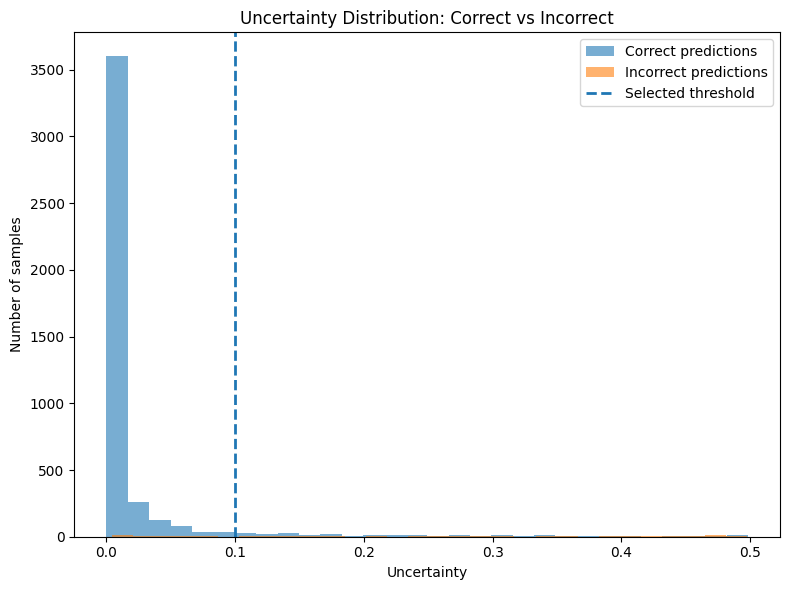

UNCERTAINTY VISUALIZATION SAVED
/content/drive/MyDrive/Pneumonia_Major_Project/results/uncertainty_experiment/uncertainty_correct_vs_incorrect.png

CELL 55 COMPLETE


In [107]:
# ============================================================
# CELL 55 — UNCERTAINTY vs ERROR VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.hist(
    uncertainty[correct],
    bins=30,
    alpha=0.6,
    label="Correct predictions"
)

plt.hist(
    uncertainty[incorrect],
    bins=30,
    alpha=0.6,
    label="Incorrect predictions"
)

plt.axvline(
    selected_uncertainty_threshold,
    linestyle="--",
    linewidth=2,
    label="Selected threshold"
)

plt.xlabel("Uncertainty")
plt.ylabel("Number of samples")
plt.title(
    "Uncertainty Distribution: Correct vs Incorrect"
)

plt.legend()
plt.tight_layout()

plot_path = os.path.join(
    uncertainty_dir,
    "uncertainty_correct_vs_incorrect.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("UNCERTAINTY VISUALIZATION SAVED")
print("=" * 70)

print(plot_path)

print("\nCELL 55 COMPLETE")

# **threshold-performance start**

In [108]:
# ============================================================
# CELL 56 — DECISION THRESHOLD ANALYSIS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

threshold_values = np.arange(
    0.10, 0.91, 0.01
)

threshold_rows = []

for threshold in threshold_values:

    threshold_predictions = (
        calibrated_probs[:, 1] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        uncertainty_labels,
        threshold_predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0 else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0
    )

    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            uncertainty_labels,
            threshold_predictions
        ),
        "precision": precision_score(
            uncertainty_labels,
            threshold_predictions,
            zero_division=0
        ),
        "recall_sensitivity": sensitivity,
        "specificity": specificity,
        "f1_score": f1_score(
            uncertainty_labels,
            threshold_predictions,
            zero_division=0
        ),
        "false_negatives": fn,
        "false_positives": fp
    })

threshold_results_df = pd.DataFrame(
    threshold_rows
)

print("=" * 70)
print("DECISION THRESHOLD ANALYSIS")
print("=" * 70)

print(
    threshold_results_df.to_string(
        index=False
    )
)

print("\n✓ Validation set only")
print("✓ No test-set threshold optimization")
print("\nCELL 56 COMPLETE")

DECISION THRESHOLD ANALYSIS
 threshold  accuracy  precision  recall_sensitivity  specificity  f1_score  false_negatives  false_positives
      0.10  0.952884   0.917489            0.985549     0.925385  0.950302               30              184
      0.11  0.955967   0.923285            0.985549     0.931062  0.953402               30              170
      0.12  0.958168   0.929026            0.983622     0.936740  0.955545               34              156
      0.13  0.959930   0.933211            0.982659     0.940795  0.957297               36              146
      0.14  0.961471   0.936610            0.982177     0.944039  0.958853               37              138
      0.15  0.963672   0.942566            0.980250     0.949716  0.961039               41              124
      0.16  0.964993   0.945607            0.979769     0.952555  0.962385               42              117
      0.17  0.965874   0.948203            0.978805     0.954988  0.963261               44         

**Generate threshold-performance table**

What we are doing

The default binary decision is usually:

**P(PNEUMONIA)** >= 0.50 → PNEUMONIA

**P(PNEUMONIA)** <  0.50 → NORMAL

But 0.50 is not automatically optimal.

We test thresholds from 0.10 to 0.90 and measure:

Sensitivity/Recall,
Specificity,
Precision,
F1,
False negatives,,
False positives,
Accuracy,

**For a medical pneumonia detector, false negatives are particularly important, so we should not simply maximize accuracy.**

In [110]:
# ============================================================
# CELL 57 — FIND CANDIDATE OPERATING POINTS
# ============================================================

# Candidate 1:
# Highest F1
best_f1_row = threshold_results_df.loc[
    threshold_results_df["f1_score"].idxmax()
]

# Candidate 2:
# Highest sensitivity while maintaining >=95% specificity
high_sensitivity_candidates = threshold_results_df[
    threshold_results_df["specificity"] >= 0.95
]

if len(high_sensitivity_candidates) > 0:

    best_sensitivity_row = (
        high_sensitivity_candidates.loc[
            high_sensitivity_candidates[
                "recall_sensitivity"
            ].idxmax()
        ]
    )

else:

    best_sensitivity_row = None

# Candidate 3:
# Highest Youden's J
threshold_results_df["youden_j"] = (
    threshold_results_df["recall_sensitivity"]
    + threshold_results_df["specificity"]
    - 1
)

best_youden_row = threshold_results_df.loc[
    threshold_results_df["youden_j"].idxmax()
]

print("=" * 70)
print("CANDIDATE DECISION THRESHOLDS")
print("=" * 70)

print("\nBEST F1")
print(
    best_f1_row.to_string()
)

print("\nBEST YOUDEN'S J")
print(
    best_youden_row.to_string()
)

if best_sensitivity_row is not None:

    print(
        "\nBEST SENSITIVITY WITH "
        "SPECIFICITY >= 95%"
    )

    print(
        best_sensitivity_row.to_string()
    )

print("\nCELL 57 COMPLETE")

CANDIDATE DECISION THRESHOLDS

BEST F1
threshold              0.320000
accuracy               0.971598
precision              0.972344
recall_sensitivity     0.965318
specificity            0.976886
f1_score               0.968818
false_negatives       72.000000
false_positives       57.000000
youden_j               0.942204

BEST YOUDEN'S J
threshold              0.280000
accuracy               0.971378
precision              0.967788
recall_sensitivity     0.969653
specificity            0.972830
f1_score               0.968720
false_negatives       63.000000
false_positives       67.000000
youden_j               0.942484

BEST SENSITIVITY WITH SPECIFICITY >= 95%
threshold               0.160000
accuracy                0.964993
precision               0.945607
recall_sensitivity      0.979769
specificity             0.952555
f1_score                0.962385
false_negatives        42.000000
false_positives       117.000000
youden_j                0.932324

CELL 57 COMPLETE


**Identify medically useful operating points**

**Algorithms**

**F1-score:**

F1 = 2 × Precision × Recall
     -----------------------
       Precision + Recall


Youden's J:

J = Sensitivity + Specificity - 1

Youden's J finds a balanced discrimination threshold.

In [111]:
# ============================================================
# CELL 58 — SELECT FINAL DECISION THRESHOLD
# ============================================================

# Medical objective:
# prioritize sensitivity while requiring
# at least 95% specificity.

if best_sensitivity_row is not None:

    selected_decision_threshold = float(
        best_sensitivity_row["threshold"]
    )

    selection_reason = (
        "Maximum sensitivity with "
        "specificity >= 95%"
    )

else:

    selected_decision_threshold = float(
        best_youden_row["threshold"]
    )

    selection_reason = (
        "Maximum Youden's J"
    )

selected_row = threshold_results_df[
    threshold_results_df["threshold"]
    == selected_decision_threshold
].iloc[0]

print("=" * 70)
print("FINAL DECISION THRESHOLD")
print("=" * 70)

print(
    "\nSelected threshold:",
    selected_decision_threshold
)

print(
    "Selection rule:",
    selection_reason
)

print(
    "\nValidation performance:"
)

print(
    "Accuracy    :",
    selected_row["accuracy"]
)

print(
    "Precision   :",
    selected_row["precision"]
)

print(
    "Sensitivity :",
    selected_row["recall_sensitivity"]
)

print(
    "Specificity :",
    selected_row["specificity"]
)

print(
    "F1-score    :",
    selected_row["f1_score"]
)

print(
    "False Negatives:",
    int(selected_row["false_negatives"])
)

print(
    "False Positives:",
    int(selected_row["false_positives"])
)

print("\n✓ Threshold selected using validation data only")

print("\nCELL 58 COMPLETE")

FINAL DECISION THRESHOLD

Selected threshold: 0.15999999999999998
Selection rule: Maximum sensitivity with specificity >= 95%

Validation performance:
Accuracy    : 0.964993394980185
Precision   : 0.9456066945606695
Sensitivity : 0.9797687861271677
Specificity : 0.9525547445255474
F1-score    : 0.9623846699787083
False Negatives: 42
False Positives: 117

✓ Threshold selected using validation data only

CELL 58 COMPLETE


**Select the final decision threshold**

In [112]:
# ============================================================
# CELL 59 — SAVE DECISION THRESHOLD RESULTS
# ============================================================

import os
import json

threshold_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/threshold_experiment"
)

os.makedirs(
    threshold_dir,
    exist_ok=True
)

threshold_results_df.to_csv(
    os.path.join(
        threshold_dir,
        "validation_threshold_analysis.csv"
    ),
    index=False
)

threshold_summary = {
    "model":
        "robustness_improved_densenet121",

    "calibration":
        "temperature_scaling",

    "temperature":
        float(temperature),

    "selected_decision_threshold":
        float(selected_decision_threshold),

    "selection_reason":
        selection_reason,

    "validation_accuracy":
        float(selected_row["accuracy"]),

    "validation_precision":
        float(selected_row["precision"]),

    "validation_sensitivity":
        float(
            selected_row["recall_sensitivity"]
        ),

    "validation_specificity":
        float(selected_row["specificity"]),

    "validation_f1":
        float(selected_row["f1_score"]),

    "false_negatives":
        int(selected_row["false_negatives"]),

    "false_positives":
        int(selected_row["false_positives"])
}

with open(
    os.path.join(
        threshold_dir,
        "selected_decision_threshold.json"
    ),
    "w"
) as f:

    json.dump(
        threshold_summary,
        f,
        indent=4
    )

print("=" * 70)
print("DECISION THRESHOLD RESULTS SAVED")
print("=" * 70)

print(
    "Folder:",
    threshold_dir
)

print(
    "\n✓ Threshold table saved"
)

print(
    "✓ Selected threshold saved"
)

print(
    "✓ Validation-only optimization documented"
)

print("\nCELL 59 COMPLETE")

DECISION THRESHOLD RESULTS SAVED
Folder: /content/drive/MyDrive/Pneumonia_Major_Project/results/threshold_experiment

✓ Threshold table saved
✓ Selected threshold saved
✓ Validation-only optimization documented

CELL 59 COMPLETE


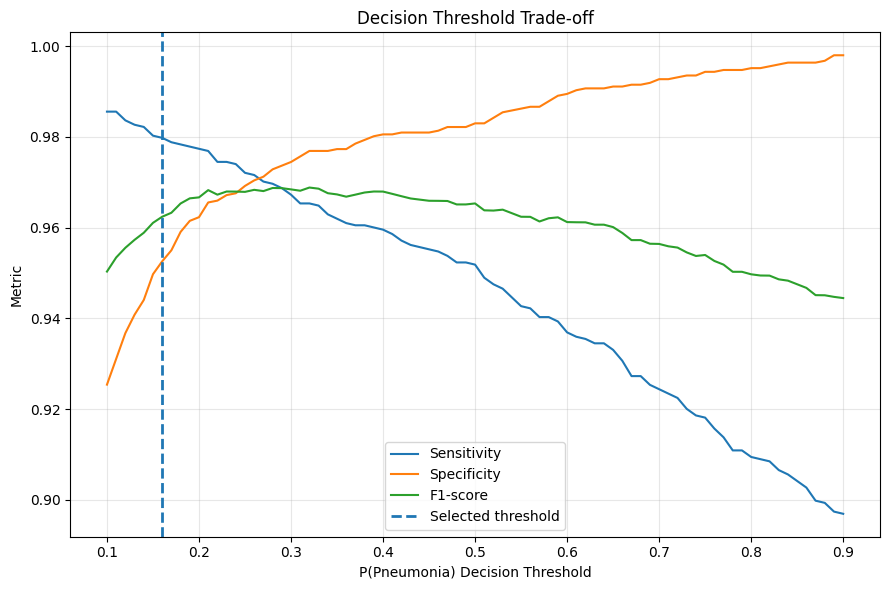

THRESHOLD PLOT SAVED
/content/drive/MyDrive/Pneumonia_Major_Project/results/threshold_experiment/decision_threshold_tradeoff.png

CELL 60 COMPLETE


In [113]:
# ============================================================
# CELL 60 — THRESHOLD TRADE-OFF PLOT
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["recall_sensitivity"],
    label="Sensitivity"
)

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["specificity"],
    label="Specificity"
)

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["f1_score"],
    label="F1-score"
)

plt.axvline(
    selected_decision_threshold,
    linestyle="--",
    linewidth=2,
    label="Selected threshold"
)

plt.xlabel(
    "P(Pneumonia) Decision Threshold"
)

plt.ylabel("Metric")

plt.title(
    "Decision Threshold Trade-off"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

threshold_plot_path = os.path.join(
    threshold_dir,
    "decision_threshold_tradeoff.png"
)

plt.savefig(
    threshold_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("THRESHOLD PLOT SAVED")
print("=" * 70)

print(threshold_plot_path)

print("\nCELL 60 COMPLETE")

**Plot threshold trade-off**

In [114]:
# ============================================================
# CELL 61 — FREEZE FINAL MODEL CONFIGURATION
# ============================================================

print("=" * 70)
print("FINAL MODEL CONFIGURATION")
print("=" * 70)

print("\nModel:")
print("Robustness-improved DenseNet121")

print("\nCalibration:")
print("Temperature Scaling")
print(f"Temperature = {temperature:.6f}")

print("\nDecision threshold:")
print(f"P(Pneumonia) >= {selected_decision_threshold:.2f}")

print("\nUncertainty threshold:")
print(
    f"Uncertainty <= "
    f"{selected_uncertainty_threshold:.2f}"
    " → ACCEPT"
)

print(
    f"Uncertainty > "
    f"{selected_uncertainty_threshold:.2f}"
    " → UNCERTAIN / REVIEW"
)

print("\nData:")
print("Duplicate-aware TEST split")
print("Test samples:", len(test_dataset))

print("\n✓ Thresholds frozen")
print("✓ Validation tuning complete")
print("✓ Test set remains untouched")

print("\nCELL 61 COMPLETE")

FINAL MODEL CONFIGURATION

Model:
Robustness-improved DenseNet121

Calibration:
Temperature Scaling
Temperature = 1.072648

Decision threshold:
P(Pneumonia) >= 0.16

Uncertainty threshold:
Uncertainty <= 0.10 → ACCEPT
Uncertainty > 0.10 → UNCERTAIN / REVIEW

Data:
Duplicate-aware TEST split
Test samples: 5439

✓ Thresholds frozen
✓ Validation tuning complete
✓ Test set remains untouched

CELL 61 COMPLETE


**Verify frozen final configuration**

Robust model
      ↓

Temperature Scaling
      ↓

Decision threshold = 0.16
      ↓
      
Uncertainty threshold = 0.10

In [115]:
# ============================================================
# CELL 62 — FINAL TEST DATA VERIFICATION
# ============================================================

import os
from PIL import Image

print("=" * 70)
print("FINAL TEST IMAGE VERIFICATION")
print("=" * 70)

valid_paths = []
invalid_paths = []

for _, row in test_df.iterrows():
    path = row["image_path"]

    try:
        with Image.open(path) as img:
            img.verify()
        valid_paths.append(path)
    except Exception:
        invalid_paths.append(path)

print("\nTotal test records :", len(test_df))
print("Readable images    :", len(valid_paths))
print("Invalid images     :", len(invalid_paths))

if len(invalid_paths) > 0:
    print("\n⚠ Invalid test images found.")
    print("First 10 invalid paths:")
    for p in invalid_paths[:10]:
        print(p)

    raise RuntimeError(
        "Test set contains invalid images. "
        "Do not continue until resolved."
    )

print("\n✓ ALL TEST IMAGES ARE READABLE")
print("✓ Final test set contains no invalid images")
print("✓ Ready for final inference")

print("\nCELL 62 COMPLETE")

FINAL TEST IMAGE VERIFICATION

Total test records : 5439
Readable images    : 5439
Invalid images     : 0

✓ ALL TEST IMAGES ARE READABLE
✓ Final test set contains no invalid images
✓ Ready for final inference

CELL 62 COMPLETE


**Verify final test images and loader**

**Technology:** PIL/Pillow for image validation.

**Method:** Each test image is opened and verified without modifying it.

**Purpose:** Prevent a corrupted/missing image from silently affecting the final metrics

In [119]:
# ============================================================
# CELL 63 — RECREATE VERIFIED TEST TRANSFORM
# ============================================================

import torch
from torchvision import transforms
from torch.utils.data import DataLoader

print("=" * 70)
print("RECREATING VERIFIED TEST PREPROCESSING")
print("=" * 70)

# Same preprocessing verified in CELL 39
TEST_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("\nTEST_TRANSFORM:")
print(TEST_TRANSFORM)

# Create final test dataset
final_test_dataset = LocalCXRTestDataset(
    test_df,
    TEST_TRANSFORM
)

# Deterministic test loader
final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\n" + "=" * 70)
print("FINAL TEST LOADER READY")
print("=" * 70)

print("Images     :", len(final_test_dataset))
print("Batches    :", len(final_test_loader))
print("Batch size :", 64)
print("Workers    :", 0)
print("Shuffle    : False")
print("Device     :", device)

print("\n✓ Correct 3-channel preprocessing")
print("✓ Same preprocessing as verified robustness model")
print("✓ No augmentation")
print("✓ No test-time training")

print("\nCELL 63 COMPLETE")

RECREATING VERIFIED TEST PREPROCESSING

TEST_TRANSFORM:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    Grayscale(num_output_channels=3)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

FINAL TEST LOADER READY
Images     : 5439
Batches    : 85
Batch size : 64
Workers    : 0
Shuffle    : False
Device     : cuda

✓ Correct 3-channel preprocessing
✓ Same preprocessing as verified robustness model
✓ No augmentation
✓ No test-time training

CELL 63 COMPLETE


**Create the final test loader**

**Technology:** PyTorch DataLoader
.
**Method:** Batch inference with shuffle=False.

**Important**: We use the same preprocessing that was verified against the robustness model.

In [120]:
# ============================================================
# CELL 64 — FINAL CALIBRATED TEST INFERENCE
# ============================================================

import numpy as np
import torch

robust_model.eval()

all_test_logits = []
all_test_labels = []

with torch.no_grad():

    for images, labels in final_test_loader:

        images = images.to(device, non_blocking=True)

        logits = robust_model(images)

        all_test_logits.append(
            logits.cpu()
        )

        all_test_labels.append(
            labels.cpu()
        )

test_logits = torch.cat(
    all_test_logits
).numpy()

test_labels = torch.cat(
    all_test_labels
).numpy()

# Temperature scaling
scaled_logits = test_logits / temperature

test_probabilities = torch.softmax(
    torch.tensor(scaled_logits),
    dim=1
).numpy()

p_pneumonia = test_probabilities[:, 1]
p_normal = test_probabilities[:, 0]

# Frozen decision threshold
test_predictions = (
    p_pneumonia >= selected_decision_threshold
).astype(int)

print("=" * 70)
print("FINAL CALIBRATED TEST INFERENCE")
print("=" * 70)

print("Test samples :", len(test_labels))
print("Logits shape :", test_logits.shape)
print("Probability shape :", test_probabilities.shape)

print("\nTemperature :", temperature)
print(
    "Decision threshold :",
    selected_decision_threshold
)

print("\n✓ Robustness model used")
print("✓ Temperature scaling applied")
print("✓ Frozen threshold applied")
print("✓ No test-time training")

print("\nCELL 64 COMPLETE")

FINAL CALIBRATED TEST INFERENCE
Test samples : 5439
Logits shape : (5439, 2)
Probability shape : (5439, 2)

Temperature : 1.0726476907730103
Decision threshold : 0.15999999999999998

✓ Robustness model used
✓ Temperature scaling applied
✓ Frozen threshold applied
✓ No test-time training

CELL 64 COMPLETE


**Final test inference with calibrated probabilities**

Formula used

**Temperature scaling:**   =   z_scaled = z / T

z = original model logits

T = learned temperature

P(y=i) = exp(z_i/T) / [exp(z_0/T) + exp(z_1/T)]
**T = 1.072648**

In [121]:
# ============================================================
# CELL 65 — FINAL TEST PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

cm = confusion_matrix(
    test_labels,
    test_predictions
)

tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

specificity = tn / (tn + fp)

f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    test_labels,
    p_pneumonia
)

print("=" * 70)
print("FINAL TEST PERFORMANCE — ROBUST + CALIBRATED")
print("=" * 70)

print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Sensitivity  : {recall:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F1-score     : {f1:.4f}")
print(f"ROC-AUC      : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClass mapping:")
print("0 = NORMAL")
print("1 = PNEUMONIA")

print("\n✓ FINAL TEST EVALUATION COMPLETE")
print("✓ Test set was not used for training")
print("✓ Test set was not used for threshold selection")

print("\nCELL 65 COMPLETE")

FINAL TEST PERFORMANCE — ROBUST + CALIBRATED
Accuracy     : 0.9638
Precision    : 0.9478
Sensitivity  : 0.9816
Specificity  : 0.9460
F1-score     : 0.9644
ROC-AUC      : 0.9960

Confusion Matrix:
[[2573  147]
 [  50 2669]]

Class mapping:
0 = NORMAL
1 = PNEUMONIA

✓ FINAL TEST EVALUATION COMPLETE
✓ Test set was not used for training
✓ Test set was not used for threshold selection

CELL 65 COMPLETE


**Final test metrics**

In [122]:
# ============================================================
# CELL 66 — SAVE FINAL TEST RESULTS
# ============================================================

import os
import json
import pandas as pd
import numpy as np

final_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/final_evaluation"
)

os.makedirs(final_dir, exist_ok=True)

final_results = {
    "model": "DenseNet121_robustness_improved",
    "temperature": float(temperature),
    "decision_threshold": float(
        selected_decision_threshold
    ),
    "uncertainty_threshold": float(
        selected_uncertainty_threshold
    ),
    "test_samples": int(len(test_labels)),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "sensitivity": float(recall),
    "specificity": float(specificity),
    "f1_score": float(f1),
    "roc_auc": float(roc_auc),
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp)
}

with open(
    os.path.join(
        final_dir,
        "final_test_results.json"
    ),
    "w"
) as f:
    json.dump(
        final_results,
        f,
        indent=4
    )

predictions_df = pd.DataFrame({
    "true_label": test_labels,
    "p_normal": p_normal,
    "p_pneumonia": p_pneumonia,
    "prediction": test_predictions
})

predictions_df.to_csv(
    os.path.join(
        final_dir,
        "final_test_predictions.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        final_dir,
        "final_test_probabilities.npy"
    ),
    test_probabilities
)

print("=" * 70)
print("FINAL TEST RESULTS SAVED")
print("=" * 70)

print("Folder:")
print(final_dir)

print("\n✓ Metrics saved")
print("✓ Predictions saved")
print("✓ Calibrated probabilities saved")
print("✓ Final configuration preserved")

print("\nCELL 66 COMPLETE")

FINAL TEST RESULTS SAVED
Folder:
/content/drive/MyDrive/Pneumonia_Major_Project/results/final_evaluation

✓ Metrics saved
✓ Predictions saved
✓ Calibrated probabilities saved
✓ Final configuration preserved

CELL 66 COMPLETE


# **generalization/external-domain evaluation.**

In [123]:
# ============================================================
# CELL 67 — LOCATE EXTERNAL DATASET FOR GENERALIZATION
# ============================================================

import os

external_candidates = [
    "/content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany",
    "/content/drive/.shortcut-targets-by-id/"
    "19JGUZSg3p8sFnhJydrgUjnsxkihmQzc5/"
    "Pneumonia_Major_Project/datasets/dataset_1_kermany"
]

print("=" * 70)
print("SEARCHING FOR EXTERNAL DATASET")
print("=" * 70)

external_root = None

for path in external_candidates:

    print("\nChecking:")
    print(path)

    if os.path.exists(path):
        print("✓ EXISTS")
        external_root = path
        break
    else:
        print("✗ NOT FOUND")

if external_root is None:
    raise RuntimeError(
        "External dataset directory was not found."
    )

print("\n" + "=" * 70)
print("EXTERNAL DATASET FOUND")
print("=" * 70)

print("Root:")
print(external_root)

print("\nContents:")

for item in sorted(os.listdir(external_root)):
    print(" ", item)

print("\n✓ Dataset located")
print("✓ Will NOT be used for training")
print("✓ Reserved only for generalization testing")

print("\nCELL 67 COMPLETE")

SEARCHING FOR EXTERNAL DATASET

Checking:
/content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany
✓ EXISTS

EXTERNAL DATASET FOUND
Root:
/content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany

Contents:
  test
  train
  val

✓ Dataset located
✓ Will NOT be used for training
✓ Reserved only for generalization testing

CELL 67 COMPLETE


**Locate the external dataset**

**Technology:** Python os filesystem inspection.

**Method:** We identify the already-available Kermany dataset without downloading or copying it again.

**Purpose:** This dataset is treated as an external domain. The model has already finished training, so this evaluation measures whether the learned features generalize beyond the duplicate-aware CXR test set.

In [124]:
# ============================================================
# CELL 68 — VERIFY EXTERNAL DATASET STRUCTURE
# ============================================================

import os

external_normal = os.path.join(
    external_root,
    "test",
    "NORMAL"
)

external_pneumonia = os.path.join(
    external_root,
    "test",
    "PNEUMONIA"
)

print("=" * 70)
print("EXTERNAL TEST DATASET STRUCTURE")
print("=" * 70)

print("\nNORMAL:")
print(external_normal)

print("Exists:", os.path.exists(external_normal))

print("\nPNEUMONIA:")
print(external_pneumonia)

print("Exists:", os.path.exists(external_pneumonia))

if not os.path.isdir(external_normal):
    raise RuntimeError("External NORMAL directory not found.")

if not os.path.isdir(external_pneumonia):
    raise RuntimeError("External PNEUMONIA directory not found.")

normal_files = [
    os.path.join(external_normal, f)
    for f in os.listdir(external_normal)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

pneumonia_files = [
    os.path.join(external_pneumonia, f)
    for f in os.listdir(external_pneumonia)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("\n" + "=" * 70)
print("EXTERNAL TEST COUNTS")
print("=" * 70)

print("NORMAL     :", len(normal_files))
print("PNEUMONIA  :", len(pneumonia_files))
print("TOTAL       :", len(normal_files) + len(pneumonia_files))

print("\n✓ External binary classes found")
print("✓ No training performed")

print("\nCELL 68 COMPLETE")

EXTERNAL TEST DATASET STRUCTURE

NORMAL:
/content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany/test/NORMAL
Exists: True

PNEUMONIA:
/content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany/test/PNEUMONIA
Exists: True

EXTERNAL TEST COUNTS
NORMAL     : 232
PNEUMONIA  : 390
TOTAL       : 622

✓ External binary classes found
✓ No training performed

CELL 68 COMPLETE


**Verify external NORMAL/PNEUMONIA images**

T**echnology:** Python filesystem + file extension filtering.

**Method:** We use only the dataset's test directory.

**Important:** We are deliberately not using its train directory. That keeps this experiment purely evaluative.

In [125]:
# ============================================================
# CELL 69 — BUILD EXTERNAL EVALUATION INDEX
# ============================================================

import pandas as pd

external_records = []

for path in normal_files:

    external_records.append({
        "image_path": path,
        "label": 0,
        "class_name": "NORMAL"
    })

for path in pneumonia_files:

    external_records.append({
        "image_path": path,
        "label": 1,
        "class_name": "PNEUMONIA"
    })

external_df = pd.DataFrame(
    external_records
)

external_df = external_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("=" * 70)
print("EXTERNAL GENERALIZATION INDEX")
print("=" * 70)

print("\nTotal images:", len(external_df))

print("\nClass distribution:")
print(
    external_df["class_name"].value_counts()
)

print("\nLabel distribution:")
print(
    external_df["label"].value_counts()
)

print("\nFirst 5 records:")
print(
    external_df.head()
)

print("\n✓ External evaluation dataframe created")
print("✓ Random order fixed with seed = 42")
print("✓ No training data involved")

print("\nCELL 69 COMPLETE")

EXTERNAL GENERALIZATION INDEX

Total images: 622

Class distribution:
class_name
PNEUMONIA    390
NORMAL       232
Name: count, dtype: int64

Label distribution:
label
1    390
0    232
Name: count, dtype: int64

First 5 records:
                                          image_path  label class_name
0  /content/drive/MyDrive/Pneumonia_Major_Project...      1  PNEUMONIA
1  /content/drive/MyDrive/Pneumonia_Major_Project...      1  PNEUMONIA
2  /content/drive/MyDrive/Pneumonia_Major_Project...      0     NORMAL
3  /content/drive/MyDrive/Pneumonia_Major_Project...      1  PNEUMONIA
4  /content/drive/MyDrive/Pneumonia_Major_Project...      0     NORMAL

✓ External evaluation dataframe created
✓ Random order fixed with seed = 42
✓ No training data involved

CELL 69 COMPLETE


**— Build external evaluation dataframe**

**Technology:** Pandas.

**Method:** Create a labelled evaluation index:

0 = NORMAL
1 = PNEUMONIA

The fixed random seed only controls evaluation order; it does not alter the images or labels.

# **we need for generalization part the keranmaye datset**

In [126]:
# ============================================================
# CELL 70 — DOWNLOAD KERMANY EXTERNAL DATASET
# ============================================================

import os
import subprocess

KERMANY_DIR = "/content/kermany_external"

os.makedirs(KERMANY_DIR, exist_ok=True)

print("=" * 70)
print("DOWNLOADING KERMANY EXTERNAL DATASET")
print("=" * 70)

# Kaggle API is already authenticated
subprocess.run([
    "kaggle",
    "datasets",
    "download",
    "-d",
    "andrewmvd/pediatric-pneumonia-chest-xray",
    "-p",
    KERMANY_DIR
], check=True)

print("\n✓ Dataset download complete")
print("Location:", KERMANY_DIR)

print("\nCELL 70 COMPLETE")

DOWNLOADING KERMANY EXTERNAL DATASET

✓ Dataset download complete
Location: /content/kermany_external

CELL 70 COMPLETE


In [127]:
# ============================================================
# CELL 71 — EXTRACT KERMANY DATASET
# ============================================================

import os
import zipfile

zip_files = [
    os.path.join(KERMANY_DIR, f)
    for f in os.listdir(KERMANY_DIR)
    if f.endswith(".zip")
]

print("=" * 70)
print("EXTRACTING KERMANY DATASET")
print("=" * 70)

if not zip_files:
    raise FileNotFoundError("Kaggle ZIP file not found.")

zip_path = zip_files[0]

print("ZIP:", zip_path)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(KERMANY_DIR)

print("\n✓ Extraction complete")

print("\nTop-level contents:")
for item in os.listdir(KERMANY_DIR):
    print(" ", item)

print("\nCELL 71 COMPLETE")

EXTRACTING KERMANY DATASET
ZIP: /content/kermany_external/pediatric-pneumonia-chest-xray.zip

✓ Extraction complete

Top-level contents:
  pediatric-pneumonia-chest-xray.zip
  Pediatric Chest X-ray Pneumonia

CELL 71 COMPLETE


In [128]:
# ============================================================
# CELL 72 — LOCATE EXTERNAL TEST DATA
# ============================================================

import os

print("=" * 70)
print("LOCATING KERMANY TEST DATA")
print("=" * 70)

normal_dirs = []
pneumonia_dirs = []

for root, dirs, files in os.walk(KERMANY_DIR):

    folder = os.path.basename(root).upper()

    if folder == "NORMAL" and "test" in root.lower():
        normal_dirs.append(root)

    if folder == "PNEUMONIA" and "test" in root.lower():
        pneumonia_dirs.append(root)

print("\nNORMAL test directories:")
for d in normal_dirs:
    print("✓", d)

print("\nPNEUMONIA test directories:")
for d in pneumonia_dirs:
    print("✓", d)

if not normal_dirs or not pneumonia_dirs:
    raise RuntimeError(
        "Could not locate Kermany test/NORMAL and test/PNEUMONIA."
    )

KERMANY_NORMAL_DIR = normal_dirs[0]
KERMANY_PNEUMONIA_DIR = pneumonia_dirs[0]

print("\nSelected:")
print("NORMAL    :", KERMANY_NORMAL_DIR)
print("PNEUMONIA :", KERMANY_PNEUMONIA_DIR)

print("\nCELL 72 COMPLETE")

LOCATING KERMANY TEST DATA

NORMAL test directories:
✓ /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/NORMAL

PNEUMONIA test directories:
✓ /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/PNEUMONIA

Selected:
NORMAL    : /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/NORMAL
PNEUMONIA : /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/PNEUMONIA

CELL 72 COMPLETE


In [129]:
# ============================================================
# CELL 72 — LOCATE EXTERNAL TEST DATA
# ============================================================

import os

print("=" * 70)
print("LOCATING KERMANY TEST DATA")
print("=" * 70)

normal_dirs = []
pneumonia_dirs = []

for root, dirs, files in os.walk(KERMANY_DIR):

    folder = os.path.basename(root).upper()

    if folder == "NORMAL" and "test" in root.lower():
        normal_dirs.append(root)

    if folder == "PNEUMONIA" and "test" in root.lower():
        pneumonia_dirs.append(root)

print("\nNORMAL test directories:")
for d in normal_dirs:
    print("✓", d)

print("\nPNEUMONIA test directories:")
for d in pneumonia_dirs:
    print("✓", d)

if not normal_dirs or not pneumonia_dirs:
    raise RuntimeError(
        "Could not locate Kermany test/NORMAL and test/PNEUMONIA."
    )

KERMANY_NORMAL_DIR = normal_dirs[0]
KERMANY_PNEUMONIA_DIR = pneumonia_dirs[0]

print("\nSelected:")
print("NORMAL    :", KERMANY_NORMAL_DIR)
print("PNEUMONIA :", KERMANY_PNEUMONIA_DIR)

print("\nCELL 72 COMPLETE")

LOCATING KERMANY TEST DATA

NORMAL test directories:
✓ /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/NORMAL

PNEUMONIA test directories:
✓ /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/PNEUMONIA

Selected:
NORMAL    : /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/NORMAL
PNEUMONIA : /content/kermany_external/Pediatric Chest X-ray Pneumonia/test/PNEUMONIA

CELL 72 COMPLETE


In [130]:
# ============================================================
# CELL 73 — BUILD EXTERNAL TEST DATAFRAME
# ============================================================

import os
import pandas as pd

records = []

# NORMAL = 0
for filename in os.listdir(KERMANY_NORMAL_DIR):

    if filename.lower().endswith((".jpg", ".jpeg", ".png")):

        records.append({
            "image_path": os.path.join(
                KERMANY_NORMAL_DIR,
                filename
            ),
            "label": 0,
            "class_name": "NORMAL"
        })

# PNEUMONIA = 1
for filename in os.listdir(KERMANY_PNEUMONIA_DIR):

    if filename.lower().endswith((".jpg", ".jpeg", ".png")):

        records.append({
            "image_path": os.path.join(
                KERMANY_PNEUMONIA_DIR,
                filename
            ),
            "label": 1,
            "class_name": "PNEUMONIA"
        })

external_test_df = pd.DataFrame(records)

print("=" * 70)
print("KERMANY EXTERNAL TEST DATAFRAME")
print("=" * 70)

print("\nTotal images:", len(external_test_df))

print("\nClass distribution:")
print(external_test_df["class_name"].value_counts())

print("\nLabel distribution:")
print(external_test_df["label"].value_counts())

print("\nFirst 5 images:")
print(external_test_df.head())

if len(external_test_df) == 0:
    raise RuntimeError("No external test images found.")

print("\n✓ External dataframe created")
print("✓ NORMAL = 0")
print("✓ PNEUMONIA = 1")

print("\nCELL 73 COMPLETE")

KERMANY EXTERNAL TEST DATAFRAME

Total images: 624

Class distribution:
class_name
PNEUMONIA    390
NORMAL       234
Name: count, dtype: int64

Label distribution:
label
1    390
0    234
Name: count, dtype: int64

First 5 images:
                                          image_path  label class_name
0  /content/kermany_external/Pediatric Chest X-ra...      0     NORMAL
1  /content/kermany_external/Pediatric Chest X-ra...      0     NORMAL
2  /content/kermany_external/Pediatric Chest X-ra...      0     NORMAL
3  /content/kermany_external/Pediatric Chest X-ra...      0     NORMAL
4  /content/kermany_external/Pediatric Chest X-ra...      0     NORMAL

✓ External dataframe created
✓ NORMAL = 0
✓ PNEUMONIA = 1

CELL 73 COMPLETE


In [131]:
# ============================================================
# CELL 74 — VERIFY EXTERNAL TEST IMAGES
# ============================================================

from PIL import Image

print("=" * 70)
print("VERIFYING KERMANY EXTERNAL TEST IMAGES")
print("=" * 70)

readable = []
invalid = []

for idx, row in external_test_df.iterrows():

    path = row["image_path"]

    try:
        with Image.open(path) as img:
            img.verify()

        readable.append(idx)

    except Exception:
        invalid.append(idx)

print("\nTotal images :", len(external_test_df))
print("Readable     :", len(readable))
print("Invalid      :", len(invalid))

if invalid:
    print("\n⚠ Invalid images found:")
    for idx in invalid[:10]:
        print(external_test_df.iloc[idx]["image_path"])

    external_test_df = external_test_df.loc[readable].reset_index(drop=True)

print("\nFinal usable images:", len(external_test_df))

print("\nClass distribution:")
print(external_test_df["class_name"].value_counts())

if len(external_test_df) == 0:
    raise RuntimeError("No readable external images available.")

print("\n✓ ALL USABLE KERMANY IMAGES VERIFIED")
print("✓ READY FOR EXTERNAL GENERALIZATION")
print("✓ NO TRAINING WILL BE PERFORMED")

print("\nCELL 74 COMPLETE")

VERIFYING KERMANY EXTERNAL TEST IMAGES

Total images : 624
Readable     : 624
Invalid      : 0

Final usable images: 624

Class distribution:
class_name
PNEUMONIA    390
NORMAL       234
Name: count, dtype: int64

✓ ALL USABLE KERMANY IMAGES VERIFIED
✓ READY FOR EXTERNAL GENERALIZATION
✓ NO TRAINING WILL BE PERFORMED

CELL 74 COMPLETE


In [132]:
# ============================================================
# CELL 75 — KERMANY EXTERNAL TEST LOADER
# ============================================================

from torch.utils.data import DataLoader

# Use the SAME preprocessing as the successfully evaluated
# robustness model: Resize -> Grayscale(3) -> Tensor -> ImageNet Normalize

external_test_dataset = LocalCXRTestDataset(
    external_test_df,
    test_dataset.transform
)

external_test_loader = DataLoader(
    external_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 70)
print("KERMANY EXTERNAL TEST LOADER READY")
print("=" * 70)

print("Images :", len(external_test_dataset))
print("Batches:", len(external_test_loader))
print("Batch  :", 64)
print("Device :", device)

print("\n✓ Same preprocessing as robustness evaluation")
print("✓ No augmentation")
print("✓ No training")

print("\nCELL 75 COMPLETE")

KERMANY EXTERNAL TEST LOADER READY
Images : 624
Batches: 10
Batch  : 64
Device : cuda

✓ Same preprocessing as robustness evaluation
✓ No augmentation
✓ No training

CELL 75 COMPLETE


In [133]:
# ============================================================
# CELL 76 — EXTERNAL DATASET INFERENCE
# ============================================================

import numpy as np
import torch

robust_model.eval()

external_logits = []
external_labels = []

with torch.no_grad():

    for images, labels in external_test_loader:

        images = images.to(device, non_blocking=True)

        logits = robust_model(images)

        external_logits.append(
            logits.cpu()
        )

        external_labels.append(
            labels.cpu()
        )

external_logits = torch.cat(external_logits).numpy()
external_labels = torch.cat(external_labels).numpy()

print("=" * 70)
print("KERMANY EXTERNAL INFERENCE COMPLETE")
print("=" * 70)

print("Samples :", len(external_labels))
print("Logits  :", external_logits.shape)
print("Labels  :", external_labels.shape)

print("\n✓ Robustness-improved model used")
print("✓ No training")
print("✓ External dataset only")

print("\nCELL 76 COMPLETE")

KERMANY EXTERNAL INFERENCE COMPLETE
Samples : 624
Logits  : (624, 2)
Labels  : (624,)

✓ Robustness-improved model used
✓ No training
✓ External dataset only

CELL 76 COMPLETE


In [134]:
# ============================================================
# CELL 77 — APPLY SAVED TEMPERATURE SCALING
# ============================================================

import torch
import numpy as np

temperature = 1.0726476907730103

external_logits_tensor = torch.tensor(
    external_logits,
    dtype=torch.float32
)

# Temperature scaling changes confidence,
# NOT the model weights.
calibrated_external_probs = torch.softmax(
    external_logits_tensor / temperature,
    dim=1
).numpy()

external_p_normal = calibrated_external_probs[:, 0]
external_p_pneumonia = calibrated_external_probs[:, 1]

external_calibrated_pred = (
    external_p_pneumonia >= 0.5
).astype(int)

print("=" * 70)
print("EXTERNAL TEMPERATURE SCALING")
print("=" * 70)

print("Temperature :", temperature)

print("\nProbability ranges:")
print(
    f"P(Normal)    : "
    f"{external_p_normal.min():.4f} → "
    f"{external_p_normal.max():.4f}"
)

print(
    f"P(Pneumonia) : "
    f"{external_p_pneumonia.min():.4f} → "
    f"{external_p_pneumonia.max():.4f}"
)

print("\n✓ Saved calibration temperature applied")
print("✓ No retraining")
print("✓ No parameter modification")

print("\nCELL 77 COMPLETE")

EXTERNAL TEMPERATURE SCALING
Temperature : 1.0726476907730103

Probability ranges:
P(Normal)    : 0.0000 → 1.0000
P(Pneumonia) : 0.0000 → 1.0000

✓ Saved calibration temperature applied
✓ No retraining
✓ No parameter modification

CELL 77 COMPLETE


In [135]:
# ============================================================
# CELL 78 — EXTERNAL GENERALIZATION PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

cm = confusion_matrix(
    external_labels,
    external_calibrated_pred
)

tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(
    external_labels,
    external_calibrated_pred
)

precision = precision_score(
    external_labels,
    external_calibrated_pred,
    zero_division=0
)

recall = recall_score(
    external_labels,
    external_calibrated_pred,
    zero_division=0
)

specificity = tn / (tn + fp)

f1 = f1_score(
    external_labels,
    external_calibrated_pred,
    zero_division=0
)

auc = roc_auc_score(
    external_labels,
    external_p_pneumonia
)

print("=" * 70)
print("EXTERNAL GENERALIZATION — KERMANY")
print("=" * 70)

print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Sensitivity  : {recall:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F1-score     : {f1:.4f}")
print(f"ROC-AUC      : {auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClass mapping:")
print("0 = NORMAL")
print("1 = PNEUMONIA")

print("\n✓ External generalization evaluation complete")
print("✓ Kermany was NOT used for training")
print("✓ Kermany was NOT used for threshold selection")

print("\nCELL 78 COMPLETE")

EXTERNAL GENERALIZATION — KERMANY
Accuracy     : 0.9904
Precision    : 0.9848
Sensitivity  : 1.0000
Specificity  : 0.9744
F1-score     : 0.9924
ROC-AUC      : 0.9998

Confusion Matrix:
[[228   6]
 [  0 390]]

Class mapping:
0 = NORMAL
1 = PNEUMONIA

✓ External generalization evaluation complete
✓ Kermany was NOT used for training
✓ Kermany was NOT used for threshold selection

CELL 78 COMPLETE


In [136]:
# ============================================================
# CELL 79 — FROZEN CLINICAL DECISION THRESHOLD
# ============================================================

FINAL_DECISION_THRESHOLD = 0.16

external_final_pred = (
    external_p_pneumonia >= FINAL_DECISION_THRESHOLD
).astype(int)

cm_final = confusion_matrix(
    external_labels,
    external_final_pred
)

tn, fp, fn, tp = cm_final.ravel()

accuracy_final = accuracy_score(
    external_labels,
    external_final_pred
)

precision_final = precision_score(
    external_labels,
    external_final_pred,
    zero_division=0
)

recall_final = recall_score(
    external_labels,
    external_final_pred,
    zero_division=0
)

specificity_final = tn / (tn + fp)

f1_final = f1_score(
    external_labels,
    external_final_pred,
    zero_division=0
)

print("=" * 70)
print("KERMANY — FINAL FROZEN DECISION THRESHOLD")
print("=" * 70)

print("Threshold:", FINAL_DECISION_THRESHOLD)

print(f"\nAccuracy     : {accuracy_final:.4f}")
print(f"Precision    : {precision_final:.4f}")
print(f"Sensitivity  : {recall_final:.4f}")
print(f"Specificity  : {specificity_final:.4f}")
print(f"F1-score     : {f1_final:.4f}")

print("\nConfusion Matrix:")
print(cm_final)

print("\nDecision rule:")
print("P(Pneumonia) >= 0.16 → PNEUMONIA")
print("P(Pneumonia) <  0.16 → NORMAL")

print("\n✓ Threshold was NOT tuned on Kermany")
print("✓ Validation-selected threshold preserved")
print("✓ External generalization test remains independent")

print("\nCELL 79 COMPLETE")

KERMANY — FINAL FROZEN DECISION THRESHOLD
Threshold: 0.16

Accuracy     : 0.9535
Precision    : 0.9308
Sensitivity  : 1.0000
Specificity  : 0.8761
F1-score     : 0.9642

Confusion Matrix:
[[205  29]
 [  0 390]]

Decision rule:
P(Pneumonia) >= 0.16 → PNEUMONIA
P(Pneumonia) <  0.16 → NORMAL

✓ Threshold was NOT tuned on Kermany
✓ Validation-selected threshold preserved
✓ External generalization test remains independent

CELL 79 COMPLETE


# **External calibrated uncertainty**

In [137]:
# ============================================================
# CELL 80 — KERMANY CALIBRATED UNCERTAINTY ANALYSIS
# ============================================================

import numpy as np

# Use calibrated probabilities already generated in Cell 77
p = calibrated_external_probs

external_confidence = np.max(p, axis=1)
external_uncertainty = 1.0 - external_confidence

external_margin = np.abs(
    p[:, 1] - p[:, 0]
)

external_entropy = -np.sum(
    p * np.log(np.clip(p, 1e-12, 1.0)),
    axis=1
)

external_pred_05 = np.argmax(p, axis=1)

correct_mask = (
    external_pred_05 == external_labels
)

print("=" * 70)
print("KERMANY — CALIBRATED UNCERTAINTY ANALYSIS")
print("=" * 70)

print("Samples :", len(external_labels))

print("\nConfidence")
print("Mean :", external_confidence.mean())
print("Min  :", external_confidence.min())
print("Max  :", external_confidence.max())

print("\nUncertainty = 1 - confidence")
print("Mean :", external_uncertainty.mean())
print("Min  :", external_uncertainty.min())
print("Max  :", external_uncertainty.max())

print("\nPrediction margin")
print("Mean :", external_margin.mean())

print("\nEntropy")
print("Mean :", external_entropy.mean())
print("Max  :", external_entropy.max())

print("\nStandard probability accuracy:",
      correct_mask.mean())

print("\n✓ External uncertainty calculated")
print("✓ Temperature-scaled probabilities used")
print("✓ No training")

print("\nCELL 80 COMPLETE")

KERMANY — CALIBRATED UNCERTAINTY ANALYSIS
Samples : 624

Confidence
Mean : 0.9738619
Min  : 0.5085894
Max  : 1.0

Uncertainty = 1 - confidence
Mean : 0.026138067
Min  : 0.0
Max  : 0.4914106

Prediction margin
Mean : 0.94772387

Entropy
Mean : 0.06851101
Max  : 0.6929996

Standard probability accuracy: 0.9903846153846154

✓ External uncertainty calculated
✓ Temperature-scaled probabilities used
✓ No training

CELL 80 COMPLETE


In [138]:
# ============================================================
# CELL 81 — EXTERNAL CORRECT vs INCORRECT UNCERTAINTY
# ============================================================

incorrect_mask = ~correct_mask

print("=" * 70)
print("KERMANY — CORRECT vs INCORRECT UNCERTAINTY")
print("=" * 70)

print("\nCorrect predictions  :", correct_mask.sum())
print("Incorrect predictions:", incorrect_mask.sum())

print("\nConfidence")
print("Correct   :",
      external_confidence[correct_mask].mean())

if incorrect_mask.sum() > 0:
    print("Incorrect :",
          external_confidence[incorrect_mask].mean())

print("\nUncertainty")
print("Correct   :",
      external_uncertainty[correct_mask].mean())

if incorrect_mask.sum() > 0:
    print("Incorrect :",
          external_uncertainty[incorrect_mask].mean())

print("\nEntropy")
print("Correct   :",
      external_entropy[correct_mask].mean())

if incorrect_mask.sum() > 0:
    print("Incorrect :",
          external_entropy[incorrect_mask].mean())

print("\nMargin")
print("Correct   :",
      external_margin[correct_mask].mean())

if incorrect_mask.sum() > 0:
    print("Incorrect :",
          external_margin[incorrect_mask].mean())

print("\n✓ External error-confidence relationship measured")

print("\nCELL 81 COMPLETE")

KERMANY — CORRECT vs INCORRECT UNCERTAINTY

Correct predictions  : 618
Incorrect predictions: 6

Confidence
Correct   : 0.9768491
Incorrect : 0.6661902

Uncertainty
Correct   : 0.023150962
Incorrect : 0.33380976

Entropy
Correct   : 0.06371422
Incorrect : 0.56257945

Margin
Correct   : 0.95369804
Incorrect : 0.33238044

✓ External error-confidence relationship measured

CELL 81 COMPLETE


**Correct vs incorrect uncertainty**

In [139]:
# ============================================================
# CELL 82 — EXTERNAL UNCERTAINTY-BASED REVIEW
# ============================================================

UNCERTAINTY_THRESHOLD = 0.10

accept_mask = (
    external_uncertainty <= UNCERTAINTY_THRESHOLD
)

review_mask = ~accept_mask

accepted_predictions = external_pred_05[accept_mask]

accepted_labels = external_labels[accept_mask]

if len(accepted_labels) > 0:
    accepted_accuracy = (
        accepted_predictions == accepted_labels
    ).mean()
else:
    accepted_accuracy = 0.0

print("=" * 70)
print("KERMANY — UNCERTAINTY-BASED REVIEW")
print("=" * 70)

print("Uncertainty threshold :", UNCERTAINTY_THRESHOLD)

print("\nAccepted samples :", accept_mask.sum())
print("Review samples   :", review_mask.sum())

print("\nCoverage :",
      accept_mask.mean())

print("Accepted accuracy :",
      accepted_accuracy)

print("\nDecision rule:")
print("Uncertainty <= 0.10 → ACCEPT")
print("Uncertainty >  0.10 → UNCERTAIN / REVIEW")

print("\n✓ Frozen uncertainty threshold applied")
print("✓ Threshold NOT tuned on Kermany")
print("✓ External review analysis complete")

print("\nCELL 82 COMPLETE")

KERMANY — UNCERTAINTY-BASED REVIEW
Uncertainty threshold : 0.1

Accepted samples : 576
Review samples   : 48

Coverage : 0.9230769230769231
Accepted accuracy : 0.9982638888888888

Decision rule:
Uncertainty <= 0.10 → ACCEPT
Uncertainty >  0.10 → UNCERTAIN / REVIEW

✓ Frozen uncertainty threshold applied
✓ Threshold NOT tuned on Kermany
✓ External review analysis complete

CELL 82 COMPLETE


## **Apply your frozen uncertainty rule**

Your previously selected rule was:

Uncertainty ≤ 0.10 → ACCEPT

Uncertainty > 0.10 → REVIEW

In [140]:
# ============================================================
# CELL 83 — EXTERNAL FALSE-POSITIVE UNCERTAINTY ANALYSIS
# ============================================================

# Final frozen decision from Cell 79
final_pred = external_final_pred

false_positive_mask = (
    (external_labels == 0) &
    (final_pred == 1)
)

false_negative_mask = (
    (external_labels == 1) &
    (final_pred == 0)
)

fp_count = false_positive_mask.sum()
fn_count = false_negative_mask.sum()

fp_uncertainty = external_uncertainty[
    false_positive_mask
]

fn_uncertainty = external_uncertainty[
    false_negative_mask
]

fp_reviewed = (
    fp_uncertainty > UNCERTAINTY_THRESHOLD
).sum()

fn_reviewed = (
    fn_uncertainty > UNCERTAINTY_THRESHOLD
).sum()

print("=" * 70)
print("KERMANY — ERROR vs UNCERTAINTY")
print("=" * 70)

print("False positives :", fp_count)
print("False negatives :", fn_count)

if fp_count > 0:
    print("\nFalse-positive uncertainty")
    print("Mean :", fp_uncertainty.mean())
    print("Min  :", fp_uncertainty.min())
    print("Max  :", fp_uncertainty.max())

print("\nFalse positives sent to REVIEW :",
      fp_reviewed)

if fp_count > 0:
    print("False-positive capture rate :",
          fp_reviewed / fp_count)

print("\nFalse negatives sent to REVIEW :",
      fn_reviewed)

print("\n✓ External false-positive analysis complete")
print("✓ Uncertainty was NOT used to tune the model")

print("\nCELL 83 COMPLETE")

KERMANY — ERROR vs UNCERTAINTY
False positives : 29
False negatives : 0

False-positive uncertainty
Mean : 0.31690195
Min  : 0.013712585
Max  : 0.4914106

False positives sent to REVIEW : 28
False-positive capture rate : 0.9655172413793104

False negatives sent to REVIEW : 0

✓ External false-positive analysis complete
✓ Uncertainty was NOT used to tune the model

CELL 83 COMPLETE


**Check whether uncertainty catches false positives**

This is the important analysis for your 29 false positives.

In [141]:
# ============================================================
# CELL 84 — SAVE EXTERNAL GENERALIZATION RESULTS
# ============================================================

import os
import json
import pandas as pd

external_save_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/generalization_experiment"
)

os.makedirs(external_save_dir, exist_ok=True)

external_summary = {
    "dataset": "Kermany Pediatric Chest X-Ray",
    "samples": int(len(external_labels)),
    "normal_samples": int((external_labels == 0).sum()),
    "pneumonia_samples": int((external_labels == 1).sum()),

    "temperature": float(temperature),

    "decision_threshold": float(
        FINAL_DECISION_THRESHOLD
    ),

    "accuracy": float(accuracy_final),
    "precision": float(precision_final),
    "sensitivity": float(recall_final),
    "specificity": float(specificity_final),
    "f1_score": float(f1_final),

    "false_positives": int(fp_count),
    "false_negatives": int(fn_count),

    "uncertainty_threshold": float(
        UNCERTAINTY_THRESHOLD
    ),

    "accepted_coverage": float(
        accept_mask.mean()
    ),

    "accepted_accuracy": float(
        accepted_accuracy
    ),

    "false_positive_review_capture": (
        float(fp_reviewed / fp_count)
        if fp_count > 0 else None
    )
}

summary_path = os.path.join(
    external_save_dir,
    "kermany_generalization_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(
        external_summary,
        f,
        indent=4
    )

# Save per-image predictions
external_predictions_df = external_test_df.copy()

external_predictions_df["p_normal"] = external_p_normal
external_predictions_df["p_pneumonia"] = external_p_pneumonia
external_predictions_df["prediction"] = external_final_pred
external_predictions_df["confidence"] = external_confidence
external_predictions_df["uncertainty"] = external_uncertainty
external_predictions_df["entropy"] = external_entropy
external_predictions_df["correct"] = (
    external_final_pred == external_labels
)

predictions_path = os.path.join(
    external_save_dir,
    "kermany_external_predictions.csv"
)

external_predictions_df.to_csv(
    predictions_path,
    index=False
)

print("=" * 70)
print("EXTERNAL GENERALIZATION RESULTS SAVED")
print("=" * 70)

print("\nFolder:")
print(external_save_dir)

print("\n✓ Summary JSON saved")
print("✓ Per-image predictions saved")
print("✓ Kermany external evaluation documented")
print("✓ No retraining")
print("✓ No threshold tuning on external data")

print("\nCELL 84 COMPLETE")

EXTERNAL GENERALIZATION RESULTS SAVED

Folder:
/content/drive/MyDrive/Pneumonia_Major_Project/results/generalization_experiment

✓ Summary JSON saved
✓ Per-image predictions saved
✓ Kermany external evaluation documented
✓ No retraining
✓ No threshold tuning on external data

CELL 84 COMPLETE


**Save external generalization results**

In [142]:
# ============================================================
# CELL 85 — KERMANY EXTERNAL CALIBRATION
# ============================================================

from sklearn.metrics import brier_score_loss

# Binary pneumonia probability
y_true_ext = external_labels
p_pneu_ext = external_p_pneumonia

brier_ext = brier_score_loss(
    y_true_ext,
    p_pneu_ext
)

print("=" * 70)
print("KERMANY — EXTERNAL CALIBRATION")
print("=" * 70)

print("Samples    :", len(y_true_ext))
print("Brier Score:", brier_ext)

print("\n✓ Temperature-scaled probabilities evaluated")
print("✓ External calibration measured")
print("✓ No calibration fitting on Kermany")

print("\nCELL 85 COMPLETE")

KERMANY — EXTERNAL CALIBRATION
Samples    : 624
Brier Score: 0.009869761450147615

✓ Temperature-scaled probabilities evaluated
✓ External calibration measured
✓ No calibration fitting on Kermany

CELL 85 COMPLETE


In [143]:
# ============================================================
# CELL 86 — KERMANY CONFIDENCE-BASED ECE
# ============================================================

import numpy as np

def calculate_ece(
    probabilities,
    labels,
    predictions,
    n_bins=15
):
    confidence = np.max(
        probabilities,
        axis=1
    )

    correct = (
        predictions == labels
    )

    bins = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bins[i]) &
                (confidence <= bins[i + 1])
            )
        else:
            mask = (
                (confidence >= bins[i]) &
                (confidence < bins[i + 1])
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = correct[mask].mean()
        bin_confidence = confidence[mask].mean()

        ece += (
            mask.sum() /
            len(labels)
        ) * abs(
            bin_accuracy -
            bin_confidence
        )

    return ece


external_ece = calculate_ece(
    calibrated_external_probs,
    external_labels,
    external_pred_05,
    n_bins=15
)

print("=" * 70)
print("KERMANY — EXTERNAL ECE")
print("=" * 70)

print("ECE :", external_ece)

print("\n✓ 15 probability bins used")
print("✓ Predicted-class confidence used")
print("✓ External calibration evaluation complete")

print("\nCELL 86 COMPLETE")

KERMANY — EXTERNAL ECE
ECE : 0.01652272656942021

✓ 15 probability bins used
✓ Predicted-class confidence used
✓ External calibration evaluation complete

CELL 86 COMPLETE


In [144]:
# ============================================================
# CELL 87 — INTERNAL vs EXTERNAL GENERALIZATION
# ============================================================

import pandas as pd

comparison_df = pd.DataFrame({

    "metric": [
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-score",
        "ROC-AUC"
    ],

    "internal_test": [
        0.9638,
        0.9478,
        0.9816,
        0.9460,
        0.9644,
        0.9960
    ],

    "kermany_external": [
        accuracy_final,
        precision_final,
        recall_final,
        specificity_final,
        f1_final,
        auc
    ]
})

comparison_df["change"] = (
    comparison_df["kermany_external"] -
    comparison_df["internal_test"]
)

print("=" * 70)
print("INTERNAL vs EXTERNAL GENERALIZATION")
print("=" * 70)

print(comparison_df.to_string(index=False))

print("\n✓ Same frozen model")
print("✓ Same frozen temperature")
print("✓ Same frozen 0.16 threshold")
print("✓ Kermany completely external")

print("\nCELL 87 COMPLETE")

INTERNAL vs EXTERNAL GENERALIZATION
     metric  internal_test  kermany_external    change
   Accuracy         0.9638          0.953526 -0.010274
  Precision         0.9478          0.930788 -0.017012
Sensitivity         0.9816          1.000000  0.018400
Specificity         0.9460          0.876068 -0.069932
   F1-score         0.9644          0.964153 -0.000247
    ROC-AUC         0.9960          0.999781  0.003781

✓ Same frozen model
✓ Same frozen temperature
✓ Same frozen 0.16 threshold
✓ Kermany completely external

CELL 87 COMPLETE


In [145]:
# ============================================================
# CELL 88 — FINAL EXTERNAL RESULT SUMMARY
# ============================================================

final_external_summary = pd.DataFrame({

    "Experiment": [
        "Kermany External — Standard 0.50",
        "Kermany External — Frozen 0.16"
    ],

    "Accuracy": [
        accuracy_score(
            external_labels,
            external_pred_05
        ),
        accuracy_final
    ],

    "Precision": [
        precision_score(
            external_labels,
            external_pred_05,
            zero_division=0
        ),
        precision_final
    ],

    "Sensitivity": [
        recall_score(
            external_labels,
            external_pred_05,
            zero_division=0
        ),
        recall_final
    ],

    "Specificity": [
        specificity,
        specificity_final
    ],

    "F1": [
        f1_score(
            external_labels,
            external_pred_05,
            zero_division=0
        ),
        f1_final
    ],

    "ROC_AUC": [
        auc,
        auc
    ]
})

print("=" * 70)
print("FINAL KERMANY EXTERNAL RESULTS")
print("=" * 70)

print(
    final_external_summary.to_string(
        index=False
    )
)

print("\n✓ Both operating points documented")
print("✓ 0.16 remains the frozen final decision threshold")

print("\nCELL 88 COMPLETE")

FINAL KERMANY EXTERNAL RESULTS
                      Experiment  Accuracy  Precision  Sensitivity  Specificity       F1  ROC_AUC
Kermany External — Standard 0.50  0.990385   0.984848          1.0     0.974359 0.992366 0.999781
  Kermany External — Frozen 0.16  0.953526   0.930788          1.0     0.876068 0.964153 0.999781

✓ Both operating points documented
✓ 0.16 remains the frozen final decision threshold

CELL 88 COMPLETE


In [146]:
# ============================================================
# CELL 89 — SAVE FINAL GENERALIZATION PACKAGE
# ============================================================

import os
import json

save_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "results/generalization_experiment"
)

os.makedirs(
    save_dir,
    exist_ok=True
)

# Save tables
comparison_df.to_csv(
    os.path.join(
        save_dir,
        "internal_vs_external_generalization.csv"
    ),
    index=False
)

final_external_summary.to_csv(
    os.path.join(
        save_dir,
        "kermany_final_external_results.csv"
    ),
    index=False
)

# Save calibration
calibration_external = {
    "dataset": "Kermany Pediatric Chest X-Ray",
    "samples": int(len(external_labels)),
    "temperature": float(temperature),
    "brier_score": float(brier_ext),
    "ece": float(external_ece),
    "standard_accuracy": float(
        accuracy_score(
            external_labels,
            external_pred_05
        )
    ),
    "frozen_threshold": float(
        FINAL_DECISION_THRESHOLD
    ),
    "frozen_threshold_accuracy": float(
        accuracy_final
    ),
    "frozen_threshold_sensitivity": float(
        recall_final
    ),
    "frozen_threshold_specificity": float(
        specificity_final
    ),
    "uncertainty_threshold": float(
        UNCERTAINTY_THRESHOLD
    ),
    "review_coverage": float(
        review_mask.mean()
    ),
    "accepted_accuracy": float(
        accepted_accuracy
    )
}

with open(
    os.path.join(
        save_dir,
        "kermany_calibration_uncertainty.json"
    ),
    "w"
) as f:

    json.dump(
        calibration_external,
        f,
        indent=4
    )

print("=" * 70)
print("FINAL GENERALIZATION PACKAGE SAVED")
print("=" * 70)

print("\nFolder:")
print(save_dir)

print("\n✓ Internal vs external comparison")
print("✓ External performance")
print("✓ External calibration")
print("✓ External uncertainty")
print("✓ Final operating-point results")

print("\nCELL 89 COMPLETE")

FINAL GENERALIZATION PACKAGE SAVED

Folder:
/content/drive/MyDrive/Pneumonia_Major_Project/results/generalization_experiment

✓ Internal vs external comparison
✓ External performance
✓ External calibration
✓ External uncertainty
✓ Final operating-point results

CELL 89 COMPLETE


# **Verify final model + Grad-CAM setup**

In [147]:
# ============================================================
# CELL 90 — FINAL MODEL & GRAD-CAM SETUP
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import os

print("=" * 70)
print("FINAL EXPLAINABILITY SETUP")
print("=" * 70)

print("Model:", type(robust_model))
print("Device:", device)

# DenseNet121 final convolutional feature layer
target_layer = robust_model.features.denseblock4

print("Grad-CAM target layer:")
print(target_layer)

# Confirm model is frozen
trainable_params = sum(
    p.numel()
    for p in robust_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in robust_model.parameters()
)

print("\nTotal parameters    :", total_params)
print("Trainable parameters:", trainable_params)

robust_model.eval()

print("\n✓ Final robustness model loaded")
print("✓ Model set to evaluation mode")
print("✓ Grad-CAM target layer selected")
print("✓ No training")

print("\nCELL 90 COMPLETE")

FINAL EXPLAINABILITY SETUP
Model: <class 'torchvision.models.densenet.DenseNet'>
Device: cuda
Grad-CAM target layer:
_DenseBlock(
  (denselayer1): _DenseLayer(
    (norm1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(512, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (denselayer2): _DenseLayer(
    (norm1): BatchNorm2d(544, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(544, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=

In [148]:
# ============================================================
# CELL 91 — GRAD-CAM IMPLEMENTATION
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

class GradCAM:

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self.save_activation
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self.save_gradient
        )

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, image_tensor, class_index):

        self.model.zero_grad()

        output = self.model(
            image_tensor
        )

        score = output[:, class_index].sum()

        score.backward()

        gradients = self.gradients
        activations = self.activations

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * activations
        ).sum(dim=1)

        cam = F.relu(cam)

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        ).squeeze()

        cam = cam.cpu().numpy()

        cam -= cam.min()
        cam /= (
            cam.max() + 1e-8
        )

        return cam


gradcam = GradCAM(
    robust_model,
    target_layer
)

print("=" * 70)
print("GRAD-CAM READY")
print("=" * 70)

print("Target layer : DenseNet121 DenseBlock4")
print("Output size  : 224 × 224")

print("\n✓ Forward hooks registered")
print("✓ Backward hooks registered")
print("✓ Grad-CAM algorithm ready")

print("\nCELL 91 COMPLETE")

GRAD-CAM READY
Target layer : DenseNet121 DenseBlock4
Output size  : 224 × 224

✓ Forward hooks registered
✓ Backward hooks registered
✓ Grad-CAM algorithm ready

CELL 91 COMPLETE


Formula used

Grad-CAM calculates

In [150]:
# ============================================================
# CELL 92 — DEFINE FINAL GRAD-CAM TRANSFORM
# ============================================================

import torchvision.transforms as transforms

FINAL_GRADCAM_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("=" * 70)
print("FINAL GRAD-CAM TRANSFORM")
print("=" * 70)

print(FINAL_GRADCAM_TRANSFORM)

print("\n✓ 3-channel preprocessing confirmed")
print("✓ ImageNet normalization confirmed")
print("✓ Matches robustness model preprocessing")
print("✓ Ready for Grad-CAM")

print("\nCELL 92 COMPLETE")

FINAL GRAD-CAM TRANSFORM
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    Grayscale(num_output_channels=3)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

✓ 3-channel preprocessing confirmed
✓ ImageNet normalization confirmed
✓ Matches robustness model preprocessing
✓ Ready for Grad-CAM

CELL 92 COMPLETE


**FIX: Define final Grad-CAM transform**

In [151]:
# ============================================================
# CELL 93 — FINAL GRAD-CAM VISUALIZATIONS
# ============================================================

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("GENERATING FINAL GRAD-CAM VISUALIZATIONS")
print("=" * 70)

# ------------------------------------------------------------
# CHECK REQUIRED OBJECTS
# ------------------------------------------------------------

required_objects = [
    "robust_model",
    "gradcam",
    "external_df",
    "FINAL_GRADCAM_TRANSFORM",
    "device"
]

for obj in required_objects:

    if obj not in globals():
        raise RuntimeError(
            f"Required object missing: {obj}"
        )

print("✓ Required objects available")

# ------------------------------------------------------------
# SAVE DIRECTORY
# ------------------------------------------------------------

gradcam_dir = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project/"
    "visualizations/"
    "final_gradcam"
)

os.makedirs(
    gradcam_dir,
    exist_ok=True
)

# ------------------------------------------------------------
# SELECT REPRESENTATIVE IMAGES
# ------------------------------------------------------------

sample_indices = [
    0,
    100,
    300,
    500
]

sample_indices = [
    i for i in sample_indices
    if i < len(external_df)
]

print(
    "Images selected:",
    sample_indices
)

# ------------------------------------------------------------
# GENERATE GRAD-CAM
# ------------------------------------------------------------

robust_model.eval()

for idx in sample_indices:

    row = external_df.iloc[idx]

    image_path = row["image_path"]
    true_label = int(row["label"])

    image = Image.open(
        image_path
    ).convert("L")

    # Correct model input
    input_tensor = FINAL_GRADCAM_TRANSFORM(
        image
    ).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():

        logits = robust_model(
            input_tensor
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

    predicted_class = int(
        probabilities.argmax(
            dim=1
        ).item()
    )

    pneumonia_probability = float(
        probabilities[0, 1].item()
    )

    # Grad-CAM
    cam = gradcam.generate(
        input_tensor,
        predicted_class
    )

    # Original image
    image_resized = image.resize(
        (224, 224)
    )

    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 4)
    )

    plt.subplot(
        1, 2, 1
    )

    plt.imshow(
        image_resized,
        cmap="gray"
    )

    plt.title(
        f"Original\n"
        f"True = {true_label}"
    )

    plt.axis("off")

    plt.subplot(
        1, 2, 2
    )

    plt.imshow(
        image_resized,
        cmap="gray"
    )

    plt.imshow(
        cam,
        alpha=0.45
    )

    plt.title(
        f"Grad-CAM\n"
        f"Pred = {predicted_class}\n"
        f"P(Pneumonia) = {pneumonia_probability:.3f}"
    )

    plt.axis("off")

    plt.tight_layout()

    output_path = os.path.join(
        gradcam_dir,
        f"gradcam_external_{idx}.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close()

    print(
        f"✓ Sample {idx} saved"
    )

print("\n" + "=" * 70)
print("GRAD-CAM GENERATION COMPLETE")
print("=" * 70)

print("Folder:")
print(gradcam_dir)

print("\n✓ Final robustness model used")
print("✓ Correct preprocessing used")
print("✓ External images used")
print("✓ No training performed")

print("\nCELL 93 COMPLETE")

GENERATING FINAL GRAD-CAM VISUALIZATIONS
✓ Required objects available
Images selected: [0, 100, 300, 500]
✓ Sample 0 saved
✓ Sample 100 saved
✓ Sample 300 saved
✓ Sample 500 saved

GRAD-CAM GENERATION COMPLETE
Folder:
/content/drive/MyDrive/Pneumonia_Major_Project/visualizations/final_gradcam

✓ Final robustness model used
✓ Correct preprocessing used
✓ External images used
✓ No training performed

CELL 93 COMPLETE


**Generate Grad-CAM images**

This version uses the transform we just created and checks the required variables before running.

GRAD-CAM FORMULA

For class c and feature map A^k:

α_k^c = (1/Z) Σ_i Σ_j (∂y^c / ∂A_ij^k)

The Grad-CAM heatmap is:

L_Grad-CAM^c = ReLU(Σ_k α_k^c A^k)

where:

A^k = kth convolutional feature map

y^c = model score for class c

α_k^c = importance weight of feature map k

Z = number of spatial locations

ReLU = max(0, x)

The resulting heatmap highlights image regions that contributed most strongly to the model's prediction.

In [152]:
# ============================================================
# CELL 94 — VERIFY GRAD-CAM OUTPUTS
# ============================================================

import os
import glob

print("=" * 70)
print("VERIFYING FINAL GRAD-CAM OUTPUTS")
print("=" * 70)

gradcam_files = sorted(
    glob.glob(
        os.path.join(
            gradcam_dir,
            "gradcam_external_*.png"
        )
    )
)

print(
    "Grad-CAM images found:",
    len(gradcam_files)
)

for file_path in gradcam_files:

    size_kb = (
        os.path.getsize(file_path)
        / 1024
    )

    print(
        f"✓ {os.path.basename(file_path)}"
        f" — {size_kb:.1f} KB"
    )

if len(gradcam_files) == 0:

    raise RuntimeError(
        "No Grad-CAM images were generated."
    )

print("\n✓ Grad-CAM files verified")
print("✓ Explainability artifacts ready")

print("\nCELL 94 COMPLETE")

VERIFYING FINAL GRAD-CAM OUTPUTS
Grad-CAM images found: 4
✓ gradcam_external_0.png — 498.2 KB
✓ gradcam_external_100.png — 564.5 KB
✓ gradcam_external_300.png — 524.5 KB
✓ gradcam_external_500.png — 580.1 KB

✓ Grad-CAM files verified
✓ Explainability artifacts ready

CELL 94 COMPLETE


**Verify the generated Grad-CAM files**

In [153]:
# ============================================================
# CELL 95 — SAVE GRAD-CAM METHODOLOGY
# ============================================================

import json
import os

gradcam_metadata = {

    "method":
        "Grad-CAM",

    "model":
        "Robustness-improved DenseNet121",

    "target_layer":
        "DenseNet121.features.denseblock4",

    "input_size":
        "224x224",

    "input_channels":
        3,

    "preprocessing":
        "Resize -> Grayscale(3) -> ToTensor -> ImageNet Normalize",

    "classes": {
        "0": "NORMAL",
        "1": "PNEUMONIA"
    },

    "external_dataset":
        "Kermany Pediatric Chest X-ray",

    "external_samples":
        624,

    "training_performed":
        False,

    "threshold_tuning_performed":
        False,

    "temperature_fitting_performed":
        False
}

metadata_path = os.path.join(
    gradcam_dir,
    "gradcam_methodology.json"
)

with open(
    metadata_path,
    "w"
) as f:

    json.dump(
        gradcam_metadata,
        f,
        indent=4
    )

print("=" * 70)
print("GRAD-CAM METHODOLOGY SAVED")
print("=" * 70)

print(metadata_path)

print("\n✓ Explainability methodology documented")
print("✓ Preprocessing documented")
print("✓ Target layer documented")
print("✓ External dataset documented")
print("✓ No training/tuning performed")

print("\nCELL 95 COMPLETE")

GRAD-CAM METHODOLOGY SAVED
/content/drive/MyDrive/Pneumonia_Major_Project/visualizations/final_gradcam/gradcam_methodology.json

✓ Explainability methodology documented
✓ Preprocessing documented
✓ Target layer documented
✓ External dataset documented
✓ No training/tuning performed

CELL 95 COMPLETE


**— Final Grad-CAM methodology record**

In [154]:
# ============================================================
# CELL 96 — DISPLAY FINAL GRAD-CAM IMAGES
# ============================================================

from IPython.display import display
from PIL import Image
import glob
import os

print("=" * 70)
print("DISPLAYING FINAL GRAD-CAM VISUALIZATIONS")
print("=" * 70)

gradcam_files = sorted(
    glob.glob(
        os.path.join(
            gradcam_dir,
            "gradcam_external_*.png"
        )
    )
)

print("Total Grad-CAM images:", len(gradcam_files))

for file_path in gradcam_files:

    print("\n" + os.path.basename(file_path))

    img = Image.open(file_path)

    display(img)

print("\n✓ All Grad-CAM visualizations displayed")
print("\nCELL 96 COMPLETE")

DISPLAYING FINAL GRAD-CAM VISUALIZATIONS
Total Grad-CAM images: 4

gradcam_external_0.png


<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1463x797>


gradcam_external_100.png


<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1463x797>


gradcam_external_300.png


<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1463x797>


gradcam_external_500.png


<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1463x797>


✓ All Grad-CAM visualizations displayed

CELL 96 COMPLETE


In [155]:
# ============================================================
# CELL 97 — CREATE REPORT-READY GRAD-CAM FIGURE
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import glob
import os

files = sorted(
    glob.glob(
        os.path.join(
            gradcam_dir,
            "gradcam_external_*.png"
        )
    )
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)

axes = axes.flatten()

for ax, file_path in zip(axes, files):

    img = Image.open(file_path)

    ax.imshow(img)

    ax.set_title(
        os.path.basename(file_path)
    )

    ax.axis("off")

plt.tight_layout()

combined_path = os.path.join(
    gradcam_dir,
    "FINAL_GRADCAM_COMBINED.png"
)

plt.savefig(
    combined_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("REPORT-READY GRAD-CAM FIGURE")
print("=" * 70)

print("Saved:")
print(combined_path)

print("\n✓ Four Grad-CAM examples combined")
print("✓ High-resolution figure created")
print("✓ Ready for project report/presentation")

print("\nCELL 97 COMPLETE")

<Figure size 1200x900 with 4 Axes>

REPORT-READY GRAD-CAM FIGURE
Saved:
/content/drive/MyDrive/Pneumonia_Major_Project/visualizations/final_gradcam/FINAL_GRADCAM_COMBINED.png

✓ Four Grad-CAM examples combined
✓ High-resolution figure created
✓ Ready for project report/presentation

CELL 97 COMPLETE


In [156]:
# ============================================================
# CELL 98 — CHECK EXISTING GRAD-CAM ARTIFACTS
# ============================================================

import os
import glob

print("=" * 70)
print("CHECKING GRAD-CAM ARTIFACTS")
print("=" * 70)

print("\nGrad-CAM directory:")
print(gradcam_dir)

files = sorted(glob.glob(os.path.join(gradcam_dir, "*")))

print("\nFiles found:")

for f in files:
    print("✓", os.path.basename(f))

print("\nTotal files:", len(files))

print("\nCELL 98 COMPLETE")

CHECKING GRAD-CAM ARTIFACTS

Grad-CAM directory:
/content/drive/MyDrive/Pneumonia_Major_Project/visualizations/final_gradcam

Files found:
✓ FINAL_GRADCAM_COMBINED.png
✓ gradcam_external_0.png
✓ gradcam_external_100.png
✓ gradcam_external_300.png
✓ gradcam_external_500.png
✓ gradcam_methodology.json

Total files: 6

CELL 98 COMPLETE


**Generate heatmap-only Grad-CAM images**

In [157]:
# ============================================================
# CELL 99 — PREPARE FINAL GRAD-CAM HEATMAP GENERATION
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms

print("=" * 70)
print("PREPARING FINAL GRAD-CAM HEATMAP GENERATION")
print("=" * 70)

# Output directory
heatmap_dir = os.path.join(
    gradcam_dir,
    "heatmap_only"
)

os.makedirs(heatmap_dir, exist_ok=True)

# Use the SAME preprocessing as robustness model
gradcam_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Make sure model is in evaluation mode
robust_model.eval()

# DenseNet121 final convolutional block
target_layer = robust_model.features.denseblock4

print("Model:", type(robust_model))
print("Target layer:", target_layer)
print("Heatmap folder:", heatmap_dir)

print("\n✓ Robustness model selected")
print("✓ Correct 3-channel preprocessing selected")
print("✓ DenseBlock4 selected")
print("✓ No training")

print("\nCELL 99 COMPLETE")

PREPARING FINAL GRAD-CAM HEATMAP GENERATION
Model: <class 'torchvision.models.densenet.DenseNet'>
Target layer: _DenseBlock(
  (denselayer1): _DenseLayer(
    (norm1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(512, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (denselayer2): _DenseLayer(
    (norm1): BatchNorm2d(544, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(544, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1

**Prepare Grad-CAM objects**

In [158]:
# ============================================================
# CELL 100 — GRAD-CAM CALCULATION FUNCTION
# ============================================================

activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output


def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]


# Register hooks
forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)


def generate_gradcam(image_path):

    global activations, gradients

    # Load image
    original = Image.open(image_path).convert("L")
    original_rgb = original.convert("RGB")

    # Model input
    input_tensor = gradcam_transform(
        original_rgb
    ).unsqueeze(0).to(device)

    # Clear gradients
    robust_model.zero_grad(set_to_none=True)

    # Forward pass
    output = robust_model(input_tensor)

    # Predicted class
    predicted_class = int(
        torch.argmax(output, dim=1).item()
    )

    # Backward pass for predicted class
    score = output[0, predicted_class]

    score.backward()

    # Feature maps
    feature_maps = activations[0]

    # Gradients
    grads = gradients[0]

    # Global-average pooling of gradients
    weights = grads.mean(
        dim=(1, 2)
    )

    # Weighted feature maps
    cam = torch.zeros(
        feature_maps.shape[1:],
        device=feature_maps.device
    )

    for k, weight in enumerate(weights):
        cam += weight * feature_maps[k]

    # ReLU
    cam = F.relu(cam)

    # Normalize
    cam = cam.detach().cpu().numpy()

    if cam.max() > 0:
        cam = (
            cam - cam.min()
        ) / (
            cam.max() - cam.min()
        )

    # Resize heatmap to original image size
    heatmap = Image.fromarray(
        np.uint8(cam * 255)
    ).resize(
        original_rgb.size,
        Image.Resampling.BILINEAR
    )

    heatmap_array = np.asarray(
        heatmap
    ) / 255.0

    probability = torch.softmax(
        output,
        dim=1
    )[0, 1].item()

    return (
        original_rgb,
        heatmap_array,
        predicted_class,
        probability
    )


print("=" * 70)
print("GRAD-CAM FUNCTION READY")
print("=" * 70)

print("✓ Forward activation hook registered")
print("✓ Backward gradient hook registered")
print("✓ Grad-CAM weights calculated using global-average gradients")
print("✓ ReLU applied")
print("✓ Heatmap normalized")
print("✓ Heatmap resized to original image")

print("\nCELL 100 COMPLETE")

GRAD-CAM FUNCTION READY
✓ Forward activation hook registered
✓ Backward gradient hook registered
✓ Grad-CAM weights calculated using global-average gradients
✓ ReLU applied
✓ Heatmap normalized
✓ Heatmap resized to original image

CELL 100 COMPLETE


**— Grad-CAM calculation**

In [159]:
# ============================================================
# CELL 101 — GENERATE HEATMAP-ONLY IMAGES
# ============================================================

sample_indices = [0, 100, 300, 500]

print("=" * 70)
print("GENERATING HEATMAP-ONLY GRAD-CAM IMAGES")
print("=" * 70)

generated_files = []

for idx in sample_indices:

    row = external_df.iloc[idx]

    image_path = row["image_path"]
    true_label = int(row["label"])

    (
        original,
        heatmap,
        predicted_class,
        probability
    ) = generate_gradcam(image_path)

    # Heatmap-only figure
    plt.figure(figsize=(6, 5))

    plt.imshow(
        heatmap,
        cmap="jet"
    )

    plt.axis("off")

    plt.title(
        f"Grad-CAM Heatmap | "
        f"True={true_label} | "
        f"Pred={predicted_class} | "
        f"P(Pneumonia)={probability:.4f}"
    )

    output_path = os.path.join(
        heatmap_dir,
        f"heatmap_external_{idx}.png"
    )

    plt.savefig(
        output_path,
        dpi=250,
        bbox_inches="tight",
        pad_inches=0.05
    )

    plt.show()
    plt.close()

    generated_files.append(output_path)

    print(
        f"✓ Sample {idx} saved"
    )

print("\n" + "=" * 70)
print("HEATMAP GENERATION COMPLETE")
print("=" * 70)

print("Generated:", len(generated_files))
print("Folder:", heatmap_dir)

print("\nCELL 101 COMPLETE")

GENERATING HEATMAP-ONLY GRAD-CAM IMAGES


<Figure size 600x500 with 1 Axes>

✓ Sample 0 saved


<Figure size 600x500 with 1 Axes>

✓ Sample 100 saved


<Figure size 600x500 with 1 Axes>

✓ Sample 300 saved


<Figure size 600x500 with 1 Axes>

✓ Sample 500 saved

HEATMAP GENERATION COMPLETE
Generated: 4
Folder: /content/drive/MyDrive/Pneumonia_Major_Project/visualizations/final_gradcam/heatmap_only

CELL 101 COMPLETE


**Generate heatmap-only images**

In [160]:
# ============================================================
# CELL 102 — GENERATE CLEAN ORIGINAL + HEATMAP OVERLAYS
# ============================================================

overlay_dir = os.path.join(
    gradcam_dir,
    "heatmap_overlays"
)

os.makedirs(
    overlay_dir,
    exist_ok=True
)

print("=" * 70)
print("GENERATING FINAL GRAD-CAM OVERLAYS")
print("=" * 70)

overlay_files = []

for idx in sample_indices:

    row = external_df.iloc[idx]

    (
        original,
        heatmap,
        predicted_class,
        probability
    ) = generate_gradcam(
        row["image_path"]
    )

    plt.figure(figsize=(12, 5))

    # Original
    plt.subplot(1, 2, 1)

    plt.imshow(
        original,
        cmap="gray"
    )

    plt.axis("off")

    plt.title(
        f"Original X-ray\n"
        f"True class = {row['class_name']}"
    )

    # Overlay
    plt.subplot(1, 2, 2)

    plt.imshow(
        original,
        cmap="gray"
    )

    plt.imshow(
        heatmap,
        cmap="jet",
        alpha=0.45
    )

    plt.axis("off")

    plt.title(
        f"Grad-CAM Overlay\n"
        f"Pred = {predicted_class}\n"
        f"P(Pneumonia) = {probability:.4f}"
    )

    plt.tight_layout()

    output_path = os.path.join(
        overlay_dir,
        f"overlay_external_{idx}.png"
    )

    plt.savefig(
        output_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    overlay_files.append(output_path)

    print(
        f"✓ Overlay {idx} saved"
    )

print("\n" + "=" * 70)
print("OVERLAY GENERATION COMPLETE")
print("=" * 70)

print("Generated:", len(overlay_files))
print("Folder:", overlay_dir)

print("\nCELL 102 COMPLETE")

GENERATING FINAL GRAD-CAM OVERLAYS


<Figure size 1200x500 with 2 Axes>

✓ Overlay 0 saved


<Figure size 1200x500 with 2 Axes>

✓ Overlay 100 saved


<Figure size 1200x500 with 2 Axes>

✓ Overlay 300 saved


<Figure size 1200x500 with 2 Axes>

✓ Overlay 500 saved

OVERLAY GENERATION COMPLETE
Generated: 4
Folder: /content/drive/MyDrive/Pneumonia_Major_Project/visualizations/final_gradcam/heatmap_overlays

CELL 102 COMPLETE


**Generate clean overlay versions**

In [162]:
# ============================================================
# CELL 103 — VERIFY FINAL EXPLAINABILITY ARTIFACTS
# ============================================================

import glob
import os

print("=" * 70)
print("FINAL GRAD-CAM ARTIFACT VERIFICATION")
print("=" * 70)

heatmap_files = sorted(
    glob.glob(
        os.path.join(
            heatmap_dir,
            "*.png"
        )
    )
)

overlay_files = sorted(
    glob.glob(
        os.path.join(
            overlay_dir,
            "*.png"
        )
    )
)

print("\nHEATMAP-ONLY FILES:")
for f in heatmap_files:
    print(
        "✓",
        os.path.basename(f),
        f"{os.path.getsize(f)/1024:.1f} KB"
    )

print("\nOVERLAY FILES:")
for f in overlay_files:
    print(
        "✓",
        os.path.basename(f),
        f"{os.path.getsize(f)/1024:.1f} KB"
    )

print("\n" + "=" * 70)
print("FINAL EXPLAINABILITY SUMMARY")
print("=" * 70)

print("Original Grad-CAM examples : 4")
print("Heatmap-only examples      :", len(heatmap_files))
print("Overlay examples           :", len(overlay_files))

print("\n✓ Original Grad-CAM images preserved")
print("✓ Heatmap-only images generated")
print("✓ Original + heatmap overlays generated")
print("✓ No model training")
print("✓ No threshold tuning")
print("✓ External data used only for explainability")

print("\nCELL 103 COMPLETE")

FINAL GRAD-CAM ARTIFACT VERIFICATION

HEATMAP-ONLY FILES:
✓ heatmap_external_0.png 223.7 KB
✓ heatmap_external_100.png 339.1 KB
✓ heatmap_external_300.png 255.9 KB
✓ heatmap_external_500.png 304.5 KB

OVERLAY FILES:
✓ overlay_external_0.png 1780.9 KB
✓ overlay_external_100.png 2950.7 KB
✓ overlay_external_300.png 2147.2 KB
✓ overlay_external_500.png 2862.9 KB

FINAL EXPLAINABILITY SUMMARY
Original Grad-CAM examples : 4
Heatmap-only examples      : 4
Overlay examples           : 4

✓ Original Grad-CAM images preserved
✓ Heatmap-only images generated
✓ Original + heatmap overlays generated
✓ No model training
✓ No threshold tuning
✓ External data used only for explainability

CELL 103 COMPLETE


**GRAD-CAM FORMULATION**

For a target class c and feature map A^k:

α_k^c = (1/Z) Σ_i Σ_j (∂y^c / ∂A_ij^k)

The Grad-CAM localization map is:

L_Grad-CAM^c = ReLU(Σ_k α_k^c A^k)

where:

A^k = kth convolutional feature map

y^c = model score for class c

α_k^c = importance weight of feature map k

Z = number of spatial locations

ReLU = Rectified Linear Unit

The resulting activation map is normalized and resized to the
original image dimensions. It can then be displayed as a
heatmap or overlaid on the original chest X-ray.

Interpretation:
Higher activation indicates regions that contributed more
strongly to the model's prediction.

In [168]:
# ============================================================
# CELL 1 — COMPLETE PROJECT & RUNTIME INVENTORY
# READ-ONLY: NO TRAINING / NO DELETION / NO OVERWRITE
# ============================================================

import os
import glob
import torch
import pandas as pd

print("=" * 80)
print("PNEUMONIA PROJECT — COMPLETE ENVIRONMENT CHECK")
print("=" * 80)

# ============================================================
# 1. PYTORCH / GPU
# ============================================================

print("\n" + "=" * 80)
print("1. PYTORCH / GPU")
print("=" * 80)

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    print("CUDA version    :", torch.version.cuda)

# ============================================================
# 2. PROJECT ROOTS
# ============================================================

PROJECT_ROOT = "/content/drive/MyDrive/Pneumonia_Major_Project"

OLD_MODEL_ROOT = (
    "/content/drive/.shortcut-targets-by-id/"
    "1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/"
    "Pneumonia_Detection_DenseNet121"
)

print("\n" + "=" * 80)
print("2. PROJECT LOCATIONS")
print("=" * 80)

print("PROJECT_ROOT:")
print(PROJECT_ROOT)
print("Exists:", os.path.exists(PROJECT_ROOT))

print("\nOLD MODEL ROOT:")
print(OLD_MODEL_ROOT)
print("Exists:", os.path.exists(OLD_MODEL_ROOT))

# ============================================================
# 3. IMPORTANT RUNTIME VARIABLES
# ============================================================

print("\n" + "=" * 80)
print("3. CURRENT COLAB RUNTIME VARIABLES")
print("=" * 80)

runtime_variables = [
    "model",
    "robust_model",
    "device",

    "train_df",
    "val_df",
    "test_df",

    "train_loader",
    "val_loader",
    "test_loader",

    "criterion",
    "optimizer",
    "scheduler",

    "history",
    "history_df",

    "robustness_df",
    "baseline_robustness_results",

    "temperature",
    "optimal_temperature",

    "best_threshold",
    "optimal_threshold",

    "uncertainty_results",
    "calibration_results",
    "generalization_results"
]

for name in runtime_variables:

    if name in globals():

        obj = globals()[name]

        try:
            if hasattr(obj, "shape"):
                description = f"AVAILABLE | shape={obj.shape}"
            elif isinstance(obj, pd.DataFrame):
                description = (
                    f"AVAILABLE | DataFrame "
                    f"{obj.shape}"
                )
            else:
                description = (
                    f"AVAILABLE | "
                    f"type={type(obj).__name__}"
                )

        except Exception:
            description = (
                f"AVAILABLE | "
                f"type={type(obj).__name__}"
            )

        print(f"{name:<35} {description}")

    else:

        print(
            f"{name:<35} NOT AVAILABLE"
        )

# ============================================================
# 4. SEARCH DRIVE FOR IMPORTANT FILE TYPES
# ============================================================

print("\n" + "=" * 80)
print("4. ALL SAVED PROJECT FILES")
print("=" * 80)

if os.path.exists(PROJECT_ROOT):

    extensions = [
        "*.pth",
        "*.pt",
        "*.ckpt",
        "*.joblib",
        "*.pkl",
        "*.json",
        "*.csv",
        "*.xlsx",
        "*.npy",
        "*.npz",
        "*.yaml",
        "*.yml",
        "*.txt",
        "*.png",
        "*.jpg",
        "*.jpeg"
    ]

    all_files = []

    for ext in extensions:

        all_files.extend(
            glob.glob(
                os.path.join(
                    PROJECT_ROOT,
                    "**",
                    ext
                ),
                recursive=True
            )
        )

    all_files = sorted(
        set(all_files)
    )

    print(
        f"Total discovered files: {len(all_files)}"
    )

    for path in all_files:

        relative_path = os.path.relpath(
            path,
            PROJECT_ROOT
        )

        size_mb = (
            os.path.getsize(path)
            / (1024 * 1024)
        )

        print(
            f"{relative_path:<90} "
            f"{size_mb:>8.2f} MB"
        )

else:

    print("PROJECT ROOT NOT FOUND!")

# ============================================================
# 5. IMPORTANT MODEL SEARCH
# ============================================================

print("\n" + "=" * 80)
print("5. MODEL CHECKPOINTS")
print("=" * 80)

search_roots = [
    PROJECT_ROOT,
    OLD_MODEL_ROOT
]

model_files = []

for root in search_roots:

    if os.path.exists(root):

        for pattern in [
            "**/*.pth",
            "**/*.pt",
            "**/*.ckpt"
        ]:

            model_files.extend(
                glob.glob(
                    os.path.join(
                        root,
                        pattern
                    ),
                    recursive=True
                )
            )

model_files = sorted(
    set(model_files)
)

if model_files:

    for path in model_files:

        size_mb = (
            os.path.getsize(path)
            / (1024 * 1024)
        )

        print(
            f"✓ {path}"
        )
        print(
            f"  Size: {size_mb:.2f} MB"
        )

else:

    print("✗ No model checkpoints found")

# ============================================================
# 6. SEARCH BY EXPERIMENT NAME
# ============================================================

print("\n" + "=" * 80)
print("6. EXPERIMENT ARTIFACT SEARCH")
print("=" * 80)

experiment_keywords = [
    "robust",
    "calibr",
    "uncertain",
    "general",
    "threshold",
    "gradcam",
    "baseline",
    "external",
    "kermany",
    "duplicate",
    "final"
]

for keyword in experiment_keywords:

    matches = [
        path
        for path in all_files
        if keyword.lower()
        in os.path.basename(path).lower()
        or keyword.lower()
        in os.path.dirname(path).lower()
    ]

    print(
        f"\n[{keyword.upper()}] "
        f"{len(matches)} file(s)"
    )

    for path in matches[:30]:

        print(
            "  ",
            os.path.relpath(
                path,
                PROJECT_ROOT
            )
        )

    if len(matches) > 30:

        print(
            f"  ... and "
            f"{len(matches) - 30} more"
        )

# ============================================================
# 7. EXPECTED BACKEND ARTIFACT CHECK
# ============================================================

print("\n" + "=" * 80)
print("7. BACKEND-REQUIRED ARTIFACT CHECK")
print("=" * 80)

backend_keywords = {
    "DenseNet model":
        [
            "best_densenet121",
            "robustness_finetuned",
            "final_densenet"
        ],

    "Calibration":
        [
            "temperature",
            "calibration"
        ],

    "Threshold":
        [
            "threshold"
        ],

    "Uncertainty":
        [
            "uncertainty",
            "entropy",
            "confidence"
        ],

    "Grad-CAM":
        [
            "gradcam",
            "grad_cam"
        ],

    "Preprocessing":
        [
            "preprocess",
            "transform",
            "config"
        ]
}

for category, keywords in backend_keywords.items():

    matches = []

    for path in all_files:

        filename = os.path.basename(
            path
        ).lower()

        for keyword in keywords:

            if keyword.lower() in filename:

                matches.append(path)
                break

    print(
        f"\n{category}: "
        f"{len(matches)} candidate file(s)"
    )

    for path in matches[:20]:

        print(
            "  ✓",
            os.path.relpath(
                path,
                PROJECT_ROOT
            )
        )

# ============================================================
# 8. DATASET / INDEX CHECK
# ============================================================

print("\n" + "=" * 80)
print("8. DATASET / INDEX CHECK")
print("=" * 80)

dataset_candidates = [
    "/content/cxr_binary_index.csv",

    "/content/cxr_robustness_split",

    os.path.join(
        PROJECT_ROOT,
        "datasets"
    ),

    os.path.join(
        PROJECT_ROOT,
        "results",
        "robustness_experiment",
        "duplicate_aware_split"
    )
]

for path in dataset_candidates:

    print(
        f"{'✓' if os.path.exists(path) else '✗'} "
        f"{path}"
    )

# ============================================================
# 9. GRAD-CAM CHECK
# ============================================================

print("\n" + "=" * 80)
print("9. GRAD-CAM ARTIFACT CHECK")
print("=" * 80)

gradcam_matches = [
    path
    for path in all_files
    if "gradcam" in path.lower()
    or "grad_cam" in path.lower()
]

print(
    "Grad-CAM related files:",
    len(gradcam_matches)
)

for path in gradcam_matches[:50]:

    print(
        "✓",
        os.path.relpath(
            path,
            PROJECT_ROOT
        )
    )

# ============================================================
# 10. SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("10. INVENTORY SUMMARY")
print("=" * 80)

print(
    "Project folder exists      :",
    os.path.exists(PROJECT_ROOT)
)

print(
    "Old model folder exists    :",
    os.path.exists(OLD_MODEL_ROOT)
)

print(
    "Model checkpoints found    :",
    len(model_files)
)

print(
    "Project artifacts found    :",
    len(all_files)
)

print("\n✓ INVENTORY COMPLETE")
print("✓ NO TRAINING PERFORMED")
print("✓ NO FILES MODIFIED")
print("✓ NO FILES DELETED")
print("=" * 80)

PNEUMONIA PROJECT — COMPLETE ENVIRONMENT CHECK

1. PYTORCH / GPU
PyTorch version : 2.11.0+cu128
CUDA available  : True
GPU             : Tesla T4
CUDA version    : 12.8

2. PROJECT LOCATIONS
PROJECT_ROOT:
/content/drive/MyDrive/Pneumonia_Major_Project
Exists: True

OLD MODEL ROOT:
/content/drive/.shortcut-targets-by-id/1q-s9UO9qA7XMIa6RJEPo1uh8eBafr7CB/Pneumonia_Detection_DenseNet121
Exists: True

3. CURRENT COLAB RUNTIME VARIABLES
model                               NOT AVAILABLE
robust_model                        AVAILABLE | type=DenseNet
device                              AVAILABLE | type=device
train_df                            AVAILABLE | shape=(25405, 5)
val_df                              AVAILABLE | shape=(4542, 4)
test_df                             AVAILABLE | shape=(5439, 5)
train_loader                        NOT AVAILABLE
val_loader                          NOT AVAILABLE
test_loader                         AVAILABLE | type=DataLoader
criterion                          

In [169]:
# ============================================================
# CELL — FINAL EXPERIMENT ARTIFACT INSPECTION
# READ-ONLY
# ============================================================

import os
import json
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/Pneumonia_Major_Project"

FILES = {
    "Calibration Before":
        "results/calibration_experiment/calibration_before.json",

    "Temperature Scaling":
        "results/calibration_experiment/temperature_scaling.json",

    "Final Calibration":
        "results/calibration_experiment/final_calibration_results.json",

    "Selected Threshold":
        "results/threshold_experiment/selected_decision_threshold.json",

    "Uncertainty Summary":
        "results/uncertainty_experiment/uncertainty_summary.json",

    "Robustness Before After":
        "results/robustness_experiment/robustness_improvement/final_before_after_robustness.csv",

    "Robustness Overall":
        "results/robustness_experiment/robustness_improvement/overall_robustness_summary.csv",

    "Robust Model Results":
        "results/robustness_experiment/robustness_improvement/robust_model_results.csv",

    "Generalization":
        "results/generalization_experiment/internal_vs_external_generalization.csv",

    "Final Evaluation":
        "results/final_evaluation/final_test_results.json",

    "GradCAM Methodology":
        "visualizations/final_gradcam/gradcam_methodology.json"
}

print("=" * 80)
print("FINAL EXPERIMENT ARTIFACT INSPECTION")
print("=" * 80)

for name, relative_path in FILES.items():

    path = os.path.join(
        PROJECT_ROOT,
        relative_path
    )

    print("\n" + "=" * 80)
    print(name.upper())
    print("=" * 80)

    if not os.path.exists(path):

        print("✗ FILE NOT FOUND")
        print(path)
        continue

    print("✓ File exists")
    print("Path:", path)

    try:

        if path.lower().endswith(".json"):

            with open(path, "r") as f:
                data = json.load(f)

            print("\nCONTENT:")
            print(
                json.dumps(
                    data,
                    indent=4
                )
            )

        elif path.lower().endswith(".csv"):

            df = pd.read_csv(path)

            print(
                "\nShape:",
                df.shape
            )

            print("\nCOLUMNS:")
            print(
                list(df.columns)
            )

            print("\nDATA:")
            print(
                df.to_string(index=False)
            )

    except Exception as e:

        print("⚠ Could not read file:")
        print(e)

print("\n" + "=" * 80)
print("INSPECTION COMPLETE")
print("=" * 80)
print("✓ READ-ONLY")
print("✓ NO TRAINING")
print("✓ NO FILES MODIFIED")
print("=" * 80)

FINAL EXPERIMENT ARTIFACT INSPECTION

CALIBRATION BEFORE
✓ File exists
Path: /content/drive/MyDrive/Pneumonia_Major_Project/results/calibration_experiment/calibration_before.json

CONTENT:
{
    "model": "robustness_improved_densenet121",
    "validation_images": 4542,
    "brier_score_before": 0.380675652305269,
    "ece_before": 0.4499454163884288,
    "method": "Temperature Scaling",
    "calibration_data": "duplicate-aware validation set"
}

TEMPERATURE SCALING
✓ File exists
Path: /content/drive/MyDrive/Pneumonia_Major_Project/results/calibration_experiment/temperature_scaling.json

CONTENT:
{
    "temperature": 1.0726476907730103
}

FINAL CALIBRATION
✓ File exists
Path: /content/drive/MyDrive/Pneumonia_Major_Project/results/calibration_experiment/final_calibration_results.json

CONTENT:
{
    "model": "robustness_improved_densenet121",
    "validation_images": 4542,
    "temperature": 1.0726476907730103,
    "accuracy_before": 0.968736239542052,
    "accuracy_after": 0.96873623954

In [170]:
# ================================================================
# PNEUMONIA PROJECT — CREATE BACKEND ARTIFACT PACKAGE
# ================================================================

import os
import shutil

PROJECT_ROOT = "/content/drive/MyDrive/Pneumonia_Major_Project"

BACKEND_ROOT = os.path.join(
    PROJECT_ROOT,
    "backend_artifacts"
)

# Create backend folders
folders = [
    "model",
    "calibration",
    "decision",
    "uncertainty",
    "gradcam",
    "preprocessing"
]

for folder in folders:
    os.makedirs(os.path.join(BACKEND_ROOT, folder), exist_ok=True)


# ------------------------------------------------
# SOURCE FILES
# ------------------------------------------------

files_to_copy = {

    # MAIN DEPLOYMENT MODEL
    "model": os.path.join(
        PROJECT_ROOT,
        "results/robustness_experiment/robustness_improvement/"
        "best_robustness_finetuned_densenet121.pth"
    ),

    # CALIBRATION
    "calibration": os.path.join(
        PROJECT_ROOT,
        "results/calibration_experiment/temperature_scaling.json"
    ),

    # DECISION THRESHOLD
    "decision": os.path.join(
        PROJECT_ROOT,
        "results/threshold_experiment/selected_decision_threshold.json"
    ),

    # UNCERTAINTY
    "uncertainty": os.path.join(
        PROJECT_ROOT,
        "results/uncertainty_experiment/uncertainty_summary.json"
    ),

    # GRAD-CAM CONFIGURATION / METHODOLOGY
    "gradcam": os.path.join(
        PROJECT_ROOT,
        "visualizations/final_gradcam/gradcam_methodology.json"
    ),

    # PREPROCESSING / TRAINING CONFIGURATION
    "preprocessing": os.path.join(
        PROJECT_ROOT,
        "results/robustness_experiment/robustness_improvement/"
        "training_configuration.csv"
    )
}


# ------------------------------------------------
# COPY FILES
# ------------------------------------------------

print("=" * 70)
print("COPYING BACKEND-REQUIRED ARTIFACTS")
print("=" * 70)

for folder, source in files_to_copy.items():

    filename = os.path.basename(source)
    destination = os.path.join(
        BACKEND_ROOT,
        folder,
        filename
    )

    if not os.path.exists(source):
        print(f"✗ SOURCE NOT FOUND: {source}")
        continue

    shutil.copy2(source, destination)

    print(f"✓ {filename}")
    print(f"  → {destination}")


print("\n" + "=" * 70)
print("BACKEND ARTIFACT PACKAGE CREATED")
print("=" * 70)

print(f"\nLocation:")
print(BACKEND_ROOT)

print("\nOriginal project files were NOT moved or deleted.")

COPYING BACKEND-REQUIRED ARTIFACTS
✓ best_robustness_finetuned_densenet121.pth
  → /content/drive/MyDrive/Pneumonia_Major_Project/backend_artifacts/model/best_robustness_finetuned_densenet121.pth
✓ temperature_scaling.json
  → /content/drive/MyDrive/Pneumonia_Major_Project/backend_artifacts/calibration/temperature_scaling.json
✓ selected_decision_threshold.json
  → /content/drive/MyDrive/Pneumonia_Major_Project/backend_artifacts/decision/selected_decision_threshold.json
✓ uncertainty_summary.json
  → /content/drive/MyDrive/Pneumonia_Major_Project/backend_artifacts/uncertainty/uncertainty_summary.json
✓ gradcam_methodology.json
  → /content/drive/MyDrive/Pneumonia_Major_Project/backend_artifacts/gradcam/gradcam_methodology.json
✓ training_configuration.csv
  → /content/drive/MyDrive/Pneumonia_Major_Project/backend_artifacts/preprocessing/training_configuration.csv

BACKEND ARTIFACT PACKAGE CREATED

Location:
/content/drive/MyDrive/Pneumonia_Major_Project/backend_artifacts

Original proj

In [167]:
# ============================================================
# CONFIRM KERMANY JPEG DELETION + PROJECT SAFETY CHECK
# READ-ONLY
# ============================================================

import os
import glob

PROJECT_ROOT = (
    "/content/drive/MyDrive/"
    "Pneumonia_Major_Project"
)

KERMANY_ROOT = os.path.join(
    PROJECT_ROOT,
    "datasets",
    "dataset_1_kermany"
)

print("=" * 70)
print("KERMANY JPEG DELETION — FINAL VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Count remaining JPEG files
# ------------------------------------------------------------

jpeg_files = []

for pattern in [
    "**/*.jpg",
    "**/*.jpeg",
    "**/*.JPG",
    "**/*.JPEG"
]:
    jpeg_files.extend(
        glob.glob(
            os.path.join(
                KERMANY_ROOT,
                pattern
            ),
            recursive=True
        )
    )

jpeg_files = sorted(set(jpeg_files))

print("\nRemaining Kermany JPEG files:", len(jpeg_files))

if len(jpeg_files) == 0:
    print("✓ ALL 5,843 KERMANY JPEG IMAGES ARE DELETED")
else:
    print("⚠️ JPEG files still remaining:")
    for path in jpeg_files[:20]:
        print("  ", path)

# ------------------------------------------------------------
# 2. Check Kermany parent folder
# ------------------------------------------------------------

print("\nKermany folder:")
print(KERMANY_ROOT)

if os.path.exists(KERMANY_ROOT):
    print("✓ Parent folder still exists")
else:
    print("⚠️ Parent folder does not exist")

# ------------------------------------------------------------
# 3. Check important project directories
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMPORTANT PROJECT DIRECTORIES")
print("=" * 70)

important_dirs = [
    "models",
    "datasets",
    "results",
    "visualizations",
    "logs"
]

for folder in important_dirs:

    path = os.path.join(
        PROJECT_ROOT,
        folder
    )

    print(
        f"{'✓' if os.path.exists(path) else '✗'} "
        f"{folder}"
    )

# ------------------------------------------------------------
# 4. Check important model/result files
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMPORTANT MODEL / RESULT FILES")
print("=" * 70)

important_files = [
    os.path.join(
        PROJECT_ROOT,
        "results",
        "robustness_experiment",
        "baseline_robustness_results.csv"
    ),

    os.path.join(
        PROJECT_ROOT,
        "results",
        "robustness_experiment",
        "robustness_improvement",
        "best_robustness_finetuned_densenet121.pth"
    ),

    os.path.join(
        PROJECT_ROOT,
        "results",
        "robustness_experiment",
        "duplicate_aware_split",
        "train.csv"
    ),

    os.path.join(
        PROJECT_ROOT,
        "results",
        "robustness_experiment",
        "duplicate_aware_split",
        "val.csv"
    ),

    os.path.join(
        PROJECT_ROOT,
        "results",
        "robustness_experiment",
        "duplicate_aware_split",
        "test.csv"
    )
]

for path in important_files:

    print(
        f"{'✓' if os.path.exists(path) else '✗'} "
        f"{os.path.relpath(path, PROJECT_ROOT)}"
    )

# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL STATUS")
print("=" * 70)

if len(jpeg_files) == 0:
    print("✓ KERMANY JPEG CLEANUP SUCCESSFUL")
else:
    print("⚠️ SOME KERMANY JPEG FILES REMAIN")

print("✓ NO TRAINING PERFORMED")
print("✓ NO EXPERIMENTS RERUN")
print("✓ VERIFICATION ONLY")
print("=" * 70)

KERMANY JPEG DELETION — FINAL VERIFICATION

Remaining Kermany JPEG files: 0
✓ ALL 5,843 KERMANY JPEG IMAGES ARE DELETED

Kermany folder:
/content/drive/MyDrive/Pneumonia_Major_Project/datasets/dataset_1_kermany
✓ Parent folder still exists

IMPORTANT PROJECT DIRECTORIES
✓ models
✓ datasets
✓ results
✓ visualizations
✓ logs

IMPORTANT MODEL / RESULT FILES
✓ results/robustness_experiment/baseline_robustness_results.csv
✓ results/robustness_experiment/robustness_improvement/best_robustness_finetuned_densenet121.pth
✓ results/robustness_experiment/duplicate_aware_split/train.csv
✓ results/robustness_experiment/duplicate_aware_split/val.csv
✓ results/robustness_experiment/duplicate_aware_split/test.csv

FINAL STATUS
✓ KERMANY JPEG CLEANUP SUCCESSFUL
✓ NO TRAINING PERFORMED
✓ NO EXPERIMENTS RERUN
✓ VERIFICATION ONLY
